# Combined LLM Decision-Making Analysis
This notebook combines choice behavior analysis and reasoning pattern analysis with unified visual styling.

## Configuration & Setup

In [ ]:
import pandas as pd
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
from scipy import stats
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker

# --- Global Visual Settings ---
FIG_SIZE_SINGLE = (10, 7)     
FIG_SIZE_MULTI = (18, 14)
FONT_SCALE = 2.0
DPI = 300

# Model naming and color scheme
MODEL_NAME_MAPPING = {
    'x-ai/grok-4-fast': 'Grok',
    'openai/gpt-5-nano': 'ChatGPT',
    'google/gemini-2.5-flash': 'Gemini',
    'deepseek/deepseek-chat-v3.1': 'DeepSeek'
}

unique_models = sorted(list(MODEL_NAME_MAPPING.values()))
_palette_raw = sns.color_palette("tab10", n_colors=len(unique_models))
MODEL_COLORS = dict(zip(unique_models, _palette_raw))

# Publication-ready style
sns.set_style("white")
sns.set_context("paper", font_scale=FONT_SCALE)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['figure.dpi'] = DPI

print("Configuration loaded successfully")
print(f"Model colors: {MODEL_COLORS}")

Configuration loaded successfully
Model colors: {'ChatGPT': (0.12156862745098039, 0.4666666666666667, 0.7058823529411765), 'DeepSeek': (1.0, 0.4980392156862745, 0.054901960784313725), 'Gemini': (0.17254901960784313, 0.6274509803921569, 0.17254901960784313), 'Grok': (0.8392156862745098, 0.15294117647058825, 0.1568627450980392)}


## Data Loading

### Load Main Results Data

In [2]:
strategies = {
    'strategy_one': 'strategy_one_results',
    'strategy_two': 'strategy_two_results',
    'strategy_three': 'strategy_three_results',
    'strategy_four': 'strategy_four_results'
}

all_dfs = []

for strategy_name, directory in strategies.items():
    dir_path = os.path.join('raw_results', directory)
    if not os.path.exists(dir_path):
        print(f"Warning: Directory '{dir_path}' not found. Skipping...")
        continue
        
    csv_files = glob.glob(os.path.join(dir_path, 'results_*.csv'))
    
    for csv_file in csv_files:
        df_temp = pd.read_csv(csv_file)
        df_temp['strategy'] = strategy_name
        all_dfs.append(df_temp)

if all_dfs:
    results_df = pd.concat(all_dfs, ignore_index=True)
    print(f"Successfully loaded main results: {len(all_dfs)} files, {len(results_df)} total rows")
else:
    print("No main results files found.")
    results_df = pd.DataFrame()

Successfully loaded main results: 16 files, 5184 total rows


### Load Reasoning Analysis Data

In [3]:
reasoning_dfs = []

for strategy_name, directory in strategies.items():
    dir_path = os.path.join('llm_judge_results', directory)
    if not os.path.exists(dir_path):
        print(f"Warning: Directory '{dir_path}' not found. Skipping...")
        continue
        
    csv_files = glob.glob(os.path.join(dir_path, '*judged.csv'))
    
    for csv_file in csv_files:
        df_temp = pd.read_csv(csv_file)
        df_temp['strategy'] = strategy_name
        reasoning_dfs.append(df_temp)

if reasoning_dfs:
    reasoning_df = pd.concat(reasoning_dfs, ignore_index=True)
    print(f"Successfully loaded reasoning data: {len(reasoning_dfs)} files, {len(reasoning_df)} total rows")
else:
    print("No reasoning data files found.")
    reasoning_df = pd.DataFrame()

Successfully loaded reasoning data: 16 files, 5184 total rows


### Data Processing

In [4]:
# Process main results
if not results_df.empty:
    results_df['model'] = results_df['model'].replace(MODEL_NAME_MAPPING)
    results_df['npi_preference'] = results_df['npi_level_selected'] - results_df['npi_level_non_selected']
    results_df['infection_preference'] = results_df['infection_rate_selected'] - results_df['infection_rate_non_selected']

    results_df['irrational_choice'] = (
        (results_df['infection_rate_selected'] > results_df['infection_rate_non_selected']) &
        (results_df['npi_level_selected'] >= results_df['npi_level_non_selected'])
    )
    
    print(f"Main results processed. Shape: {results_df.shape}")

# Process reasoning data
if not reasoning_df.empty:
    reasoning_df['model'] = reasoning_df['model'].replace(MODEL_NAME_MAPPING)
    reasoning_df['irrational_choice'] = (
        (reasoning_df['infection_rate_selected'] > reasoning_df['infection_rate_non_selected']) &
        (reasoning_df['npi_level_selected'] >= reasoning_df['npi_level_non_selected'])
    )
    reasoning_df['choice_status'] = np.where(reasoning_df['irrational_choice'], "Irrational", "Rational")
    reasoning_df['reasoning_length'] = reasoning_df['reasoning'].str.len().fillna(0)
    
    # Define reasoning components
    reasoning_columns = [
        'mentions_hospital_capacity',
        'computed_hospital_demand',
        'compares_demand_to_capacity', 
        'calculated_hospital_shortfall',
        'short_term_economic_reasoning',
        'long_term_economic_reasoning',
        'mentions_business_closures', 
        'compares_infection_rates_between_options', 
        'argues_closures_not_worth_it_given_infections', 
        'mentions_user_preference'
    ]
    
    # Ensure columns are numeric
    for col in reasoning_columns:
        if col in reasoning_df.columns:
            reasoning_df[col] = pd.to_numeric(reasoning_df[col], errors='coerce').fillna(0)
    
    reasoning_df["complete_economic_reasoning"] = (
        reasoning_df["short_term_economic_reasoning"] & reasoning_df["long_term_economic_reasoning"]
    )
    
    print(f"Reasoning data processed. Shape: {reasoning_df.shape}")

Main results processed. Shape: (5184, 22)
Reasoning data processed. Shape: (5184, 43)


In [5]:
# Filter to just temp = 0.7
if not results_df.empty:
    results_df = results_df[results_df['temperature'] == 0.7]
    print(f"Filtered main results to temperature 0.7. New shape: {results_df.shape}")

if not reasoning_df.empty:
    reasoning_df = reasoning_df[reasoning_df['temperature'] == 0.7]
    print(f"Filtered reasoning data to temperature 0.7. New shape: {reasoning_df.shape}")

Filtered main results to temperature 0.7. New shape: (2592, 22)
Filtered reasoning data to temperature 0.7. New shape: (2592, 43)


In [6]:
# Define your groups
groups = [
    {'A', 'B', 'C'},
    {'D', 'E', 'F'},
    {'G', 'H', 'I'},
    {'A', 'D', 'G'}, 
    {'B', 'E', 'H'},
    {'C', 'F', 'I'}
]

# Function to check if both elements belong to same group
def both_in_same_group(pair_str):
    elements = pair_str.split('-')
    if len(elements) != 2:
        return False
    
    first, second = elements[0], elements[1]
    
    for group in groups:
        if first in group and second in group:
            return True
    return False

# Filter your dataframe
#results_df = results_df[~results_df['pair'].apply(both_in_same_group)]
#reasoning_df = reasoning_df[~reasoning_df['pair'].apply(both_in_same_group)]

## Helper Functions

In [7]:
def extract_strategy_number(strategy_name):
    """Extract numeric value from strategy name for proper sorting."""
    word_to_num = {
        'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
        'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10
    }
    strategy_lower = str(strategy_name).lower()
    digits = ''.join(filter(str.isdigit, strategy_lower))
    if digits:
        return int(digits)
    for word, num in word_to_num.items():
        if word in strategy_lower:
            return num
    return 0

def add_panel_labels(axes, labels=None, x_offset=-0.02, y_offset=1.05):
    """Add letter labels (A, B, C...) and optional subtitles to subplots."""
    axes_flat = axes.flatten() if isinstance(axes, np.ndarray) else [axes]
    for i, ax in enumerate(axes_flat):
        if ax.get_visible():
            char = string.ascii_uppercase[i]
            text = char
            if labels and i < len(labels):
                text = f"{char}) {labels[i]}"
            
            ax.text(x_offset, y_offset, text, transform=ax.transAxes,
                    fontsize=26, fontweight='bold', va='bottom', 
                    ha='right' if not labels else 'left')

def get_context_column(strategy_name):
    """Get context column for a given strategy."""
    strategy_num = extract_strategy_number(strategy_name)
    context_mapping = {
        2: 'capacity_context',
        3: 'economic_context',
        4: 'user_preference_type'
    }
    return context_mapping.get(strategy_num, None)

def get_legend_title(context_col):
    """Get human-readable legend title for context column."""
    if not context_col: return None
    title_mapping = {
        'capacity_context': 'Capacity Context',
        'economic_context': 'Economic Context',
        'user_preference_type': 'User Preference'
    }
    return title_mapping.get(context_col, context_col.replace('_', ' ').title())

def get_column_label(col):
    """Get human-readable label for reasoning component."""
    mapping = {
        'mentions_hospital_capacity': 'Mentions Hospital Capacity',
        'computed_hospital_demand': 'Computes Hospital Demand',
        'compares_demand_to_capacity': 'Compares Demand to Capacity',
        'calculated_hospital_shortfall': 'Calculates Shortfall',
        'short_term_economic_reasoning': 'Short-term Economic Reasoning',
        'long_term_economic_reasoning': 'Long-term Economic Reasoning',
        'mentions_business_closures': 'Mentions Closures',
        'compares_infection_rates_between_options': 'Compares Infections',
        'argues_closures_not_worth_it_given_infections': 'Argues Cost/Benefit',
        'mentions_user_preference': 'Mentions User Preference'
    }
    return mapping.get(col, col.replace('_', ' ').title())

def calculate_errorbar_data(df, response_col, context_cols, use_percentage=False):
    """Calculate means and 95% confidence intervals."""
    grouped = df.groupby(context_cols)[response_col]
    plot_data = []
    for name, group in grouped:
        if len(group) > 0:
            data = group.values
            if use_percentage: 
                data = data * 100
            mean_val = data.mean()
            if len(data) > 1:
                ci = stats.t.interval(0.95, len(data) - 1, loc=mean_val, scale=stats.sem(data))
                ci_lower, ci_upper = mean_val - ci[0], ci[1] - mean_val
            else:
                ci_lower, ci_upper = 0, 0
                
            record = {}
            if isinstance(name, tuple):
                for i, col in enumerate(context_cols): 
                    record[col] = name[i]
            else:
                record[context_cols[0]] = name
            record['mean'] = mean_val
            record['ci_lower'] = ci_lower
            record['ci_upper'] = ci_upper
            plot_data.append(record)
    return pd.DataFrame(plot_data)

print("Helper functions loaded")

Helper functions loaded


# PART I: Choice Behavior Analysis

## Irrational Choice Rates by Strategy

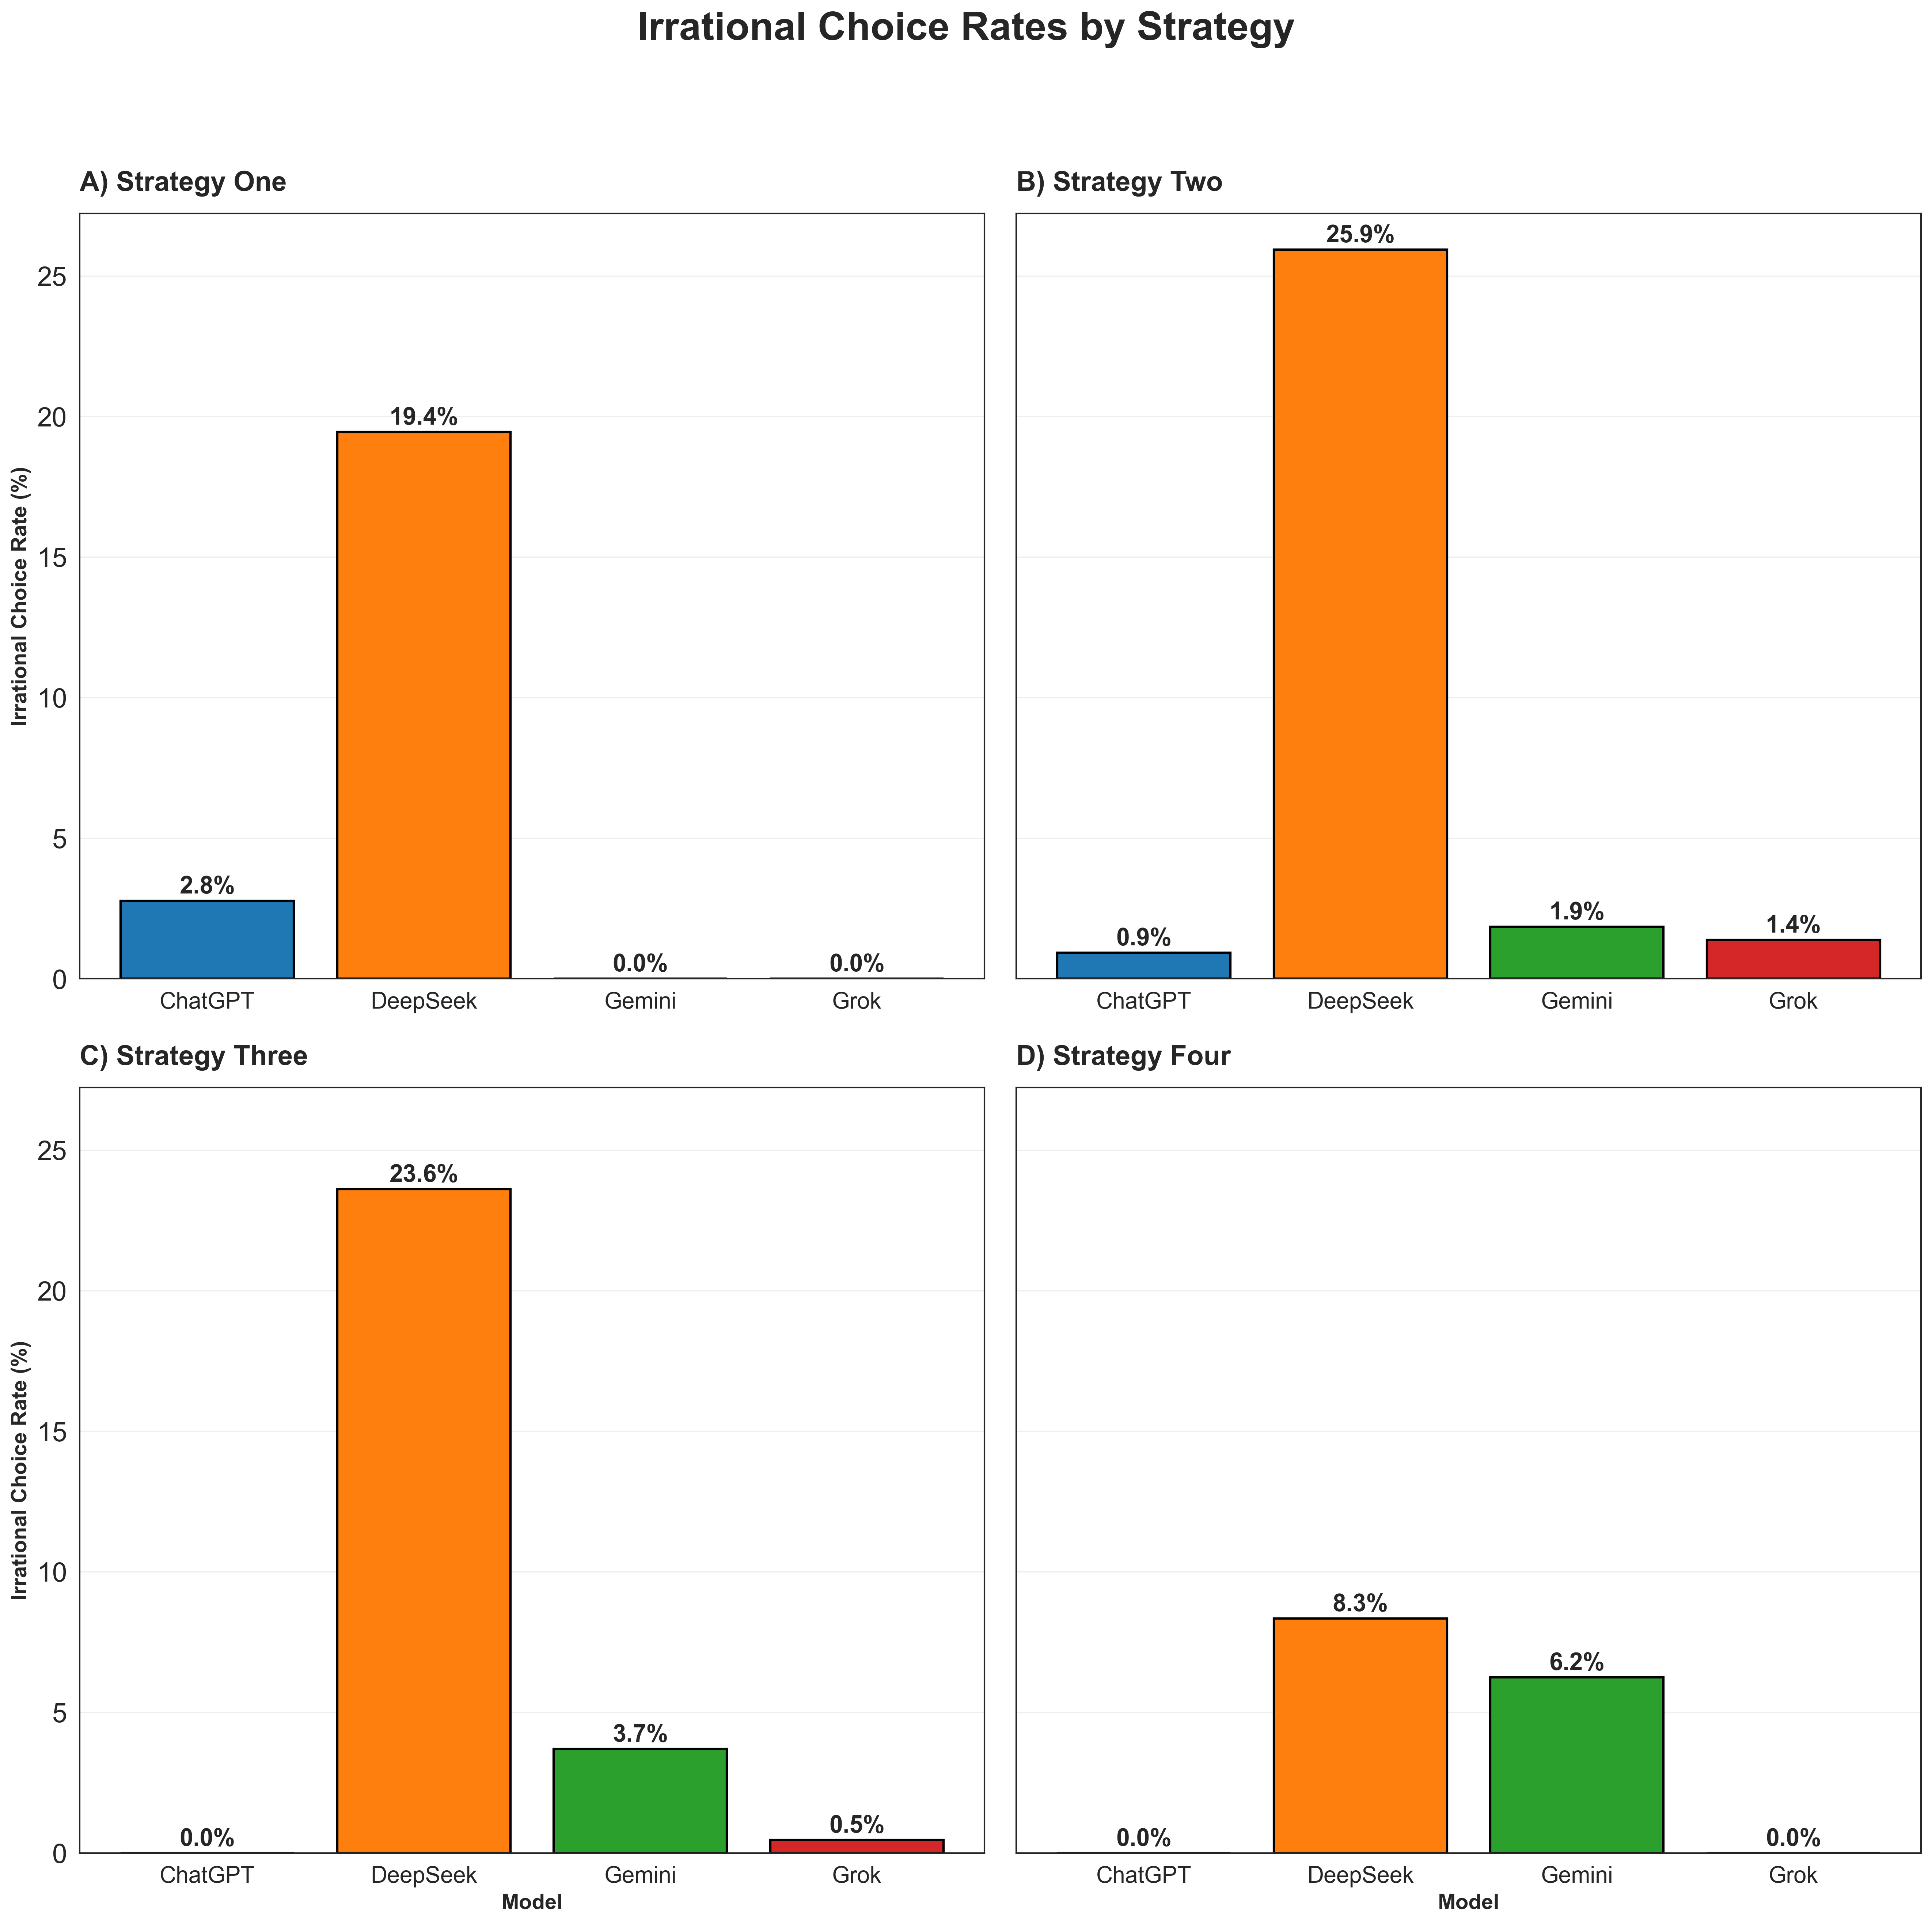

In [8]:
if not results_df.empty:
    freq_data = results_df.groupby(['strategy', 'model'])['irrational_choice'].agg([
        ('irrational_rate', 'mean')
    ]).reset_index()
    freq_data['irrational_percentage'] = freq_data['irrational_rate'] * 100
    
    strategies_sorted = sorted(freq_data['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies_sorted)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 18), sharex=True, sharey=True)
    axes_flat = axes.flatten()
    
    for idx, strategy in enumerate(strategies_sorted):
        ax = axes_flat[idx]
        strategy_data = freq_data[freq_data['strategy'] == strategy].sort_values('model')
        
        bars = ax.bar(
            strategy_data['model'],
            strategy_data['irrational_percentage'],
            color=[MODEL_COLORS[m] for m in strategy_data['model']],
            edgecolor='black',
            linewidth=1.5
        )
        
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.1,
                    f'{height:.1f}%', ha='center', va='bottom', 
                    fontsize=16, fontweight='bold')
        
        ax.set_title(f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}', 
                    fontsize=18, fontweight='bold', loc='left', pad=15)
        ax.grid(axis='y', alpha=0.3)
        ax.tick_params(axis='x', rotation=0, labelsize=15, labelbottom=True)
    
    # Y-axis labels on left column
    if axes.ndim == 1:
        axes[0].set_ylabel('Irrational Choice Rate (%)', fontsize=14, fontweight='bold')
    else:
        for ax in axes[:, 0]: 
            ax.set_ylabel('Irrational Choice Rate (%)', fontsize=14, fontweight='bold')
    
    # X-axis labels on bottom row
    bottom_row = axes if axes.ndim == 1 else axes[-1, :]
    for ax in bottom_row: 
        ax.set_xlabel('Model', fontsize=14, fontweight='bold')
    
    # Hide unused panels
    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)
    
    fig.suptitle('Irrational Choice Rates by Strategy', 
                fontsize=26, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

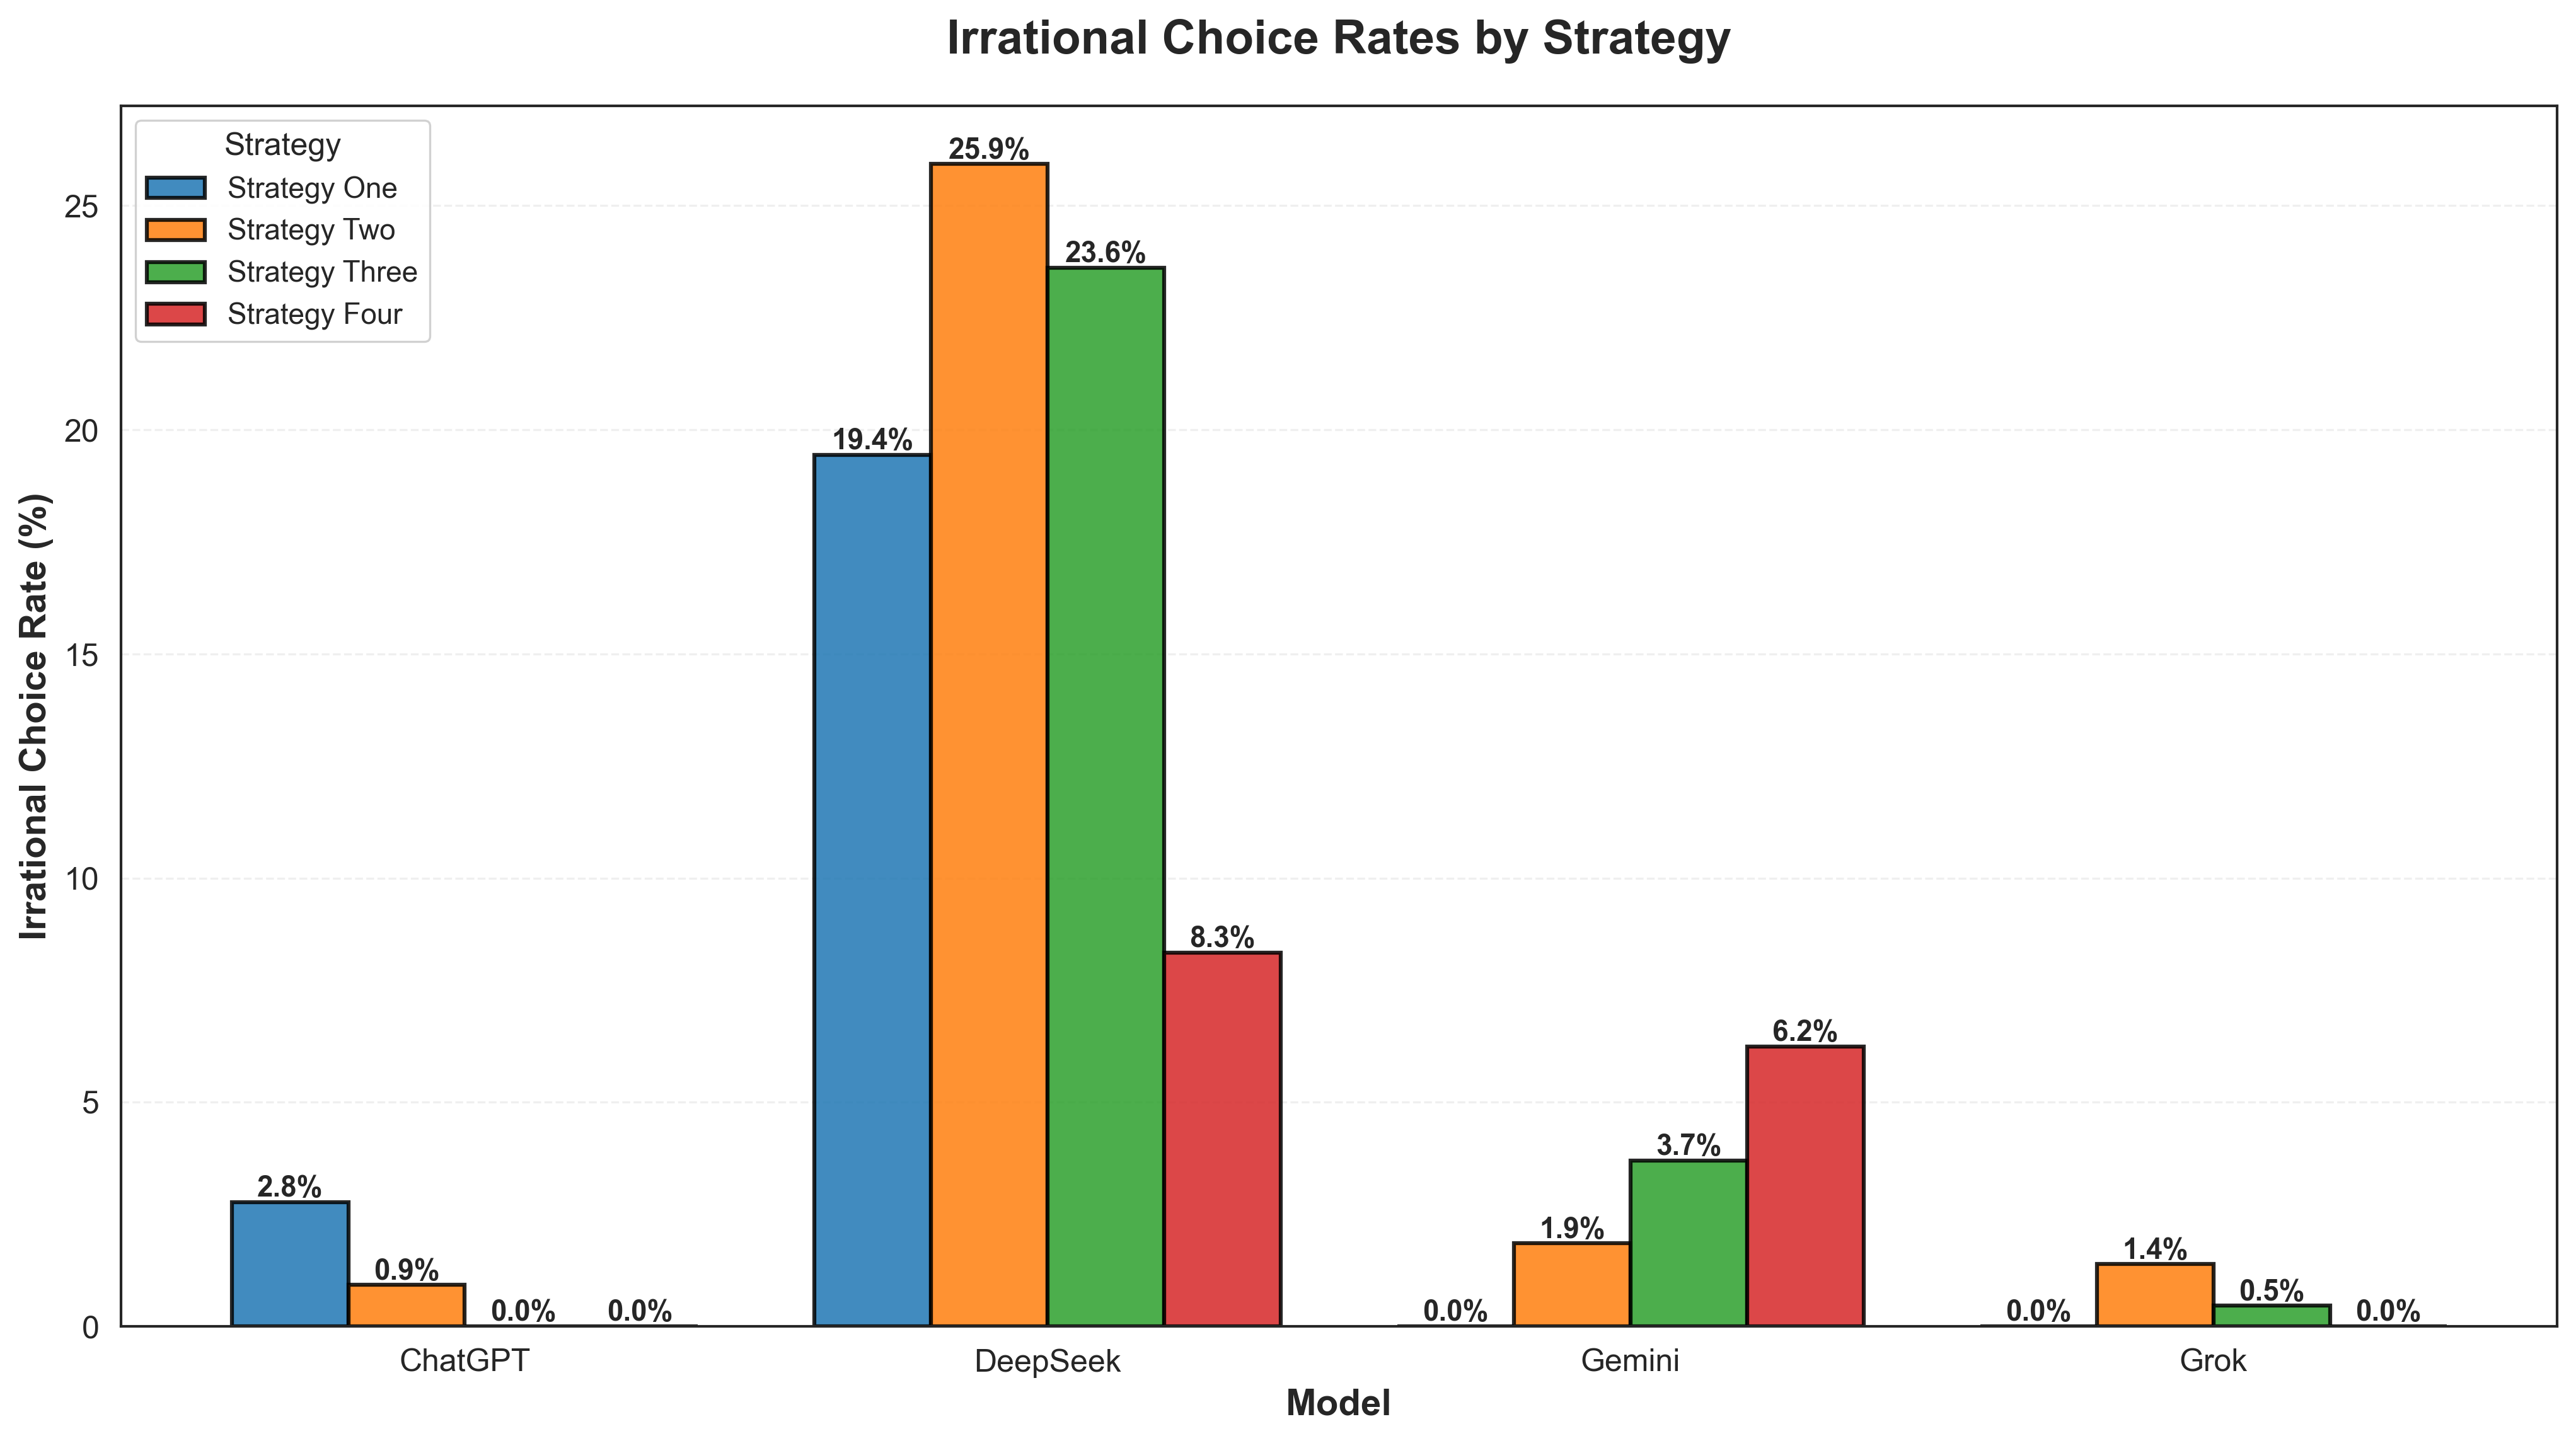

In [9]:
if not results_df.empty:
    freq_data = results_df.groupby(['strategy', 'model'])['irrational_choice'].agg([
        ('irrational_rate', 'mean')
    ]).reset_index()
    freq_data['irrational_percentage'] = freq_data['irrational_rate'] * 100
    
    strategies_sorted = sorted(freq_data['strategy'].unique(), key=extract_strategy_number)
    models_sorted = sorted(freq_data['model'].unique())
    n_strategies = len(strategies_sorted)
    n_models = len(models_sorted)
    
    # Create single panel
    fig, ax = plt.subplots(figsize=(14, 8))
    
    # Set up bar positions
    x = np.arange(n_models)
    width = 0.8 / n_strategies  # Width of each bar
    
    # Plot bars for each strategy
    for idx, strategy in enumerate(strategies_sorted):
        strategy_data = freq_data[freq_data['strategy'] == strategy].sort_values('model')
        
        # Calculate offset for grouped bars
        offset = width * (idx - n_strategies/2 + 0.5)
        
        bars = ax.bar(
            x + offset,
            strategy_data['irrational_percentage'],
            width,
            label=strategy.replace("_", " ").title(),
            edgecolor='black',
            linewidth=1.5,
            alpha=0.85
        )
        
        # Add percentage labels on bars
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}%', ha='center', va='bottom', 
                    fontsize=11, fontweight='bold')
    
    # Customize plot
    ax.set_xlabel('Model', fontsize=14, fontweight='bold')
    ax.set_ylabel('Irrational Choice Rate (%)', fontsize=14, fontweight='bold')
    ax.set_title('Irrational Choice Rates by Strategy', 
                fontsize=18, fontweight='bold', pad=20)
    ax.set_xticks(x)
    ax.set_xticklabels(models_sorted, fontsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.legend(title='Strategy', fontsize=11, title_fontsize=12, 
             loc='upper left', framealpha=0.9)
    
    plt.tight_layout()
    plt.show()


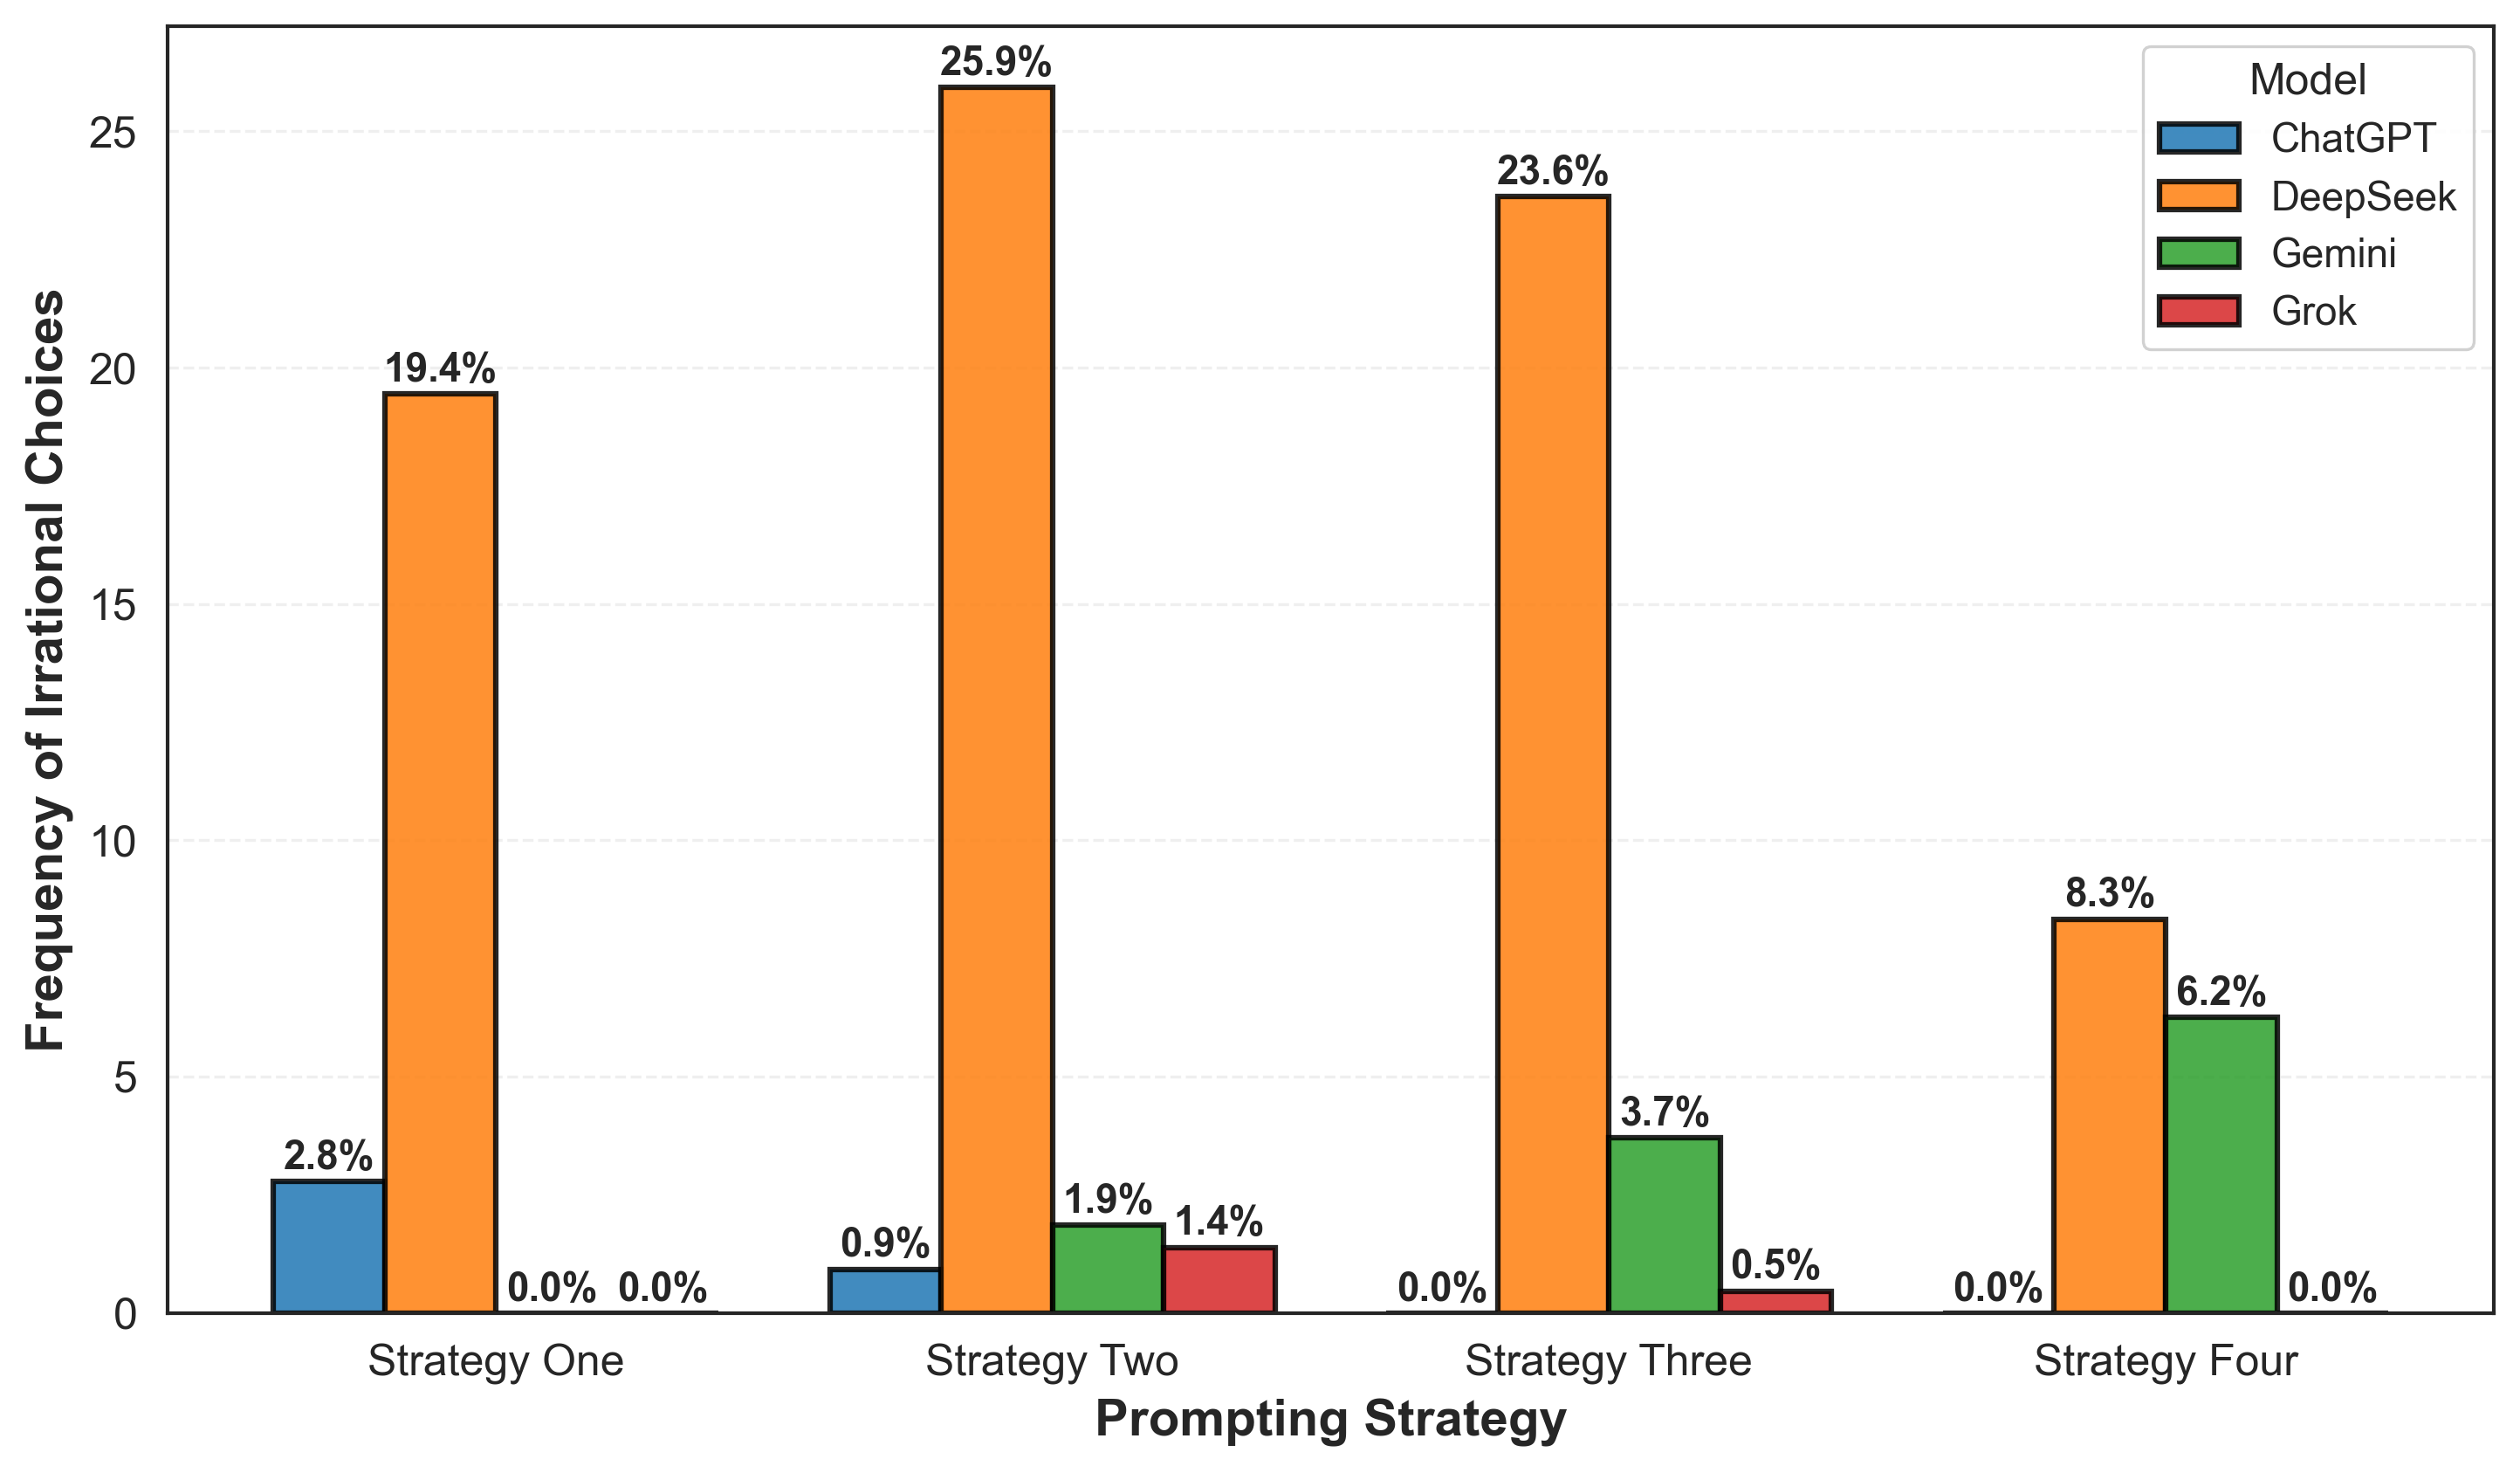

In [10]:
if not results_df.empty:
    freq_data = results_df.groupby(['strategy', 'model'])['irrational_choice'].agg([
        ('irrational_rate', 'mean')
    ]).reset_index()
    freq_data['irrational_percentage'] = freq_data['irrational_rate'] * 100

    strategies_sorted = sorted(freq_data['strategy'].unique(), key=extract_strategy_number)
    models_sorted = sorted(freq_data['model'].unique())
    n_strategies = len(strategies_sorted)
    n_models = len(models_sorted)

    # Create single panel (smaller figure so text appears bigger relative to the plot)
    fig, ax = plt.subplots(figsize=(10, 6))

    # Set up bar positions - now based on strategies
    x = np.arange(n_strategies)
    width = 0.8 / n_models  # Width of each bar

    # Plot bars for each model
    for idx, model in enumerate(models_sorted):
        model_data = (
            freq_data[freq_data['model'] == model]
            .sort_values(
                'strategy',
                key=lambda col: col.map({s: i for i, s in enumerate(strategies_sorted)})
            )
        )

        # Calculate offset for grouped bars
        offset = width * (idx - n_models/2 + 0.5)

        bars = ax.bar(
            x + offset,
            model_data['irrational_percentage'],
            width,
            label=model,
            color=MODEL_COLORS.get(model, None),
            edgecolor='black',
            linewidth=1.5,
            alpha=0.85
        )

        # Add percentage labels on bars
        for bar in bars:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2.0,
                height + 0.1,
                f'{height:.1f}%',
                ha='center',
                va='bottom',
                fontsize=11,
                fontweight='bold'
            )

    # Customize plot
    ax.set_xlabel('Prompting Strategy', fontsize=14, fontweight='bold')
    ax.set_ylabel('Frequency of Irrational Choices', fontsize=14, fontweight='bold')

    # Remove the title (safe even if something else set it earlier)
    ax.set_title('')  # Axes.set_title sets/clears the axes title [web:15]

    ax.set_xticks(x)
    ax.set_xticklabels(
        [s.replace("_", " ").title() for s in strategies_sorted],
        fontsize=12,
        rotation=0,
        ha='center'
    )  # fully horizontal tick labels [web:8]

    ax.tick_params(axis='y', labelsize=12)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.legend(title='Model', fontsize=11, title_fontsize=12,
              loc='upper right', framealpha=0.9)

    plt.tight_layout()
    plt.show()


## Mean Infection Rate Selected

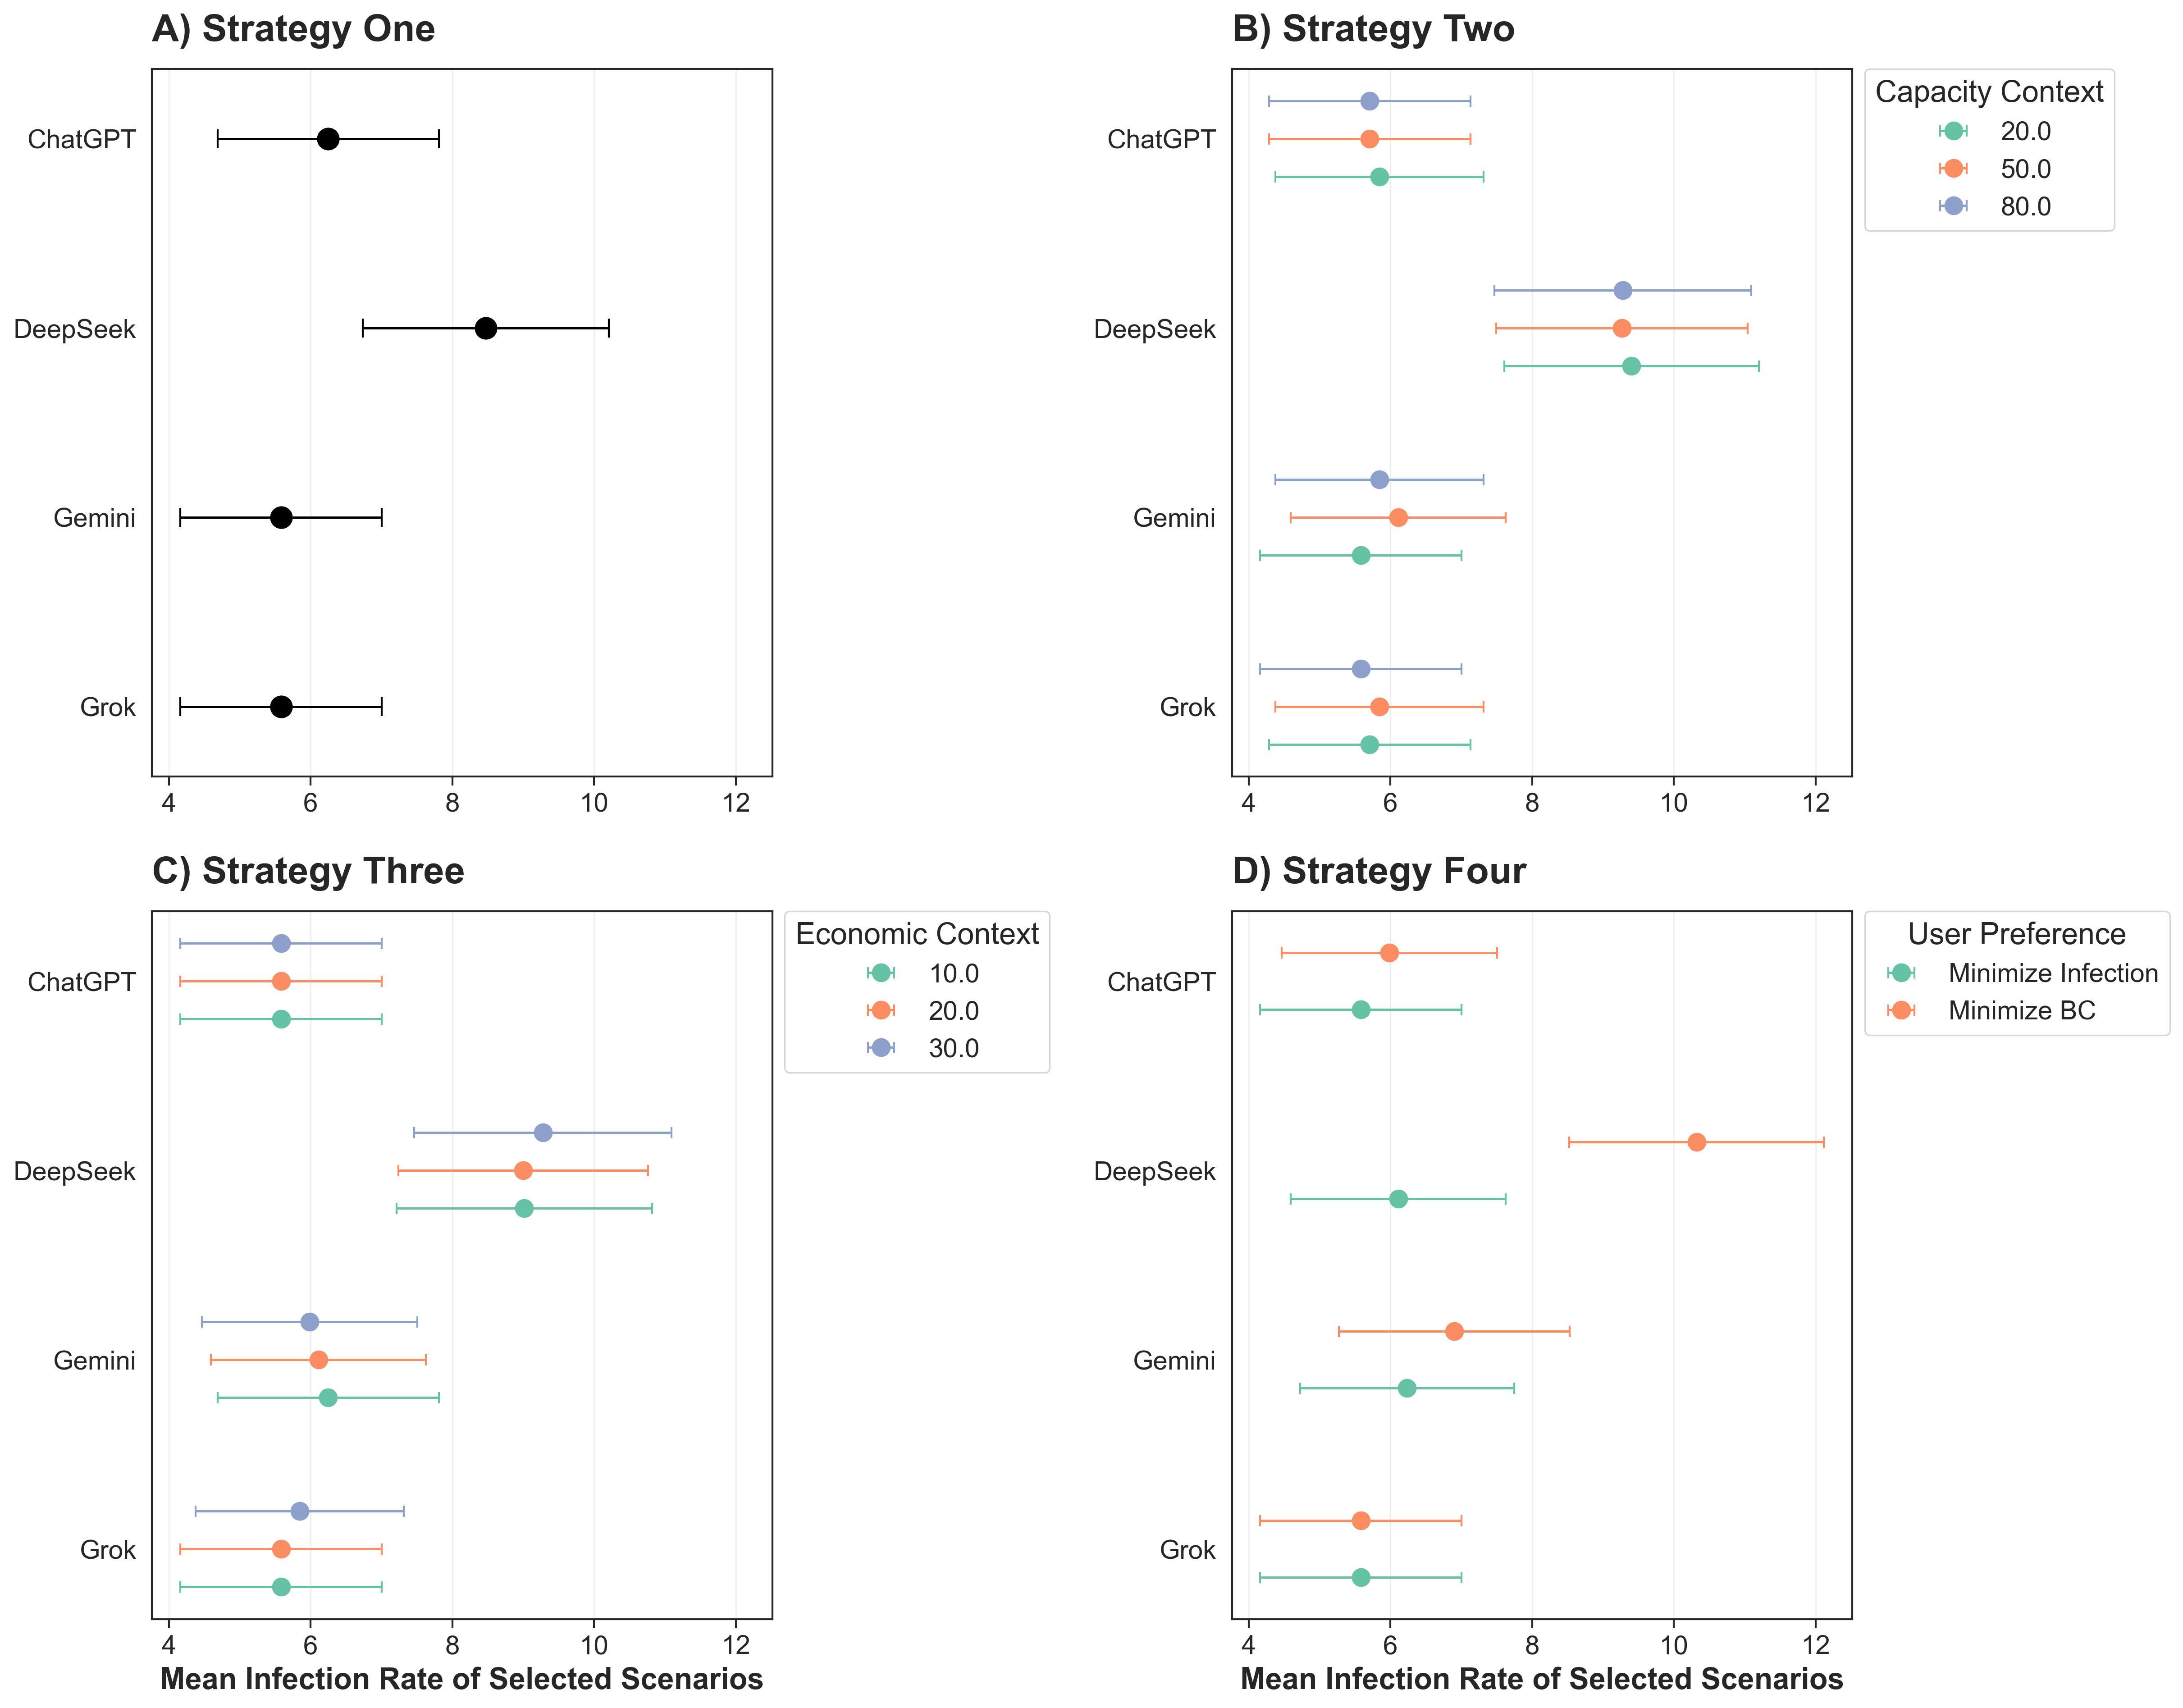

In [11]:
if not results_df.empty:
    strategies_sorted = sorted(results_df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies_sorted)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))

    global_param_order = sorted(results_df['model'].unique(), reverse=True)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=FIG_SIZE_MULTI, sharex=True, sharey=True)
    axes_flat = axes.flatten()

    for idx, strategy in enumerate(strategies_sorted):
        ax = axes_flat[idx]
        strategy_data = results_df[results_df['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)

        if context_col and context_col in strategy_data.columns:
            group_cols = ['model', context_col]
        else:
            group_cols = ['model']

        plot_df = calculate_errorbar_data(strategy_data, 'infection_rate_selected', group_cols)
        if plot_df.empty:
            continue

        if len(group_cols) == 1:
            plot_df = plot_df.set_index('model').reindex(global_param_order).reset_index()
            y_positions = range(len(plot_df))
            ax.errorbar(
                plot_df['mean'], y_positions,
                xerr=[plot_df['ci_lower'], plot_df['ci_upper']],
                fmt='o', markersize=11, color='black', capsize=5
            )
            for y, model_name in zip(y_positions, plot_df['model']):
                if model_name in MODEL_COLORS:
                    ax.plot(
                        plot_df.loc[plot_df['model'] == model_name, 'mean'], y,
                        'o', color=MODEL_COLORS[model_name], markersize=11
                    )
            ax.set_yticks(list(y_positions))
            ax.set_yticklabels(plot_df['model'], fontsize=16)
        else:
            secondary_col = context_col
            secondary_values = sorted(plot_df[secondary_col].unique())
            context_colors = sns.color_palette("Set2", len(secondary_values))

            for i, sec_val in enumerate(secondary_values):
                subset = plot_df[plot_df[secondary_col] == sec_val]
                subset = subset.set_index('model').reindex(global_param_order)
                y_base = np.arange(len(global_param_order))

                bar_height = 0.6
                bar_spacing = bar_height / max(1, len(secondary_values))
                y_offset = (i - len(secondary_values)/2 + 0.5) * bar_spacing
                y_final = y_base + y_offset

                ax.errorbar(
                    subset['mean'], y_final,
                    xerr=[subset['ci_lower'], subset['ci_upper']],
                    fmt='o', markersize=9,
                    color=context_colors[i],
                    label=str(sec_val).replace('_', ' ').title(),
                    capsize=3
                )

            ax.set_yticks(np.arange(len(global_param_order)))
            ax.set_yticklabels(global_param_order, fontsize=16)
            legend_title = get_legend_title(context_col)
            ax.legend(
                title=legend_title,
                bbox_to_anchor=(1.02, 1),
                loc='upper left',
                borderaxespad=0,
                fontsize=14,
                title_fontsize=16
            )

        ax.set_title(
            f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}',
            fontsize=20, fontweight='bold', loc='left', pad=15
        )
        ax.grid(axis='x', alpha=0.3)

        # Bigger tick labels for both axes
        ax.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)  # tick_params labelsize [web:36]
        ax.tick_params(axis='y', labelsize=14, labelleft=True)

    # X-axis labels on bottom row
    bottom_row = axes_flat if axes.ndim == 1 else axes[-1, :]
    for ax in bottom_row:
        ax.set_xlabel(
            'Mean Infection Rate of Selected Scenarios',
            fontsize=16, fontweight='bold'
        )  # set_xlabel fontsize supported [web:40]

    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    # Remove main title
    fig.suptitle('')  # suptitle sets/clears figure-level title [web:32]

    leg = ax.legend(
        title=legend_title, bbox_to_anchor=(1.02, 1), loc='upper left',
        borderaxespad=0, fontsize=14, title_fontsize=16
    )

    for t in leg.get_texts():
        if t.get_text() == "Minimize Npi":
            t.set_text("Minimize BC")  # edit legend text objects [web:68]


    plt.tight_layout(rect=[0, 0, 0.92, 0.95])
    plt.show()


## Mean NPI Level Selected

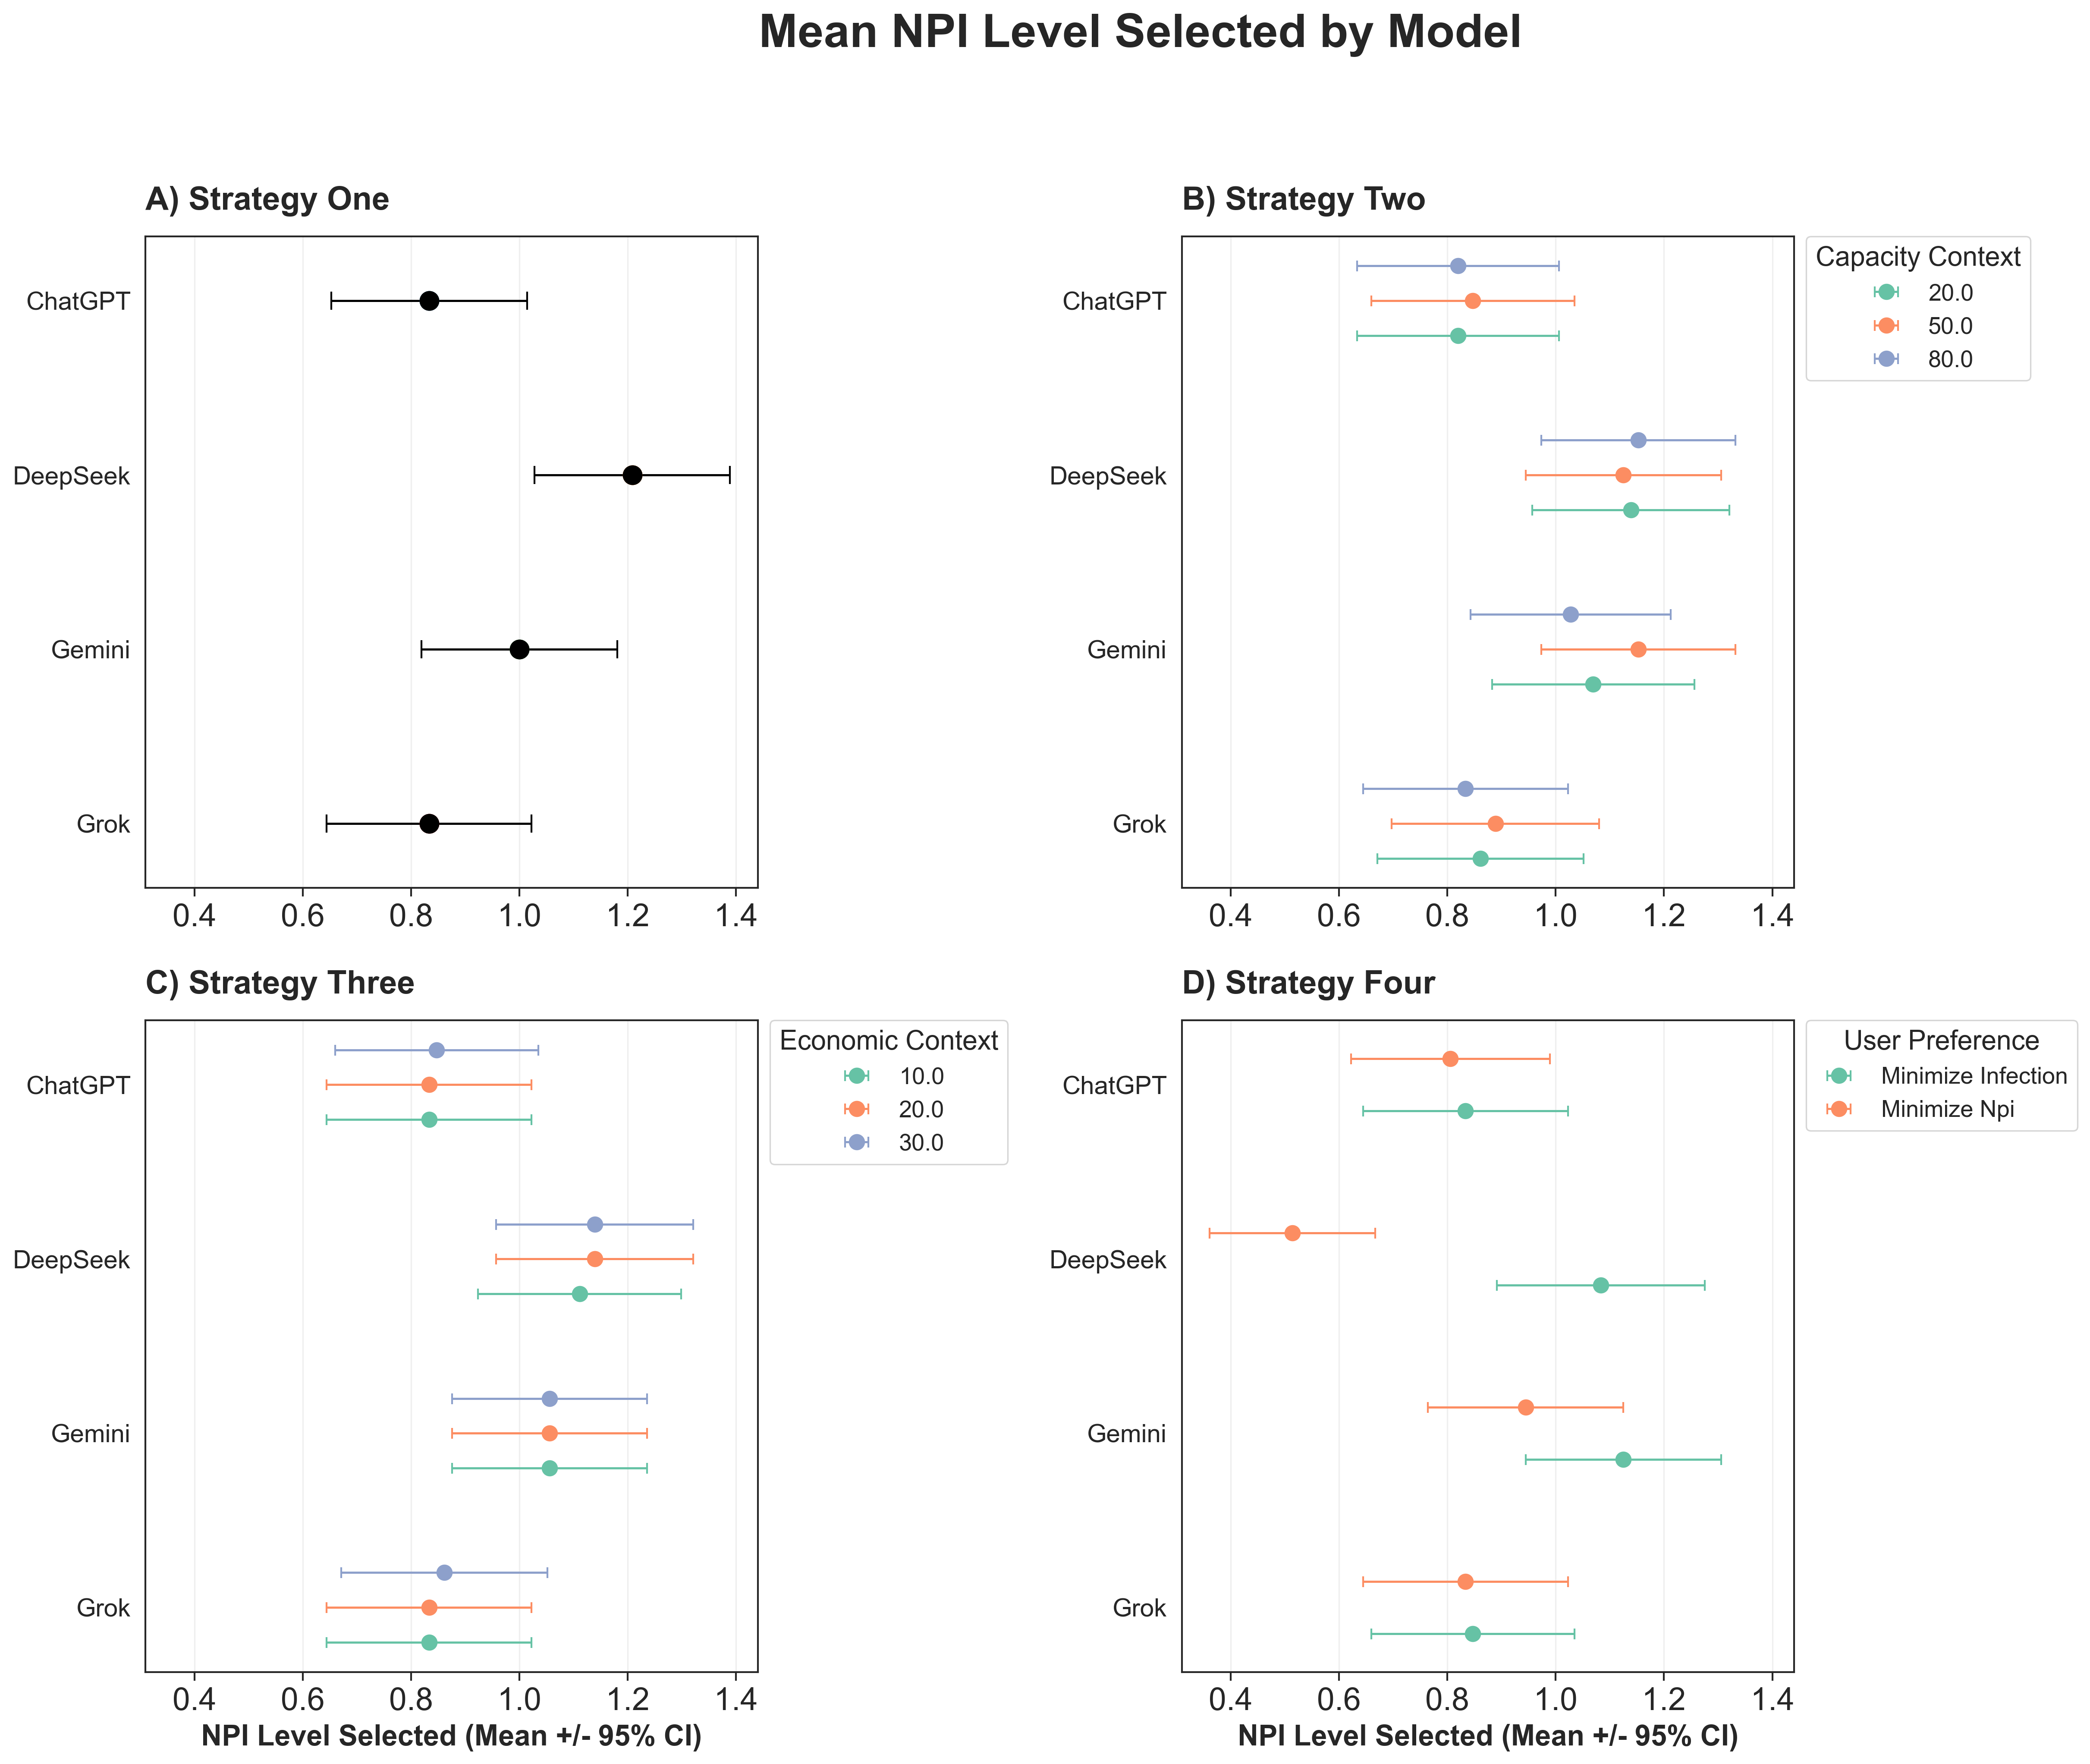

In [12]:
if not results_df.empty:
    strategies_sorted = sorted(results_df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies_sorted)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))
    
    global_param_order = sorted(results_df['model'].unique(), reverse=True)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=FIG_SIZE_MULTI, sharex=True, sharey=True)
    axes_flat = axes.flatten()
    
    for idx, strategy in enumerate(strategies_sorted):
        ax = axes_flat[idx]
        strategy_data = results_df[results_df['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)
        
        if context_col and context_col in strategy_data.columns:
            group_cols = ['model', context_col]
        else:
            group_cols = ['model']
        
        plot_df = calculate_errorbar_data(strategy_data, 'npi_level_selected', group_cols)
        if plot_df.empty: 
            continue
        
        if len(group_cols) == 1:
            plot_df = plot_df.set_index('model').reindex(global_param_order).reset_index()
            y_positions = range(len(plot_df))
            ax.errorbar(
                plot_df['mean'], y_positions,
                xerr=[plot_df['ci_lower'], plot_df['ci_upper']],
                fmt='o', markersize=10, color='black', capsize=5
            )
            for y, model_name in zip(y_positions, plot_df['model']):
                if model_name in MODEL_COLORS:
                    ax.plot(plot_df.loc[plot_df['model']==model_name, 'mean'], y, 
                           'o', color=MODEL_COLORS[model_name], markersize=10)
            ax.set_yticks(list(y_positions))
            ax.set_yticklabels(plot_df['model'], fontsize=14)
        else:
            secondary_col = context_col
            secondary_values = sorted(plot_df[secondary_col].unique())
            context_colors = sns.color_palette("Set2", len(secondary_values))
            
            for i, sec_val in enumerate(secondary_values):
                subset = plot_df[plot_df[secondary_col] == sec_val]
                subset = subset.set_index('model').reindex(global_param_order)
                y_base = np.arange(len(global_param_order))
                
                bar_height = 0.6
                bar_spacing = bar_height / max(1, len(secondary_values))
                y_offset = (i - len(secondary_values)/2 + 0.5) * bar_spacing
                y_final = y_base + y_offset
                
                ax.errorbar(
                    subset['mean'], y_final,
                    xerr=[subset['ci_lower'], subset['ci_upper']],
                    fmt='o', markersize=8, 
                    color=context_colors[i],
                    label=str(sec_val).replace('_', ' ').title(),
                    capsize=3
                )
            ax.set_yticks(np.arange(len(global_param_order)))
            ax.set_yticklabels(global_param_order, fontsize=14)
            legend_title = get_legend_title(context_col)
            ax.legend(title=legend_title, bbox_to_anchor=(1.02, 1), loc='upper left', 
                     borderaxespad=0, fontsize=13, title_fontsize=15)
        
        ax.set_title(f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}', 
                    fontsize=18, fontweight='bold', loc='left', pad=15)
        ax.grid(axis='x', alpha=0.3)
        ax.tick_params(axis='y', labelleft=True)
        ax.tick_params(axis='x', bottom=True, labelbottom=True)
    
    bottom_row = axes_flat if axes.ndim == 1 else axes[-1, :]
    for ax in bottom_row: 
        ax.set_xlabel('NPI Level Selected (Mean +/- 95% CI)', 
                     fontsize=16, fontweight='bold')
    
    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)
    
    fig.suptitle('Mean NPI Level Selected by Model', 
                fontsize=26, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 0.92, 0.95])
    plt.show()

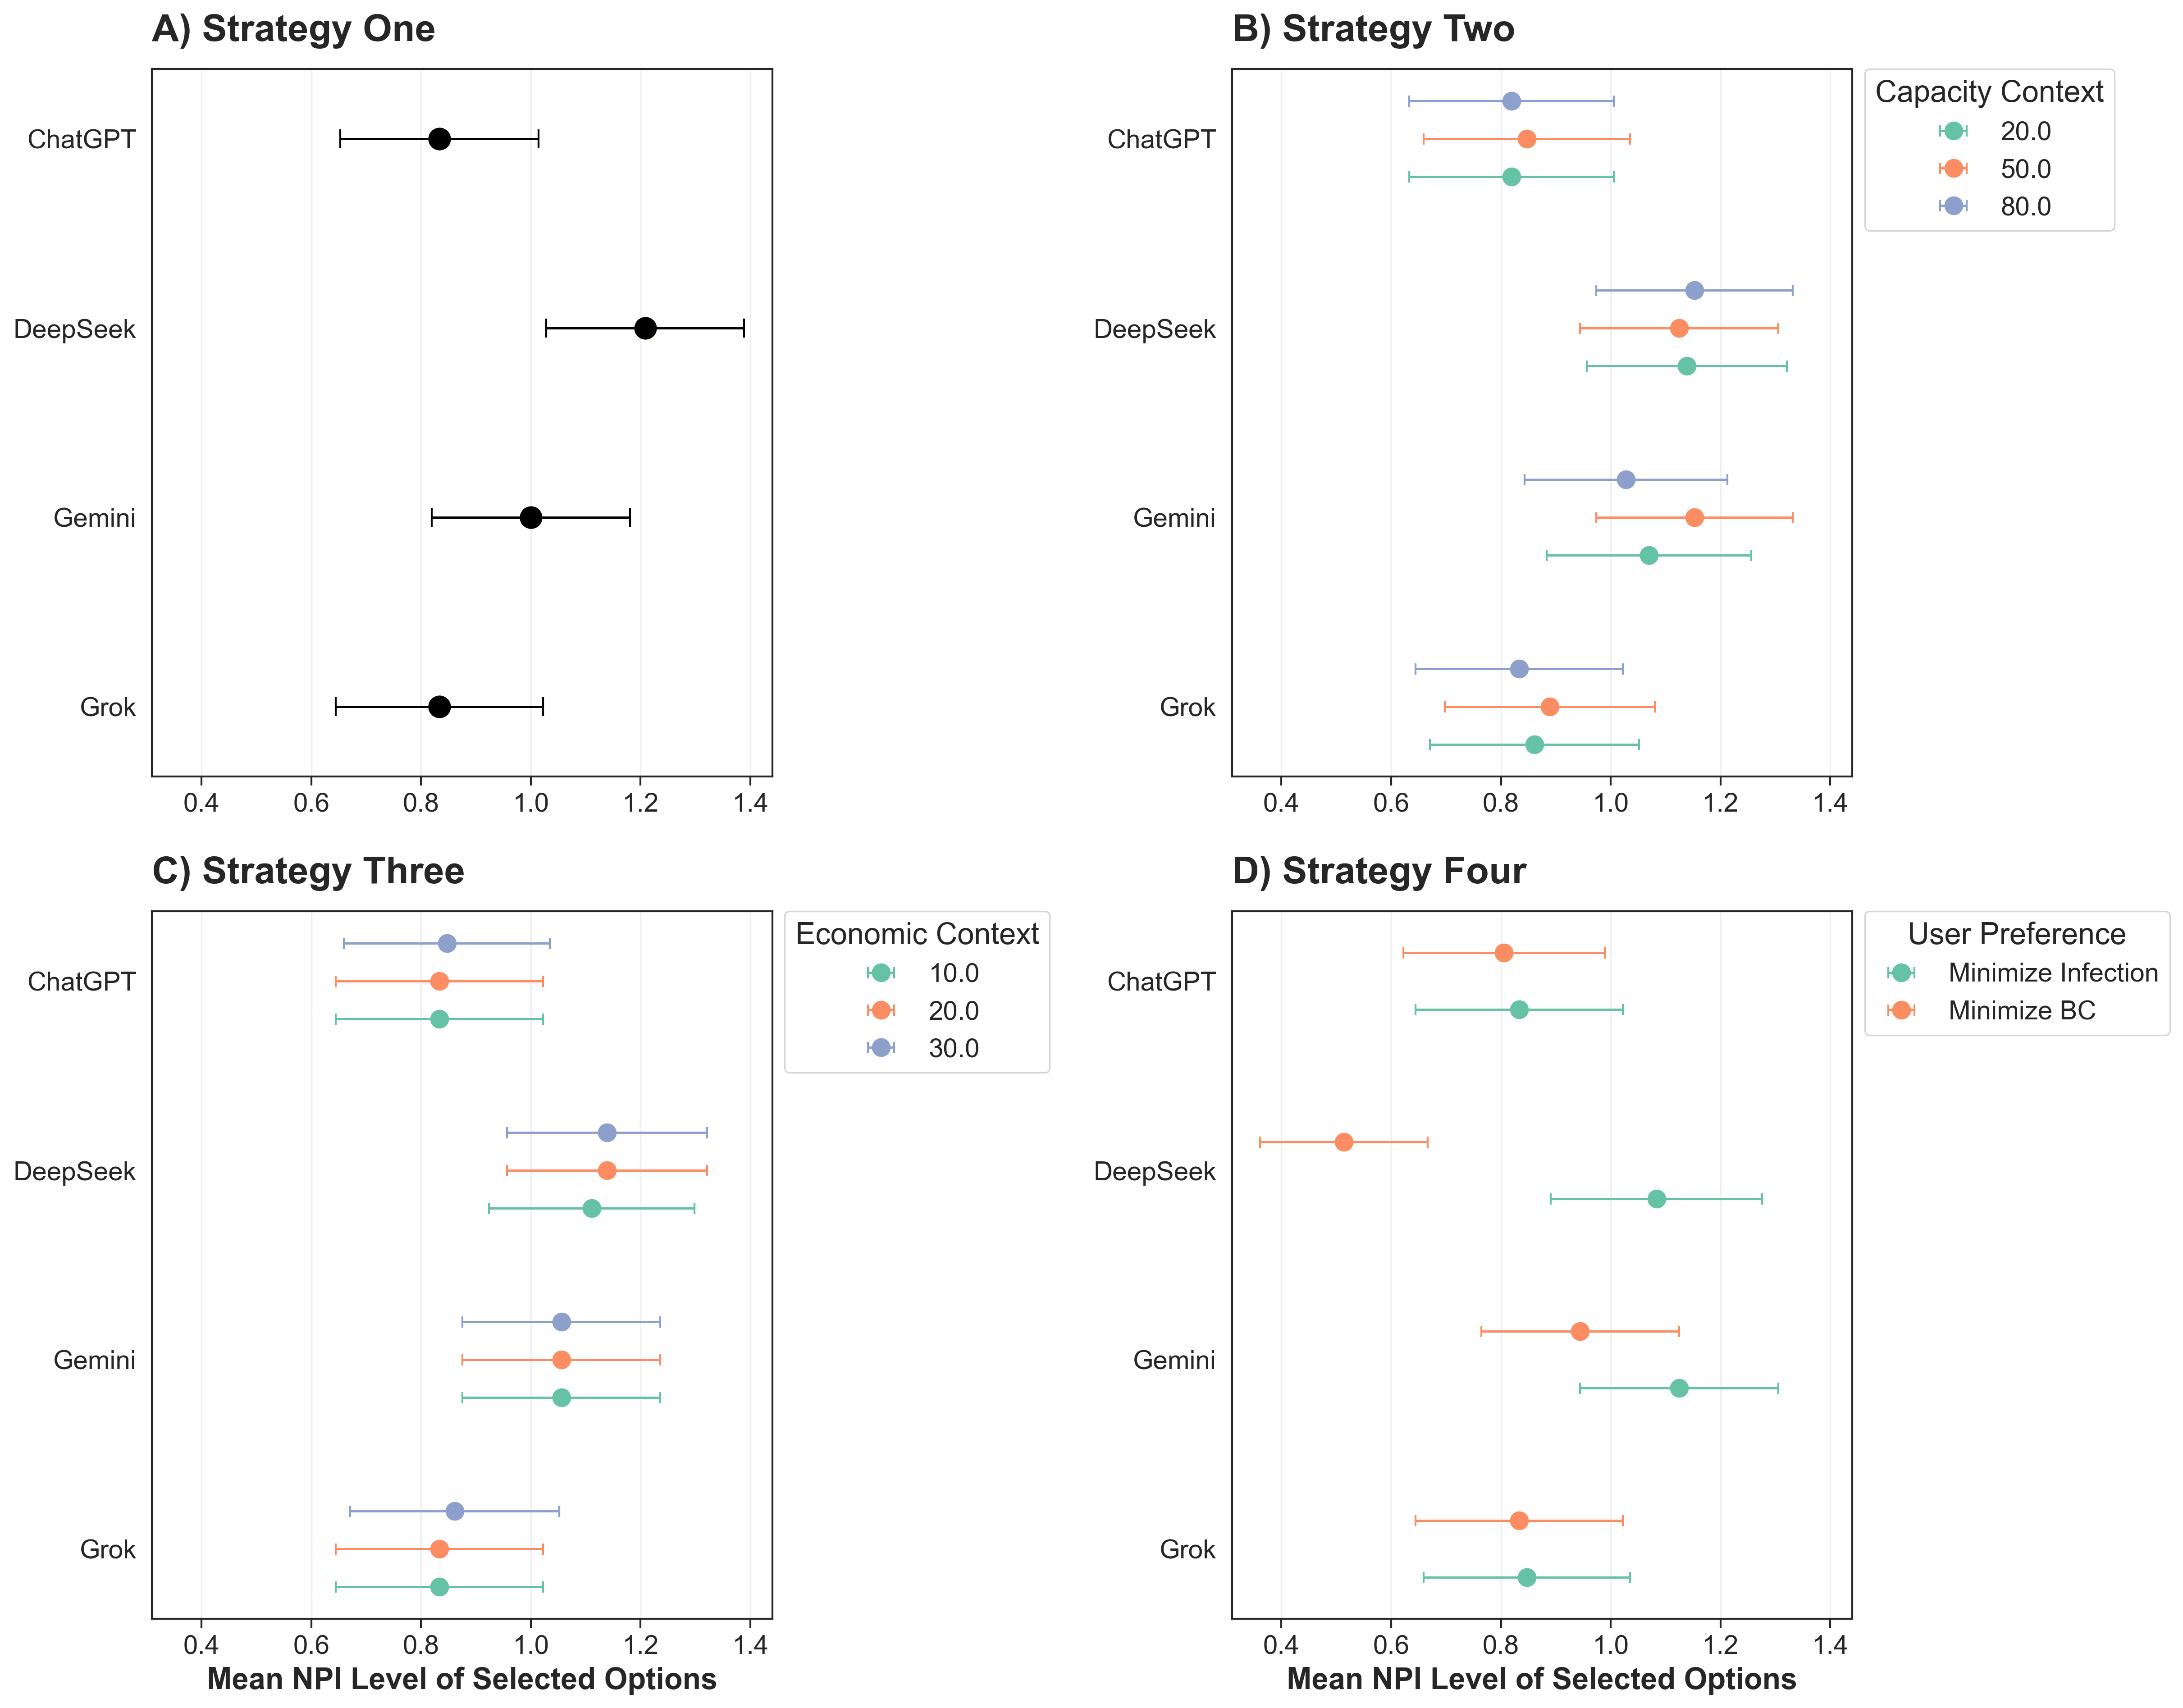

In [13]:
if not results_df.empty:
    strategies_sorted = sorted(results_df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies_sorted)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))

    global_param_order = sorted(results_df['model'].unique(), reverse=True)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=FIG_SIZE_MULTI, sharex=True, sharey=True)
    axes_flat = axes.flatten()

    for idx, strategy in enumerate(strategies_sorted):
        ax = axes_flat[idx]
        strategy_data = results_df[results_df['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)

        if context_col and context_col in strategy_data.columns:
            group_cols = ['model', context_col]
        else:
            group_cols = ['model']

        plot_df = calculate_errorbar_data(strategy_data, 'npi_level_selected', group_cols)
        if plot_df.empty:
            continue

        if len(group_cols) == 1:
            plot_df = plot_df.set_index('model').reindex(global_param_order).reset_index()
            y_positions = range(len(plot_df))
            ax.errorbar(
                plot_df['mean'], y_positions,
                xerr=[plot_df['ci_lower'], plot_df['ci_upper']],
                fmt='o', markersize=11, color='black', capsize=5
            )
            for y, model_name in zip(y_positions, plot_df['model']):
                if model_name in MODEL_COLORS:
                    ax.plot(
                        plot_df.loc[plot_df['model'] == model_name, 'mean'], y,
                        'o', color=MODEL_COLORS[model_name], markersize=11
                    )
            ax.set_yticks(list(y_positions))
            ax.set_yticklabels(plot_df['model'], fontsize=16)
        else:
            secondary_col = context_col
            secondary_values = sorted(plot_df[secondary_col].unique())
            context_colors = sns.color_palette("Set2", len(secondary_values))

            for i, sec_val in enumerate(secondary_values):
                subset = plot_df[plot_df[secondary_col] == sec_val]
                subset = subset.set_index('model').reindex(global_param_order)
                y_base = np.arange(len(global_param_order))

                bar_height = 0.6
                bar_spacing = bar_height / max(1, len(secondary_values))
                y_offset = (i - len(secondary_values) / 2 + 0.5) * bar_spacing
                y_final = y_base + y_offset

                ax.errorbar(
                    subset['mean'], y_final,
                    xerr=[subset['ci_lower'], subset['ci_upper']],
                    fmt='o', markersize=9,
                    color=context_colors[i],
                    label=str(sec_val).replace('_', ' ').title(),
                    capsize=3
                )

            ax.set_yticks(np.arange(len(global_param_order)))
            ax.set_yticklabels(global_param_order, fontsize=16)

            legend_title = get_legend_title(context_col)
            leg = ax.legend(
                title=legend_title,
                bbox_to_anchor=(1.02, 1),
                loc='upper left',
                borderaxespad=0,
                fontsize=14,
                title_fontsize=16
            )

            # Option B: rename legend label text after legend creation
            for t in leg.get_texts():
                if t.get_text() == "Minimize Npi":
                    t.set_text("Minimize BC")  # change legend label in-place [web:68]

        ax.set_title(
            f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}',
            fontsize=20, fontweight='bold', loc='left', pad=15
        )

        ax.grid(axis='x', alpha=0.3)

        # Larger tick labels
        ax.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)  # labelsize via tick_params [web:36]
        ax.tick_params(axis='y', labelsize=14, labelleft=True)                 # labelsize via tick_params [web:36]

    bottom_row = axes_flat if axes.ndim == 1 else axes[-1, :]
    for ax in bottom_row:
        ax.set_xlabel(
            'Mean NPI Level of Selected Options',
            fontsize=16, fontweight='bold'
        )

    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    # Remove main/figure title
    fig.suptitle('')  # suptitle can be set/cleared at the figure level [web:32]

    plt.tight_layout(rect=[0, 0, 0.92, 0.95])
    plt.show()


## NPI vs Infection Scatter Plot

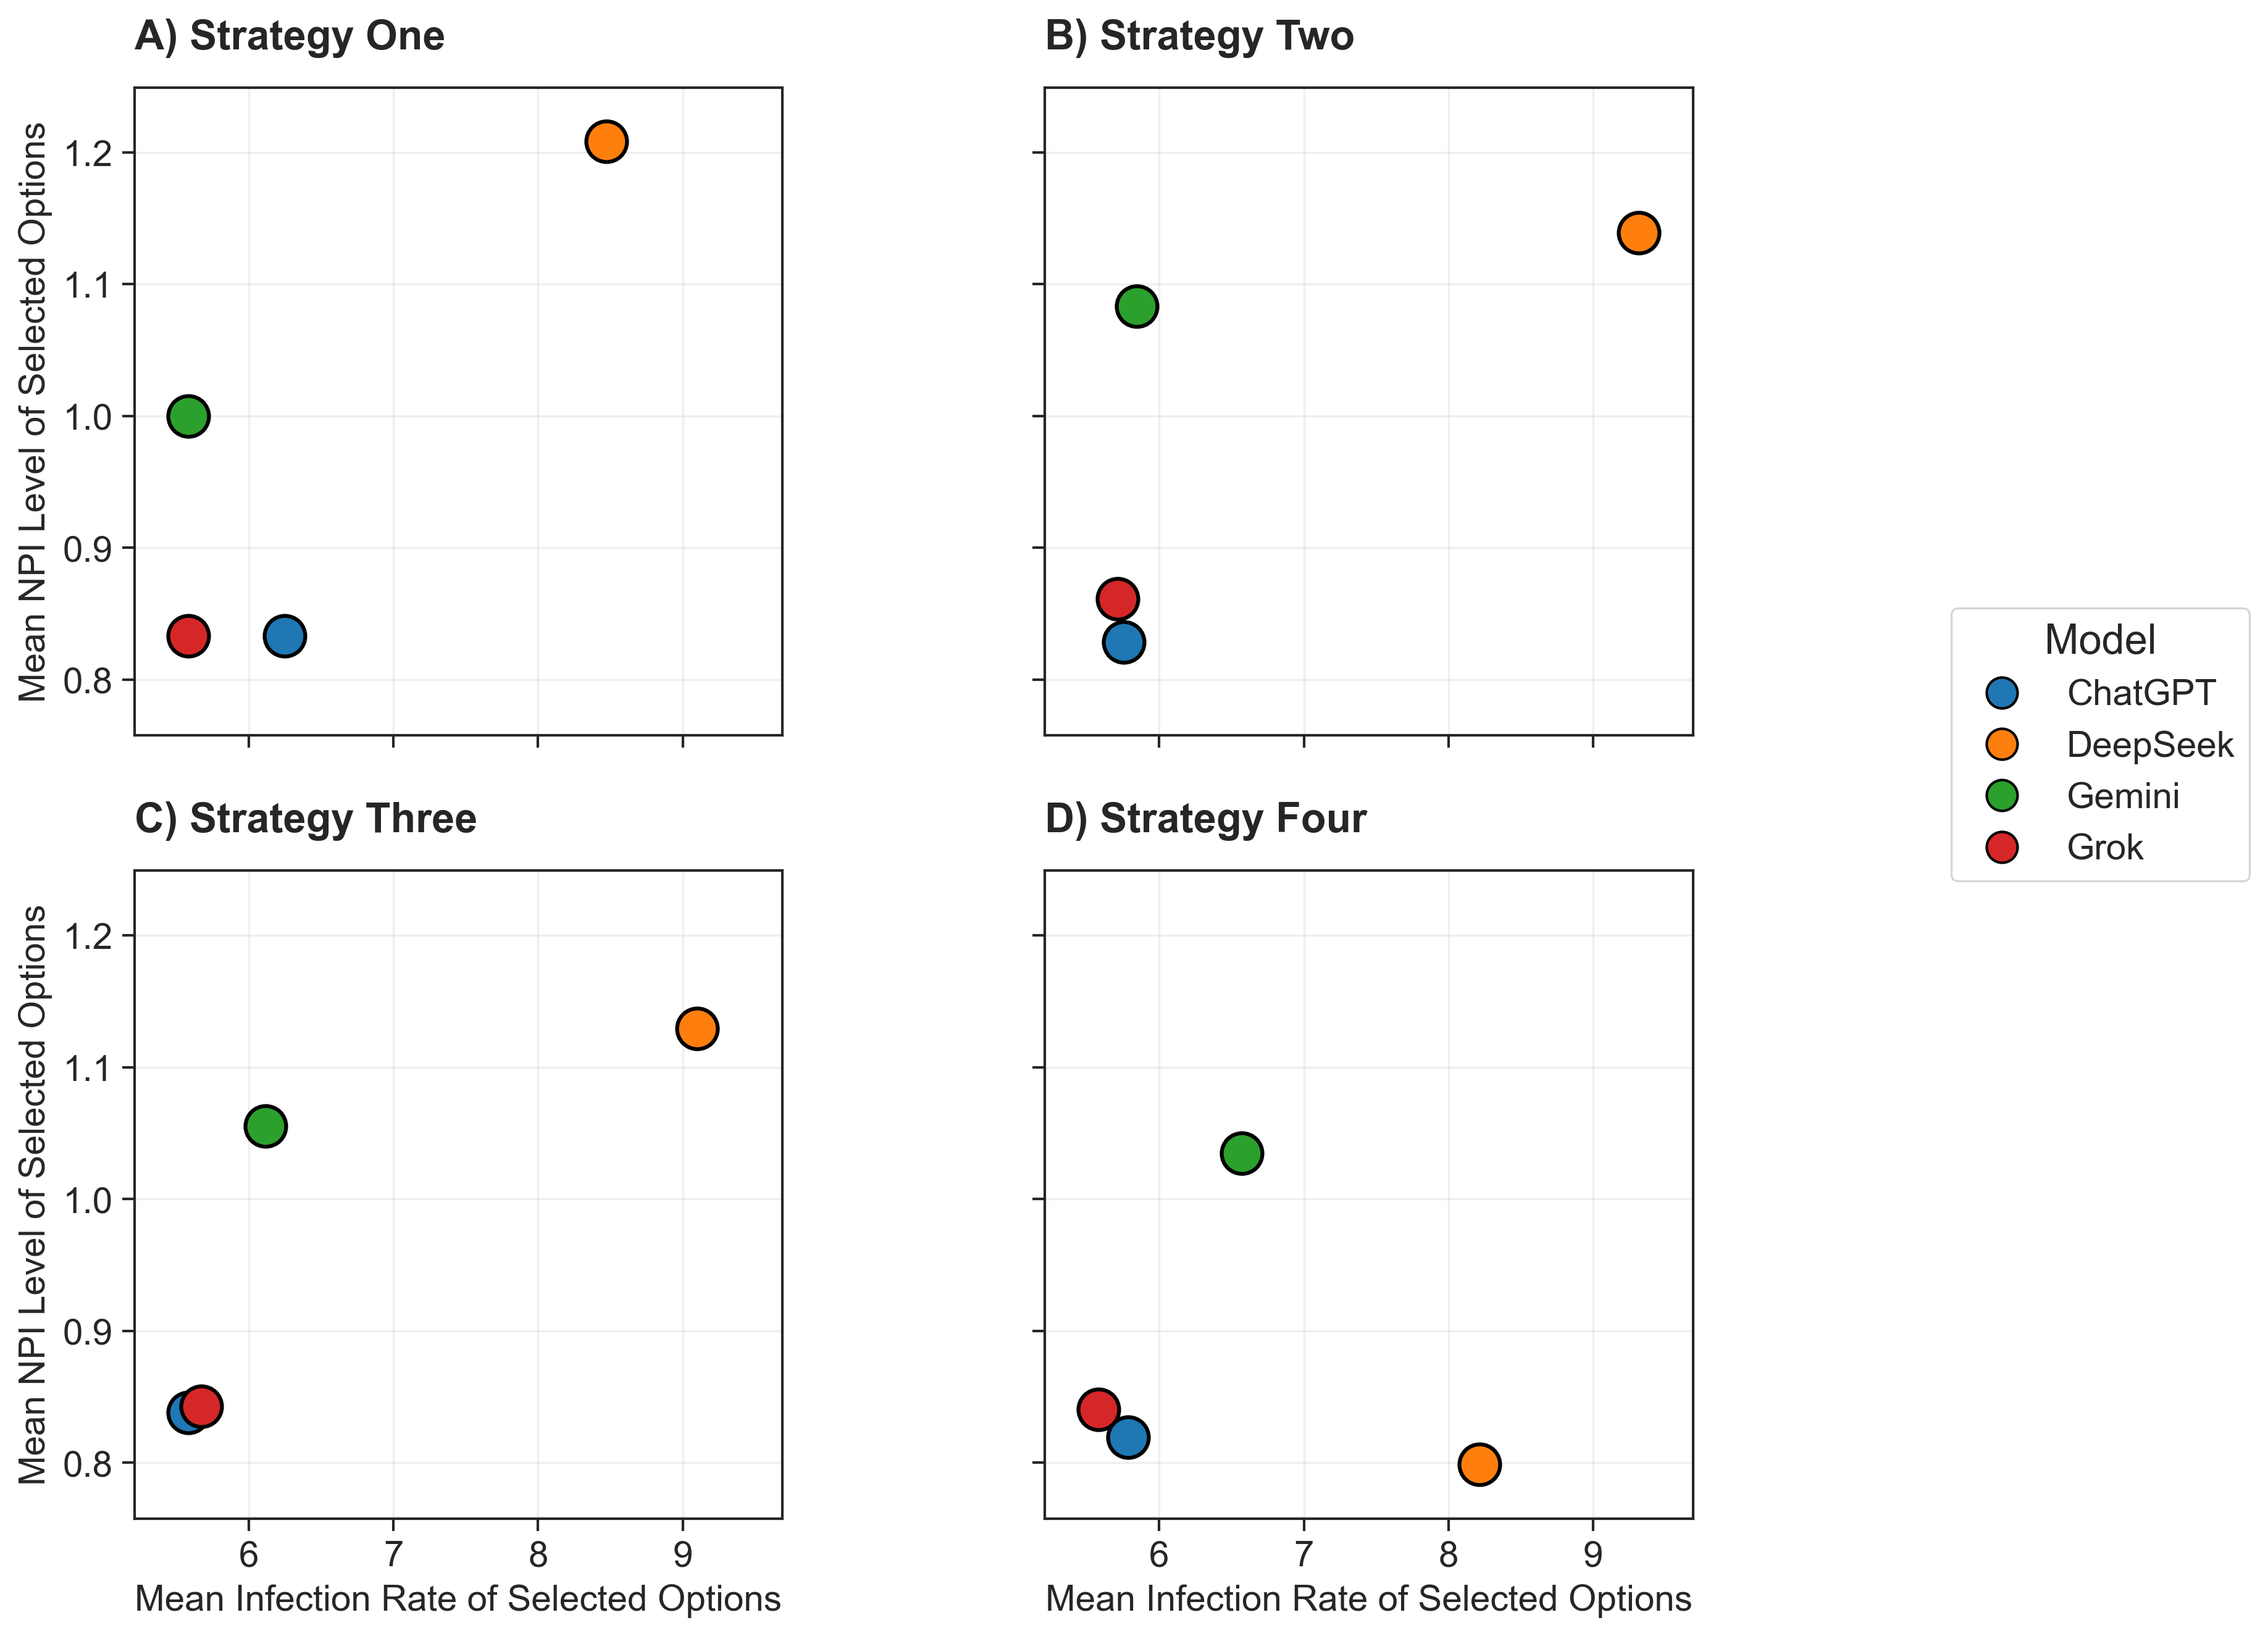

In [14]:
if not results_df.empty:
    strategies_sorted = sorted(results_df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies_sorted)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))

    all_means = results_df.groupby(['strategy', 'model'])[['infection_rate_selected', 'npi_level_selected']].mean()
    x_min, x_max = all_means['infection_rate_selected'].min(), all_means['infection_rate_selected'].max()
    y_min, y_max = all_means['npi_level_selected'].min(), all_means['npi_level_selected'].max()

    pad_x = (x_max - x_min) * 0.1 if x_max != x_min else 0.1
    pad_y = (y_max - y_min) * 0.1 if y_max != y_min else 0.1

    # Make panels a bit more square by using a taller figure (relative to width)
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(12, 10),   # <- more square-ish than many wide layouts; adjust as needed
        sharex=True, sharey=True
    )
    axes_flat = axes.flatten()

    for idx, strategy in enumerate(strategies_sorted):
        ax = axes_flat[idx]
        strategy_data = results_df[results_df['strategy'] == strategy]

        means = strategy_data.groupby('model')[['infection_rate_selected', 'npi_level_selected']].mean().reset_index()

        for _, row in means.iterrows():
            model = row['model']
            ax.scatter(
                row['infection_rate_selected'], row['npi_level_selected'],
                s=250,
                c=[MODEL_COLORS[model]],
                edgecolor='black', linewidth=1.5,
                label=model,
                zorder=3
            )

        ax.set_title(
            f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}',
            fontsize=16, fontweight='bold', loc='left', pad=15
        )

        ax.grid(True, alpha=0.3)

        ax.set_xlim(x_min - pad_x, x_max + pad_x)
        ax.set_ylim(y_min - pad_y, y_max + pad_y)

        # Make each panel more square
        ax.set_box_aspect(1)

        # Bigger tick labels
        ax.tick_params(axis='both', labelsize=14, bottom=True, left=True)  # tick label sizing via tick_params [web:101]

    # Y-axis labels on left column
    if axes.ndim == 1:
        #axes[0].set_ylabel('Mean NPI Level of Selected Options', fontsize=14, fontweight='bold')
        axes[0].set_ylabel('Mean NPI Level of Selected Options', fontsize=14)
    else:
        for ax in axes[:, 0]:
            #ax.set_ylabel('Mean NPI Level of Selected Options', fontsize=14, fontweight='bold')
            ax.set_ylabel('Mean NPI Level of Selected Options', fontsize=14)


    # X-axis labels on bottom row
    bottom_row = axes if axes.ndim == 1 else axes[-1, :]
    for ax in bottom_row:
        #ax.set_xlabel('Mean Infection Rate of Selected Options', fontsize=14, fontweight='bold')
        ax.set_xlabel('Mean Infection Rate of Selected Options', fontsize=14)

    # Figure-level legend (bigger font)
    sorted_models = sorted(MODEL_COLORS.keys())
    handles = [
        plt.Line2D(
            [0], [0], marker='o', color='w',
            markerfacecolor=MODEL_COLORS[m],
            markersize=12, markeredgecolor='black',
            label=m
        )
        for m in sorted_models
    ]

    fig.legend(
        handles=handles, title='Model',
        loc='center right', bbox_to_anchor=(1.08, 0.5),
        fontsize=14, title_fontsize=16
    )

    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    # Remove main title
    fig.suptitle('')  # clear the figure suptitle [web:32]

    plt.tight_layout(rect=[0, 0, 0.92, 0.95])
    plt.show()


## NPI vs Infection by Context

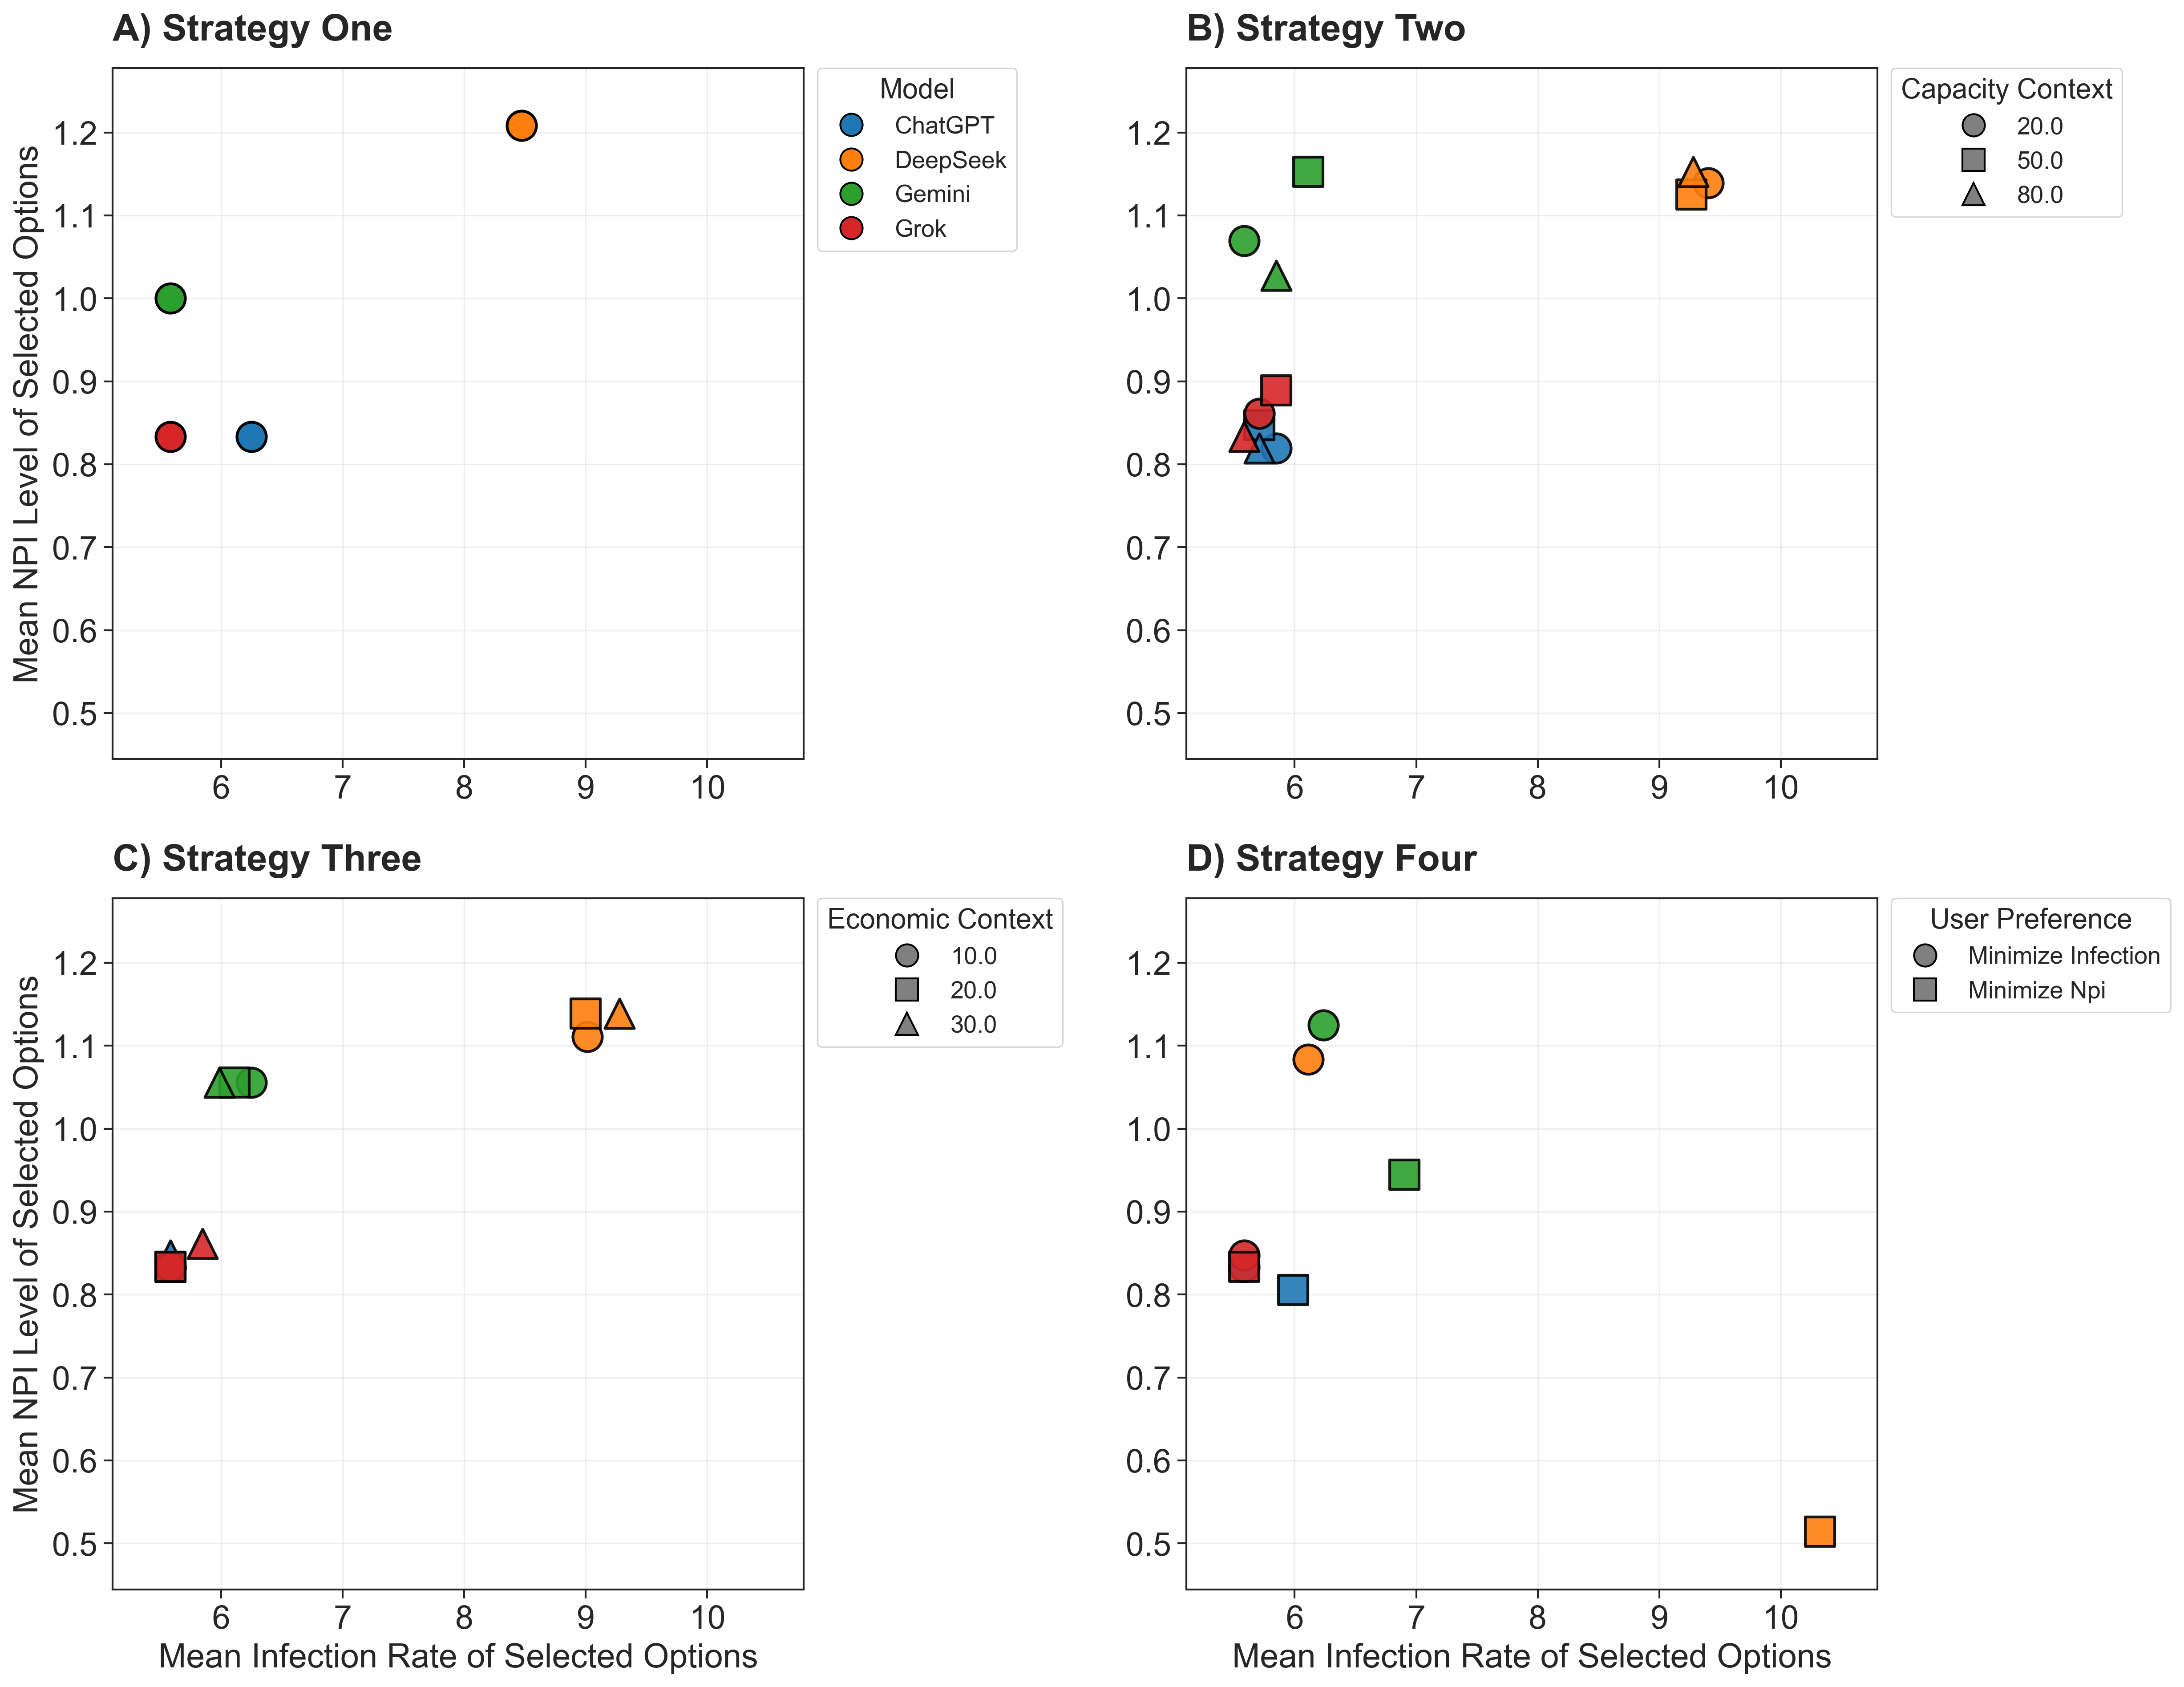

In [15]:
if not results_df.empty:
    strategies_sorted = sorted(results_df['strategy'].unique(), key=extract_strategy_number)
    n_strategies = len(strategies_sorted)
    n_cols = 2
    n_rows = int(np.ceil(n_strategies / n_cols))

    # Calculate global limits
    all_mins_x, all_maxs_x = [], []
    all_mins_y, all_maxs_y = [], []

    for strategy in strategies_sorted:
        s_data = results_df[results_df['strategy'] == strategy]
        ctx = get_context_column(strategy)
        group_cols = ['model', ctx] if (ctx and ctx in s_data.columns) else ['model']
        means = s_data.groupby(group_cols)[['infection_rate_selected', 'npi_level_selected']].mean()
        all_mins_x.append(means['infection_rate_selected'].min())
        all_maxs_x.append(means['infection_rate_selected'].max())
        all_mins_y.append(means['npi_level_selected'].min())
        all_maxs_y.append(means['npi_level_selected'].max())

    x_min, x_max = min(all_mins_x), max(all_maxs_x)
    y_min, y_max = min(all_mins_y), max(all_maxs_y)
    pad_x = (x_max - x_min) * 0.1
    pad_y = (y_max - y_min) * 0.1

    # Same figure construction as the reference script (fonts/spacing identical)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=FIG_SIZE_MULTI, sharex=True, sharey=True)
    axes_flat = axes.flatten()
    markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p', '*', 'h']

    # Model legend (same sizing as reference)
    sorted_models = sorted(results_df['model'].unique())
    model_handles = [
        plt.Line2D(
            [0], [0], marker='o', color='w',
            markerfacecolor=MODEL_COLORS[m],
            markersize=12, markeredgecolor='black',
            label=m
        )
        for m in sorted_models
    ]

    for idx, strategy in enumerate(strategies_sorted):
        ax = axes_flat[idx]
        strategy_data = results_df[results_df['strategy'] == strategy].copy()
        context_col = get_context_column(strategy)

        # Same subplot title styling as reference
        ax.set_title(
            f'{string.ascii_uppercase[idx]}) {strategy.replace("_", " ").title()}',
            fontsize=20, fontweight='bold', loc='left', pad=15
        )
        ax.set_xlim(x_min - pad_x, x_max + pad_x)
        ax.set_ylim(y_min - pad_y, y_max + pad_y)
        ax.grid(True, alpha=0.3)

        # Add square-ish panels WITHOUT changing any text styling
        ax.set_box_aspect(1)  # box aspect controls axes shape in figure space [web:110]

        if context_col and context_col in strategy_data.columns:
            means = (
                strategy_data
                .groupby(['model', context_col])[['infection_rate_selected', 'npi_level_selected']]
                .mean()
                .reset_index()
            )
            contexts = sorted(means[context_col].unique())
            ctx_markers = dict(zip(contexts, markers[:len(contexts)]))

            for _, row in means.iterrows():
                ax.scatter(
                    row['infection_rate_selected'], row['npi_level_selected'],
                    s=250,
                    c=[MODEL_COLORS[row['model']]],
                    marker=ctx_markers[row[context_col]],
                    edgecolor='black', linewidth=1.5,
                    alpha=0.9
                )

            # Context legend for this panel (IDENTICAL sizing to reference)
            ctx_handles = [
                plt.Line2D(
                    [0], [0], marker=ctx_markers[c], color='w',
                    markerfacecolor='gray', markersize=12,
                    markeredgecolor='black',
                    label=str(c).replace('_', ' ').title()
                )
                for c in contexts
            ]
            legend_title = get_legend_title(context_col)
            ax.legend(
                handles=ctx_handles, title=legend_title, loc='upper left',
                bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0,
                fontsize=13, title_fontsize=15, frameon=True
            )
        else:
            means = (
                strategy_data
                .groupby('model')[['infection_rate_selected', 'npi_level_selected']]
                .mean()
                .reset_index()
            )
            for _, row in means.iterrows():
                ax.scatter(
                    row['infection_rate_selected'], row['npi_level_selected'],
                    s=250,
                    c=[MODEL_COLORS[row['model']]],
                    marker='o',
                    edgecolor='black', linewidth=1.5
                )

        # Same tick styling as reference (no labelsize changes)
        ax.tick_params(bottom=True, left=True, labelbottom=True, labelleft=True)

        # Add model legend only to first panel (IDENTICAL sizing to reference)
        if idx == 0:
            ax.legend(
                handles=model_handles, title='Model', loc='upper left',
                bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0,
                fontsize=13, title_fontsize=15, frameon=True
            )

    # Hide unused panels
    for idx in range(n_strategies, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    # Axis labels (keep identical sizing to reference script)
    if np.ndim(axes) == 1:
        #axes[0].set_ylabel('Mean NPI Level of Selected Options', fontsize=18, fontweight='bold')
        #axes[-1].set_xlabel('Mean Infection Rate of Selected Options', fontsize=18, fontweight='bold')
        axes[0].set_ylabel('Mean NPI Level of Selected Options', fontsize=18)
        axes[-1].set_xlabel('Mean Infection Rate of Selected Options', fontsize=18)
    else:
        for ax in axes[:, 0]:
            #ax.set_ylabel('Mean NPI Level of Selected Options', fontsize=18, fontweight='bold')
            ax.set_ylabel('Mean NPI Level of Selected Options', fontsize=18)

        for ax in axes[-1, :]:
            if ax.get_visible():
                #ax.set_xlabel('Mean Infection Rate of Selected Options', fontsize=18, fontweight='bold')
                ax.set_xlabel('Mean Infection Rate of Selected Options', fontsize=18)

    # Remove main title
    fig.suptitle('')  # suptitle can be cleared by setting empty text [web:32]

    plt.tight_layout(rect=[0, 0, 0.94, 0.95])
    plt.show()


# PART II: Reasoning Pattern Analysis

## Reasoning Components Frequency by Model

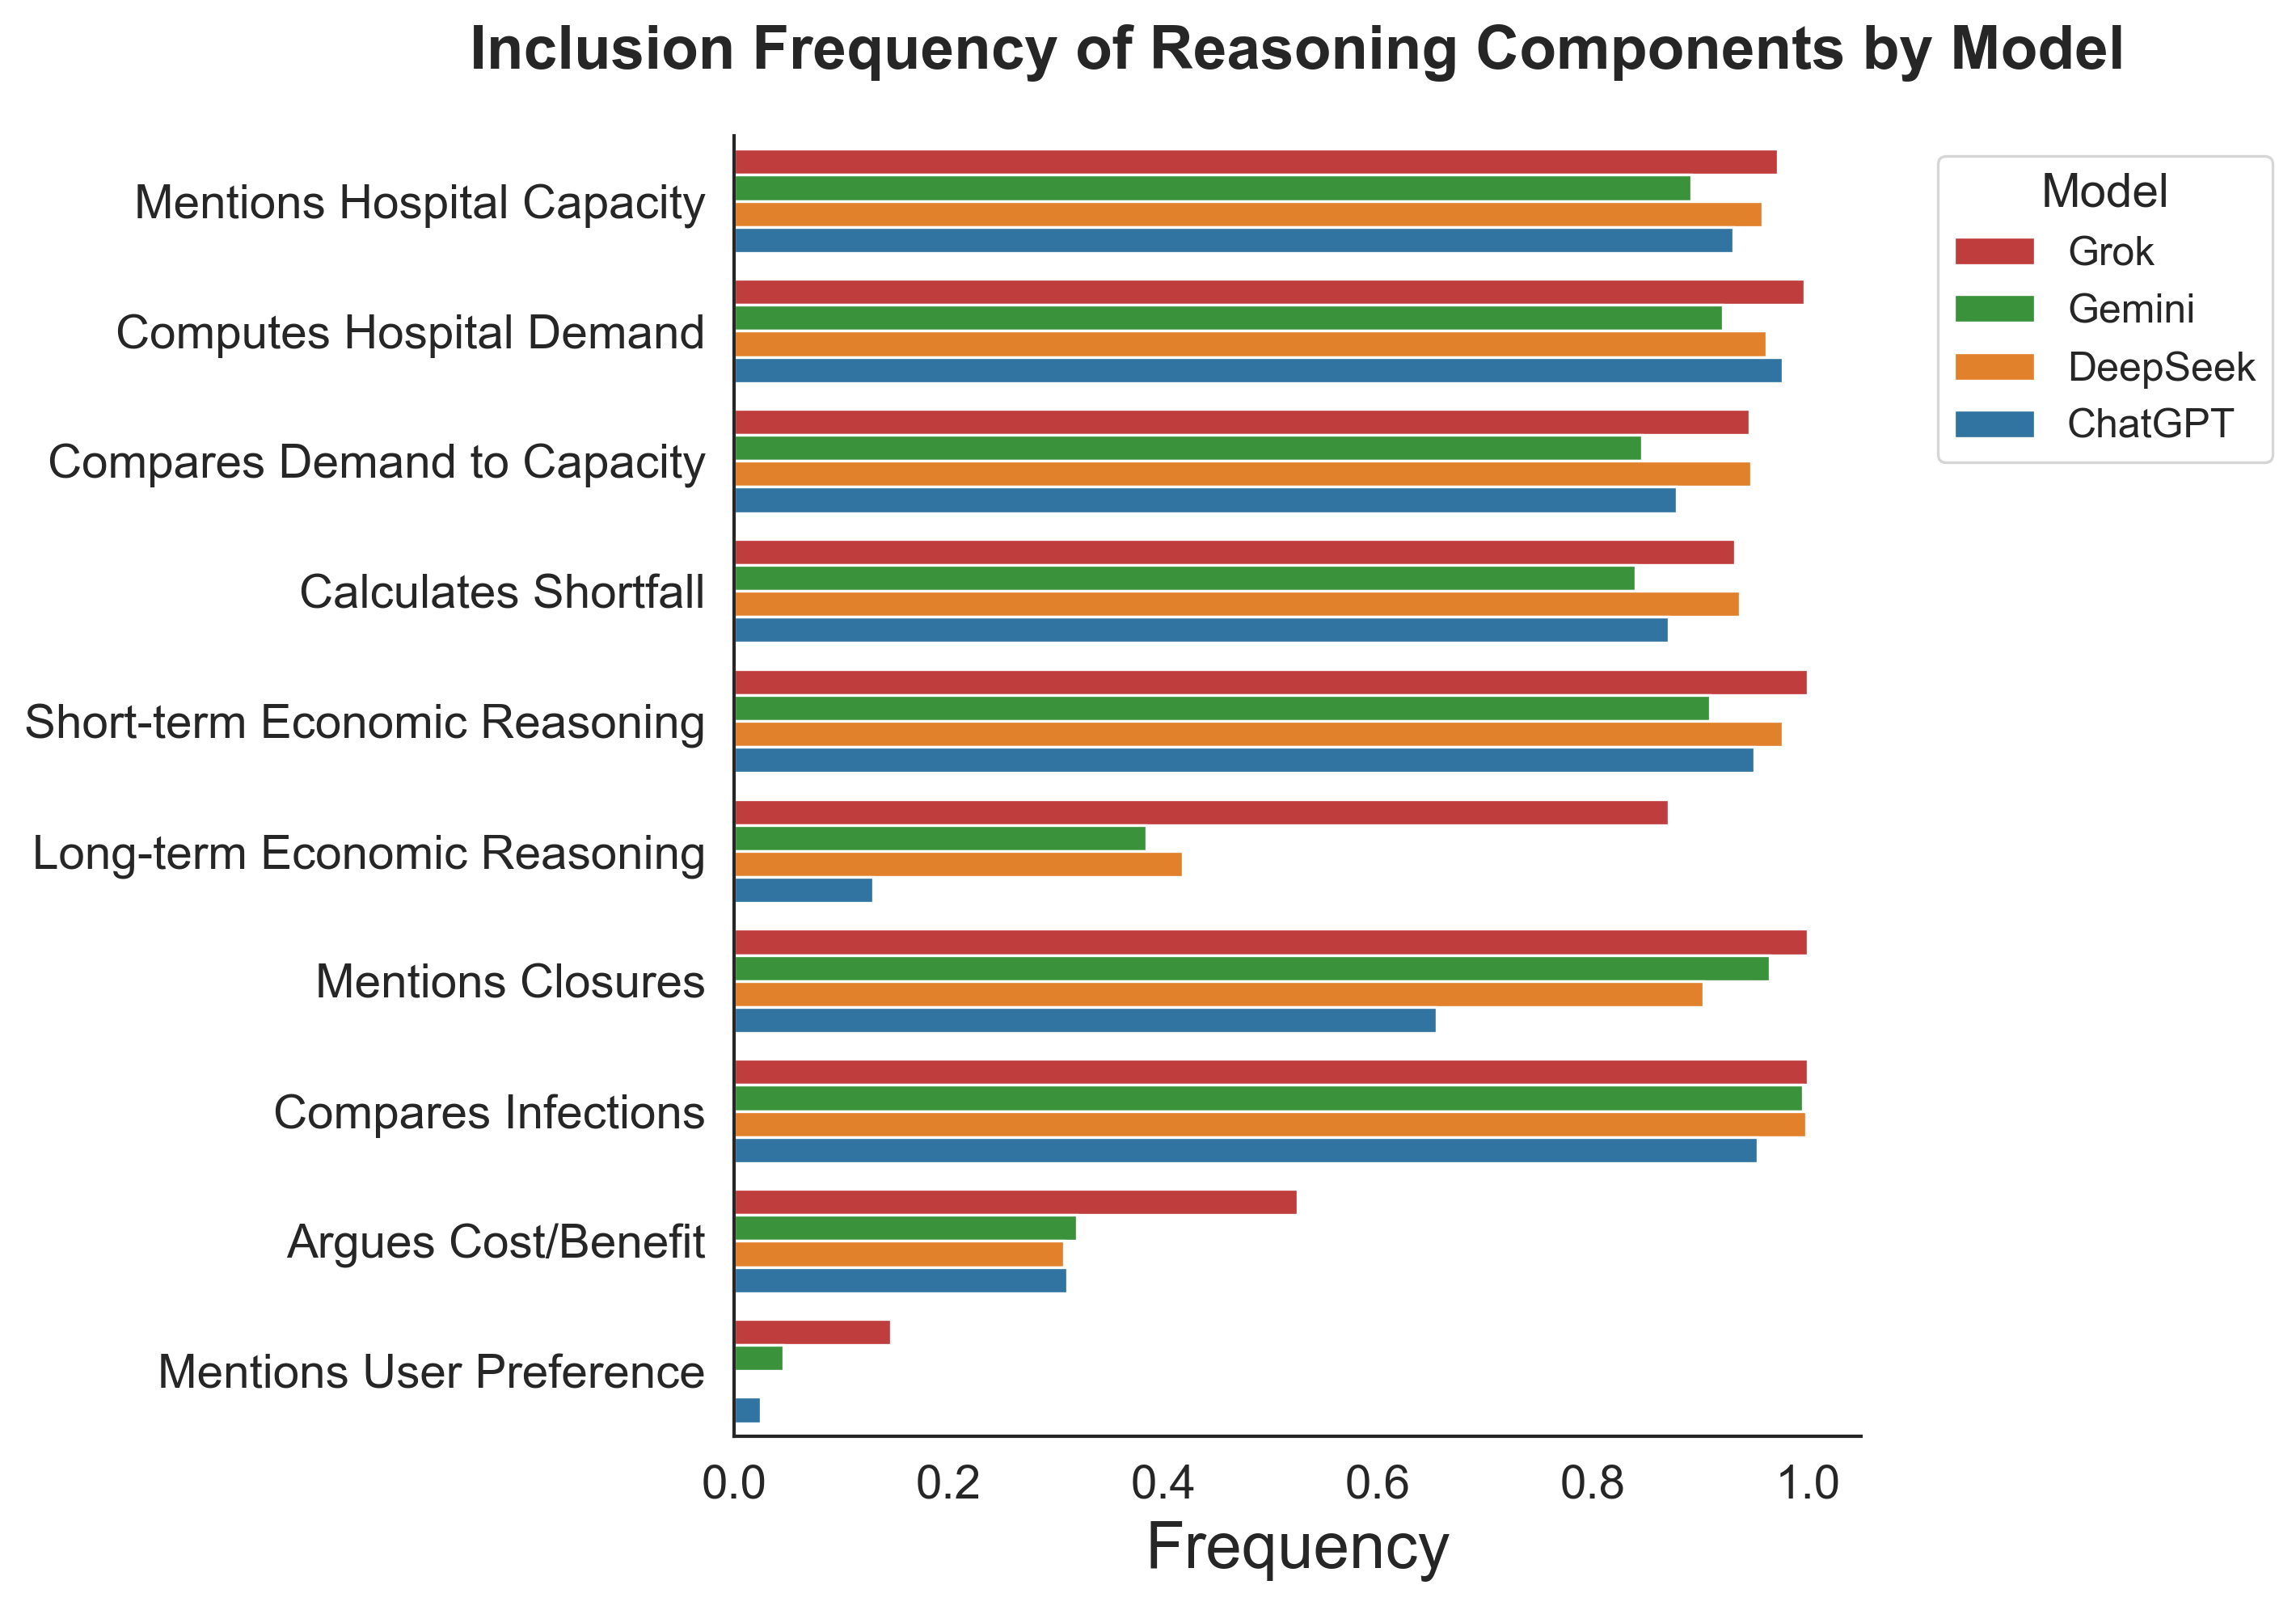

In [16]:
if not reasoning_df.empty:
    df_reasoning = reasoning_df.melt(
        id_vars=['model', 'strategy', 'choice_status'], 
        value_vars=reasoning_columns, 
        var_name='component', 
        value_name='present'
    )
    df_reasoning['component_label'] = df_reasoning['component'].apply(get_column_label)
    
    plt.figure(figsize=FIG_SIZE_SINGLE)
    ax = sns.barplot(
        data=df_reasoning,
        x='present', 
        y='component_label', 
        hue='model', 
        palette=MODEL_COLORS,
        errorbar=None
    )
    
    plt.xlabel('Frequency')
    plt.ylabel('')
    plt.title('Inclusion Frequency of Reasoning Components by Model', 
             fontsize=18, pad=20, fontweight='bold')
    plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left', 
              fontsize=12, title_fontsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.tick_params(axis='x', labelsize=14)
    sns.despine()
    plt.tight_layout()
    plt.show()

## Reasoning Patterns in Rational vs Irrational Choices

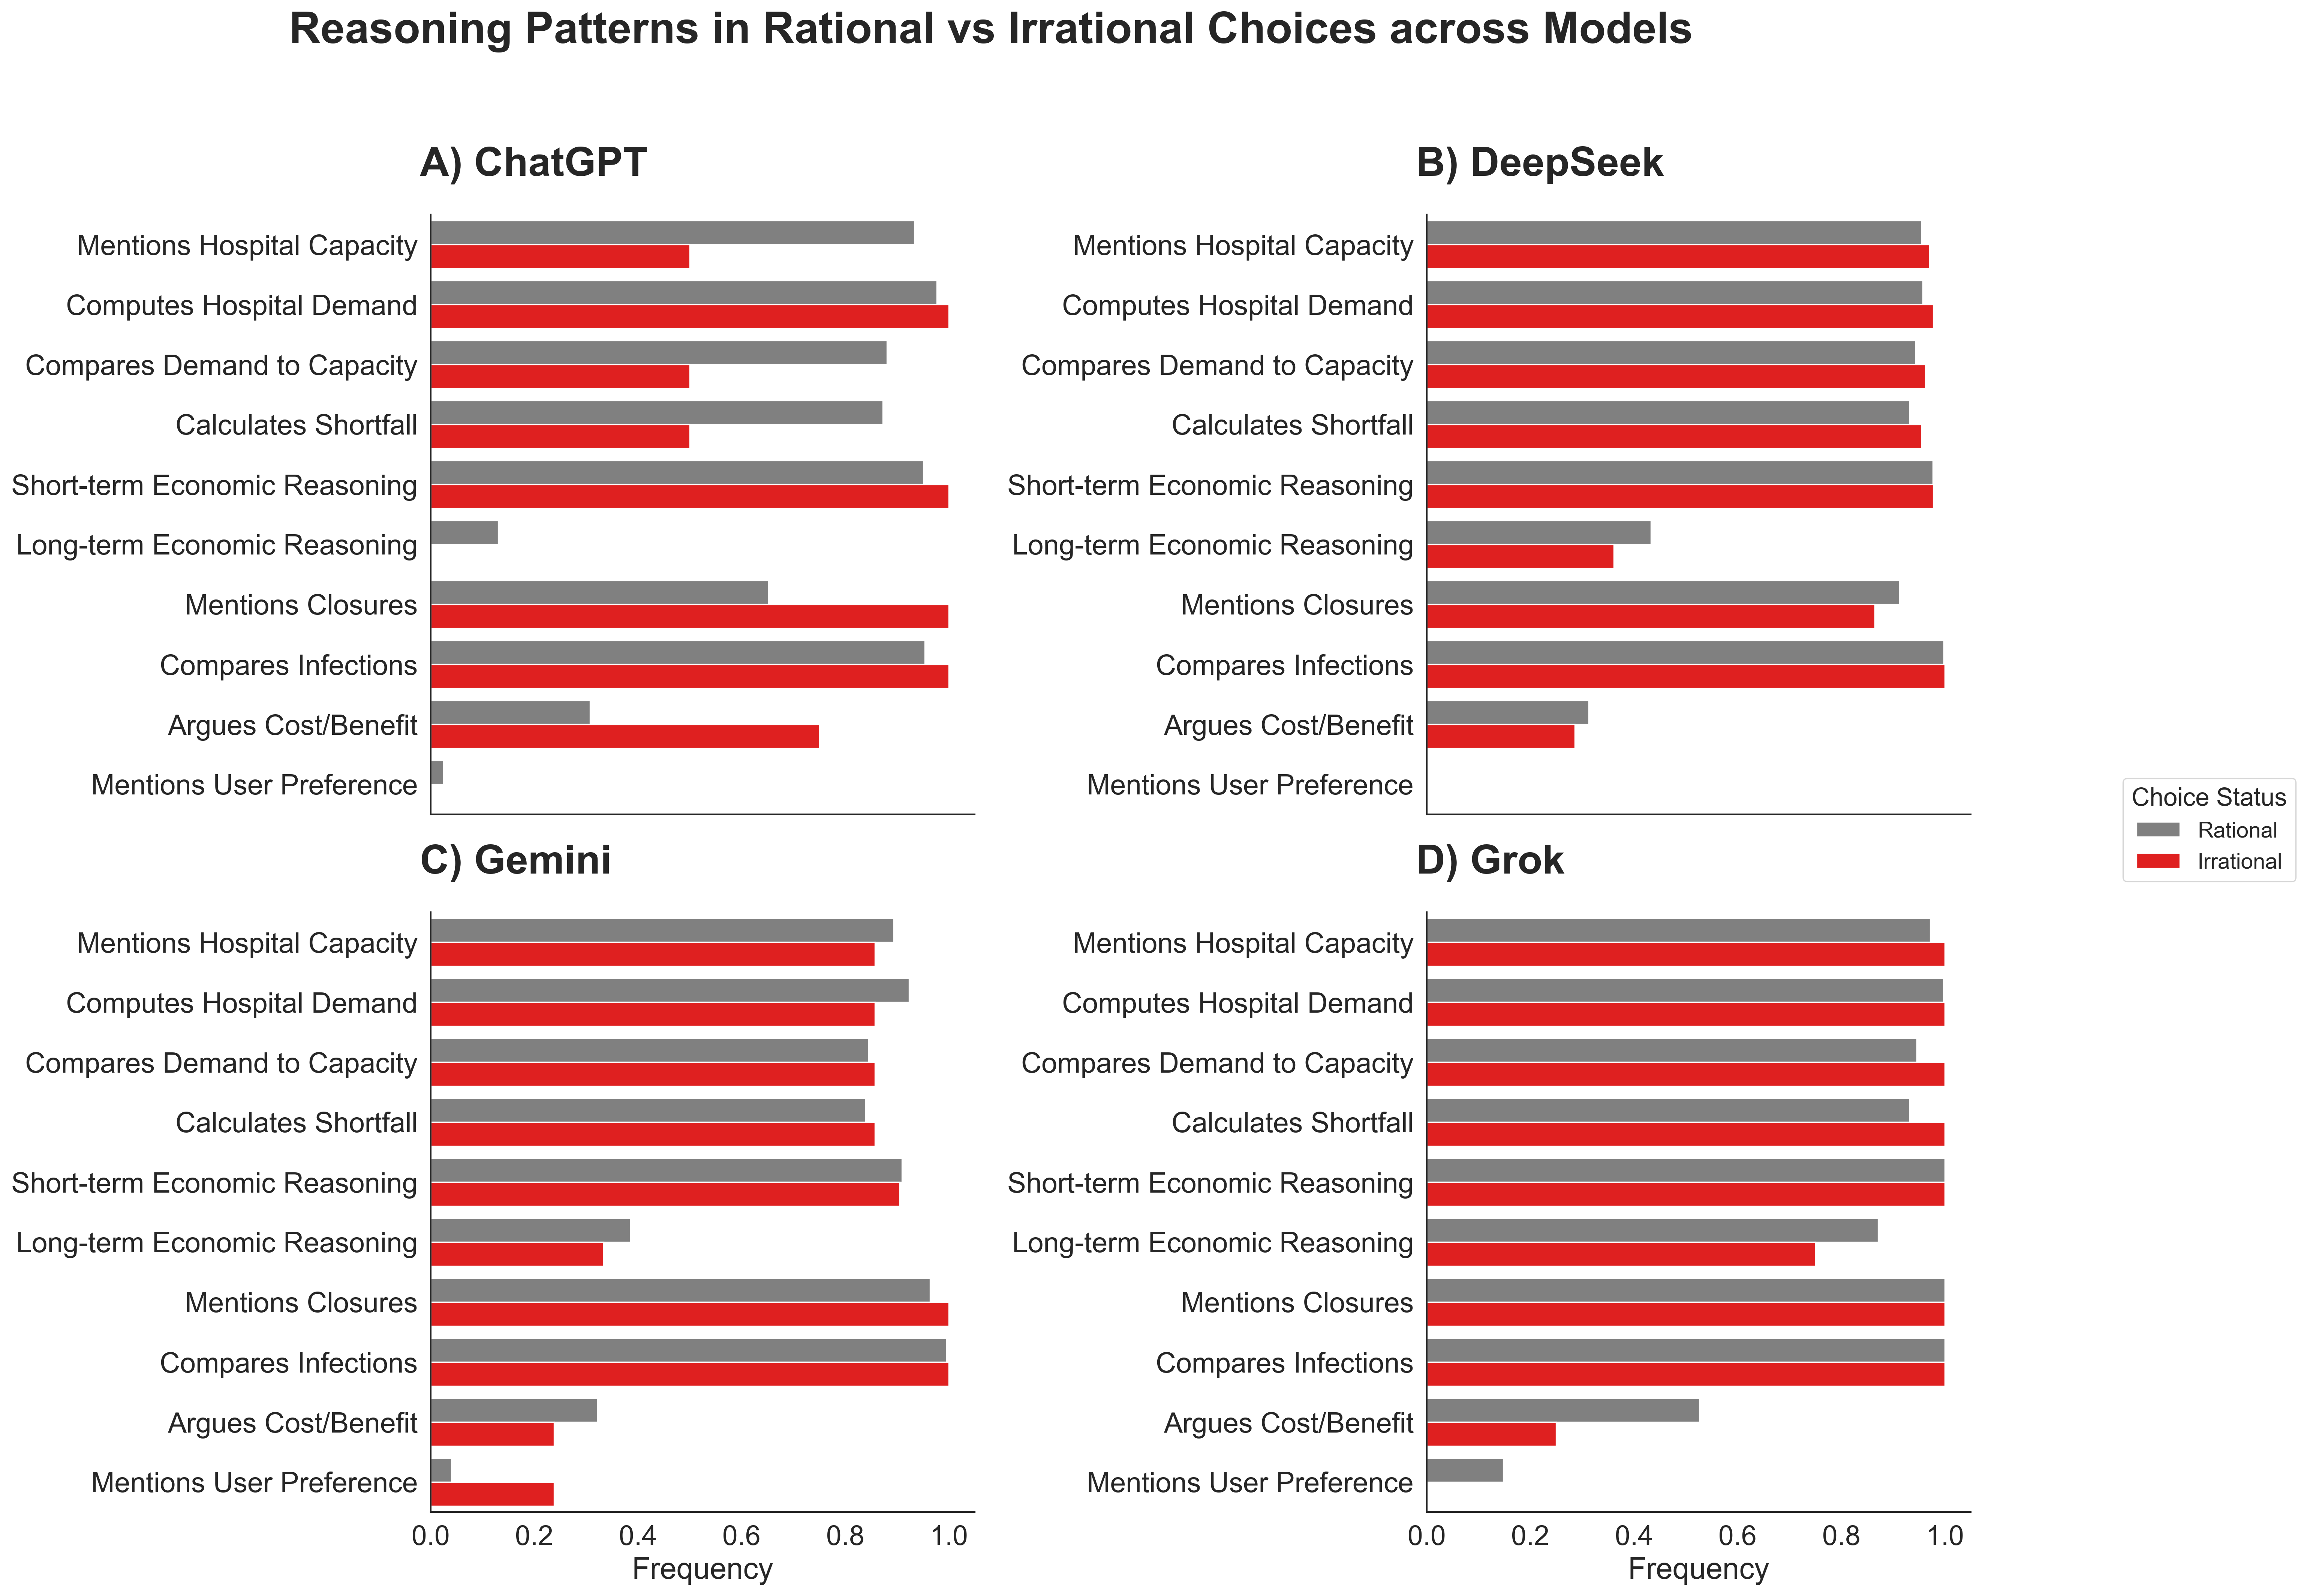

In [17]:
if not reasoning_df.empty:
    fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE_MULTI, sharex=True)
    axes = axes.flatten()
    
    model_order = sorted(reasoning_df['model'].unique())
    
    for i, model_name in enumerate(model_order):
        ax = axes[i]
        model_data = df_reasoning[df_reasoning['model'] == model_name]
        
        sns.barplot(
            data=model_data,
            x='present', 
            y='component_label', 
            hue='choice_status', 
            ax=ax,
            palette={'Rational': 'gray', 'Irrational': 'red'},
            errorbar=None,
            hue_order=['Rational', 'Irrational']  # Add this parameter
        )
        
        ax.set_xlabel('Frequency' if i >= 2 else '')
        ax.set_ylabel('')
        ax.tick_params(axis='y', labelsize=18)
        if ax.get_legend():
            ax.get_legend().remove()
    
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title='Choice Status', loc='center right', 
              bbox_to_anchor=(1.15, 0.5), fontsize=14, title_fontsize=16)
    
    fig.suptitle('Reasoning Patterns in Rational vs Irrational Choices across Models', 
                fontsize=28, y=1.02, fontweight='bold')
    add_panel_labels(axes, labels=model_order)
    sns.despine()
    plt.tight_layout()
    plt.show()


## Key Reasoning Components across Prompting Strategies

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/23064873.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([s.replace('_', ' ').title() for s in
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/23064873.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([s.replace('_', ' ').title() for s in
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/23064873.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([s.replace('_', ' ').title() for s in
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/23064873.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a F

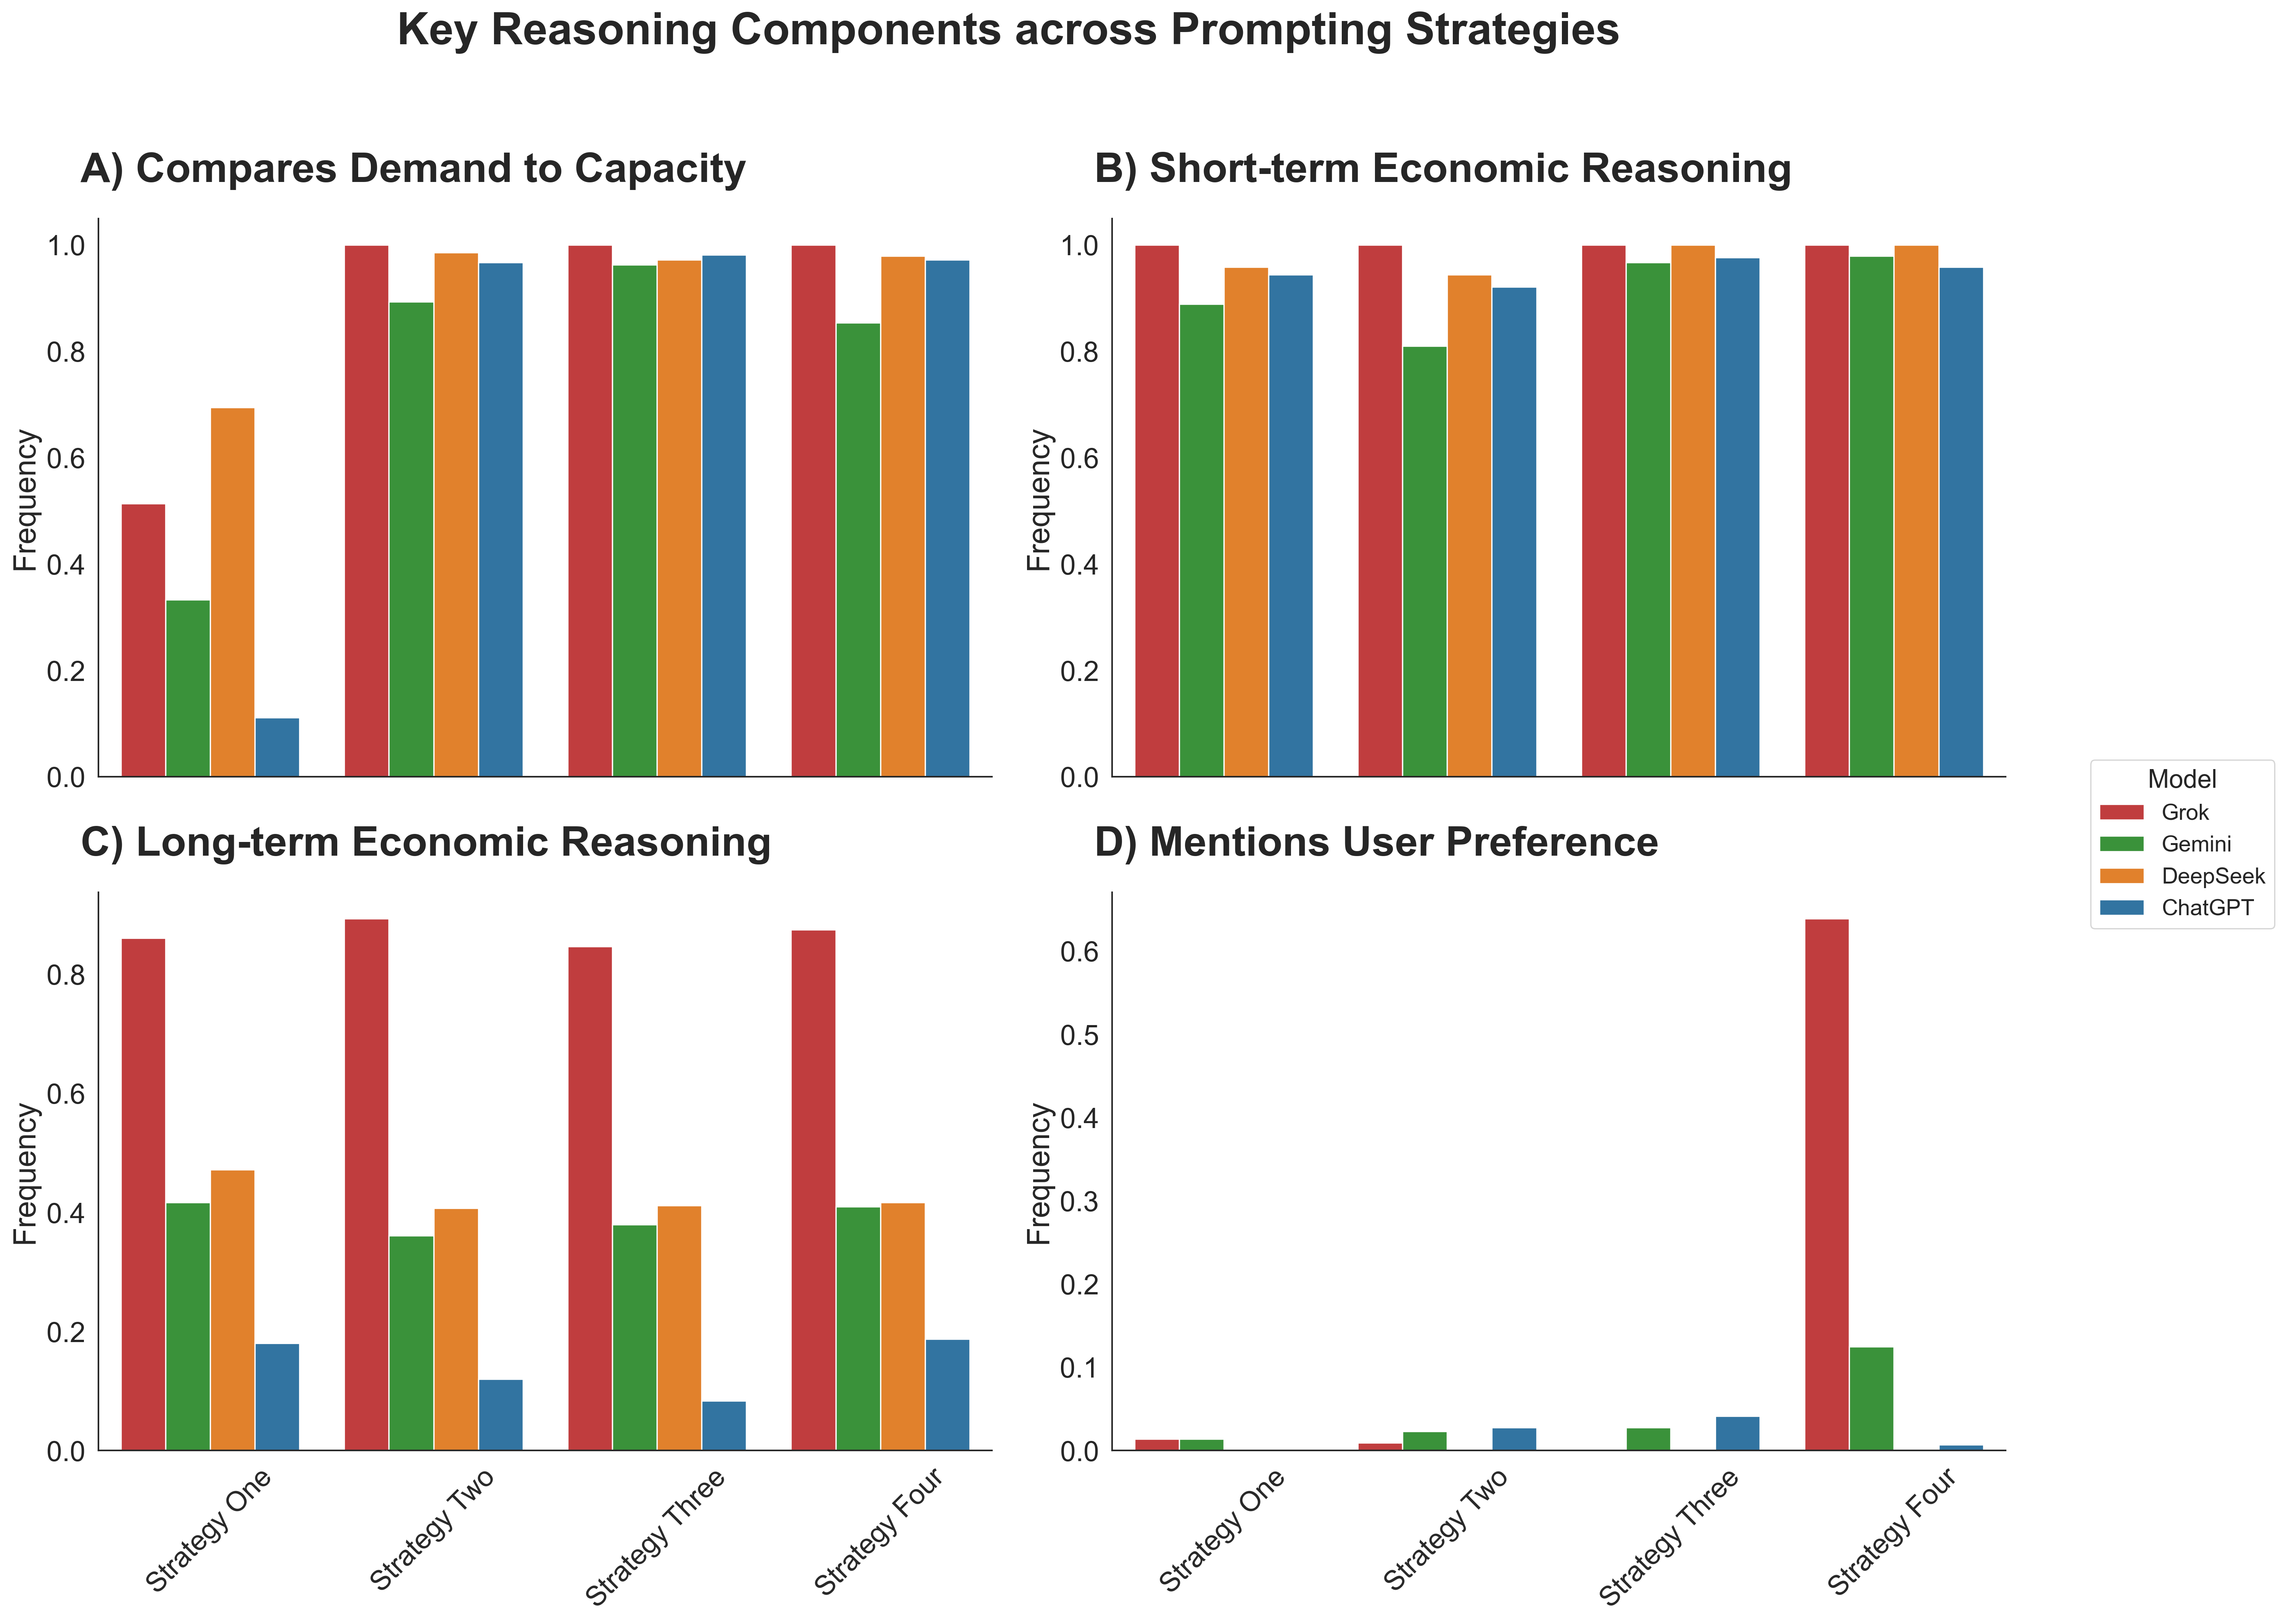

In [18]:
if not reasoning_df.empty:
    subset_cols = [
        #'compares_infection_rates_between_options',
        #'mentions_hospital_capacity', 

        'compares_demand_to_capacity', 
        
        'short_term_economic_reasoning',
        'long_term_economic_reasoning', 

        #'mentions_business_closures',

        #'argues_closures_not_worth_it_given_infections',
        'mentions_user_preference',
    ]
    
    fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE_MULTI, sharex=True)
    axes = axes.flatten()
    
    label_list = [get_column_label(col) for col in subset_cols]
    
    for i, col in enumerate(subset_cols):
        ax = axes[i]
        sns.barplot(
            data=reasoning_df,
            x='strategy', 
            y=col, 
            hue='model', 
            ax=ax, 
            palette=MODEL_COLORS,
            order=['strategy_one', 'strategy_two', 'strategy_three', 'strategy_four'],
            errorbar=None
        )
        
        ax.set_xticklabels([s.replace('_', ' ').title() for s in 
                           ['strategy_one', 'strategy_two', 'strategy_three', 'strategy_four']], 
                          rotation=45)
        ax.set_xlabel('')
        ax.set_ylabel('Frequency')
        if ax.get_legend():
            ax.get_legend().remove()
    
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title='Model', loc='center right', 
              bbox_to_anchor=(1.12, 0.5), fontsize=14, title_fontsize=16)
    
    fig.suptitle('Key Reasoning Components across Prompting Strategies', 
                fontsize=28, y=1.02, fontweight='bold')
    add_panel_labels(axes, labels=label_list)
    sns.despine()
    plt.tight_layout()
    plt.show()

## Average Reasoning Length by Model and Strategy

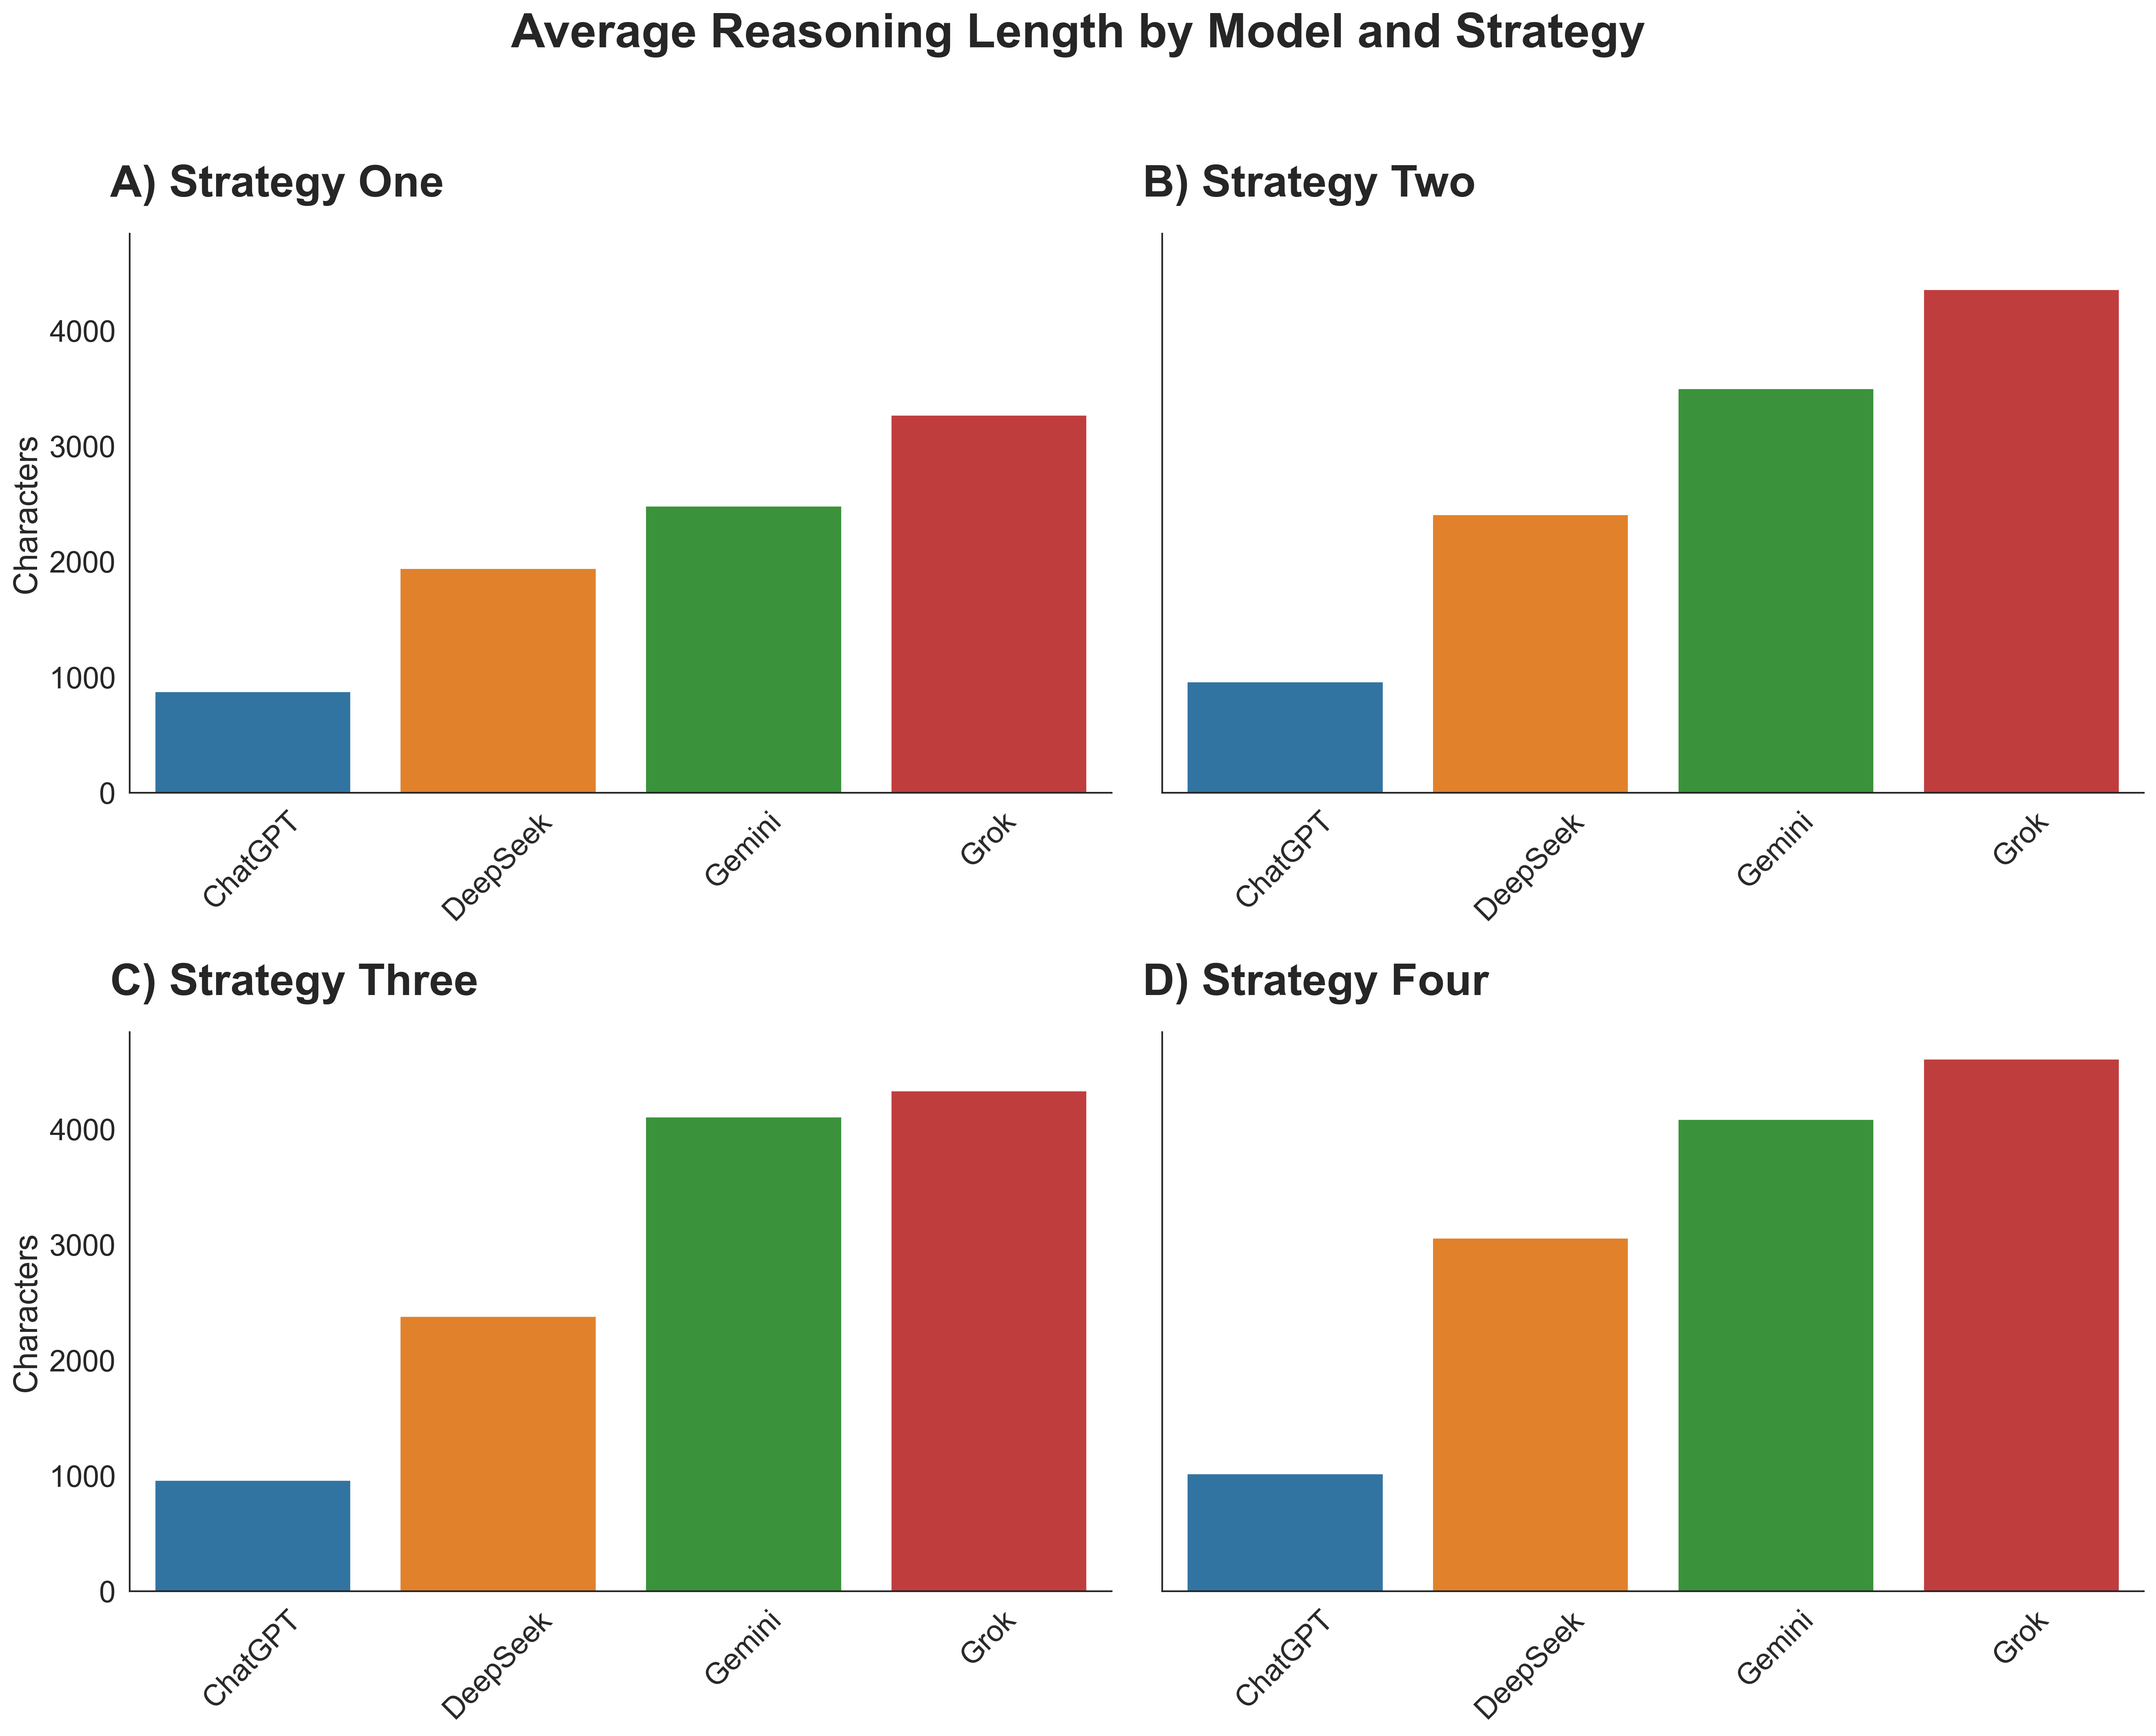

In [19]:
if not reasoning_df.empty:
    fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE_MULTI, sharey=True)
    axes = axes.flatten()
    
    strat_order = ['strategy_one', 'strategy_two', 'strategy_three', 'strategy_four']
    strat_labels = [s.replace('_', ' ').title() for s in strat_order]
    
    # Sort models alphabetically
    model_order = sorted(reasoning_df['model'].unique())
    
    for i, strat in enumerate(strat_order):
        ax = axes[i]
        strat_data = reasoning_df[reasoning_df['strategy'] == strat]
        
        sns.barplot(
            data=strat_data,
            x='model', 
            hue='model', 
            legend=False, 
            y='reasoning_length', 
            ax=ax, 
            palette=MODEL_COLORS,
            errorbar=None,
            order=model_order  # Add this parameter
        )
        
        ax.set_xlabel('')
        ax.set_ylabel('Characters')
        ax.tick_params(axis='x', rotation=45)
    
    fig.suptitle('Average Reasoning Length by Model and Strategy', 
                fontsize=28, y=1.02, fontweight='bold')
    add_panel_labels(axes, labels=strat_labels)
    sns.despine()
    plt.tight_layout()
    plt.show()


## Abstract Figure

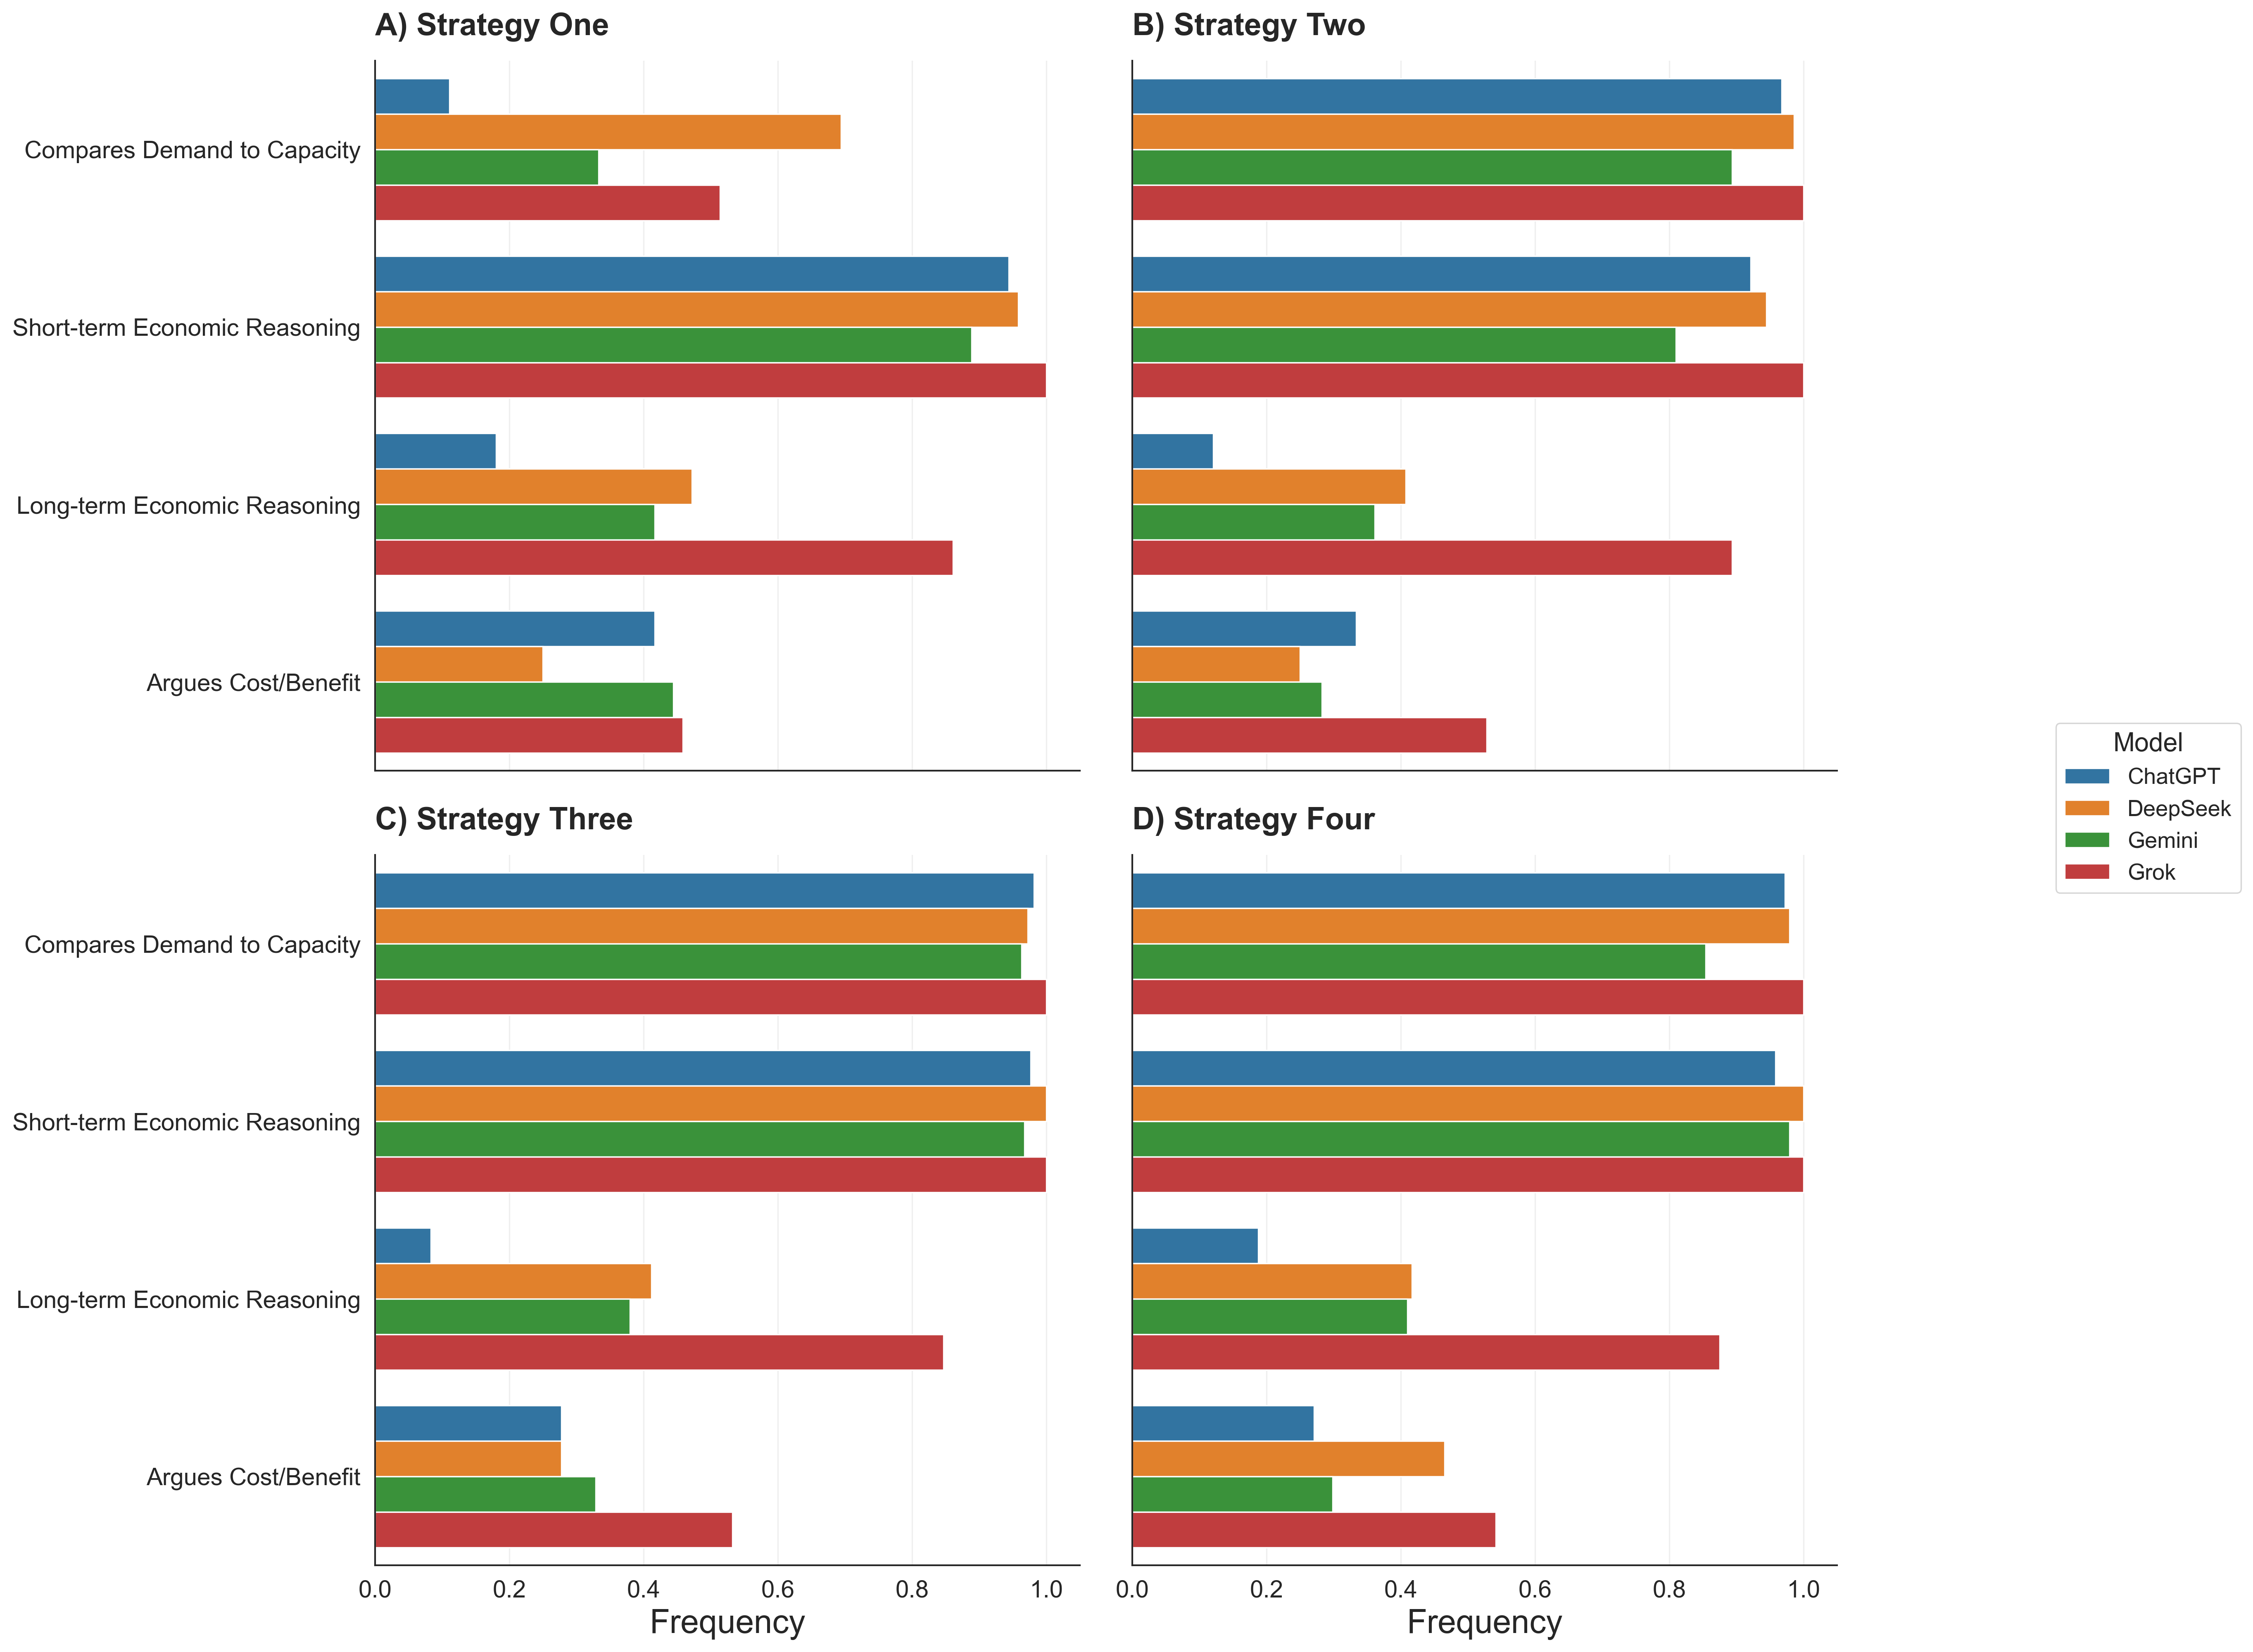

In [27]:
if not reasoning_df.empty:

    # 1) Choose which components to include (controls the y-axis)
    included_cols = [
        'compares_demand_to_capacity',
        'short_term_economic_reasoning',
        'long_term_economic_reasoning',
        'argues_closures_not_worth_it_given_infections',   # if you created it
        #'mentions_user_preference',
    ]

    # 2) Strategies -> 4 panels
    strategies_order = ['strategy_one', 'strategy_two', 'strategy_three', 'strategy_four']
    strategies_present = [s for s in strategies_order if s in reasoning_df['strategy'].unique()]

    # 3) Long-form data
    df_reasoning = reasoning_df.melt(
        id_vars=['model', 'strategy', 'choice_status'],
        value_vars=included_cols,
        var_name='component',
        value_name='present'
    )
    df_reasoning['component_label'] = df_reasoning['component'].apply(get_column_label)

    # Keep y-axis order consistent across panels (top-to-bottom)
    component_order = [get_column_label(c) for c in included_cols]

    # Optional: consistent model order
    models_sorted = sorted(df_reasoning['model'].unique())

    # 4) 2x2 grid (one panel per strategy)
    fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE_MULTI, sharex=True, sharey=True)
    axes = axes.flatten()

    for i, strategy in enumerate(strategies_present):
        ax = axes[i]
        sub = df_reasoning[df_reasoning['strategy'] == strategy].copy()

        sns.barplot(
            data=sub,
            x='present',
            y='component_label',
            hue='model',
            hue_order=models_sorted,
            palette=MODEL_COLORS,
            order=component_order,
            errorbar=None,
            ax=ax,
            orient='h'
        )

        ax.set_title(
            f'{string.ascii_uppercase[i]}) {strategy.replace("_", " ").title()}',
            fontsize=18, pad=15, fontweight='bold', loc='left'
        )
        ax.set_xlabel('Frequency')
        ax.set_ylabel('')
        ax.tick_params(axis='y', labelsize=14)
        ax.tick_params(axis='x', labelsize=14)
        ax.grid(axis='x', alpha=0.3)

        # Remove per-axis legends; add one figure legend after loop
        if ax.get_legend():
            ax.get_legend().remove()

    # Hide unused axes if fewer than 4 strategies present
    for j in range(len(strategies_present), len(axes)):
        axes[j].set_visible(False)

    # One shared legend (uses handles/labels from the last barplot call)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        title='Model',
        loc='center right',
        bbox_to_anchor=(1.02, 0.5),
        fontsize=13,
        title_fontsize=15,
        frameon=True
    )

    sns.despine()
    fig.suptitle('')  # no main title
    plt.tight_layout(rect=[0, 0, 0.85, 1.0])
    plt.show()


NameError: name 'mticker' is not defined

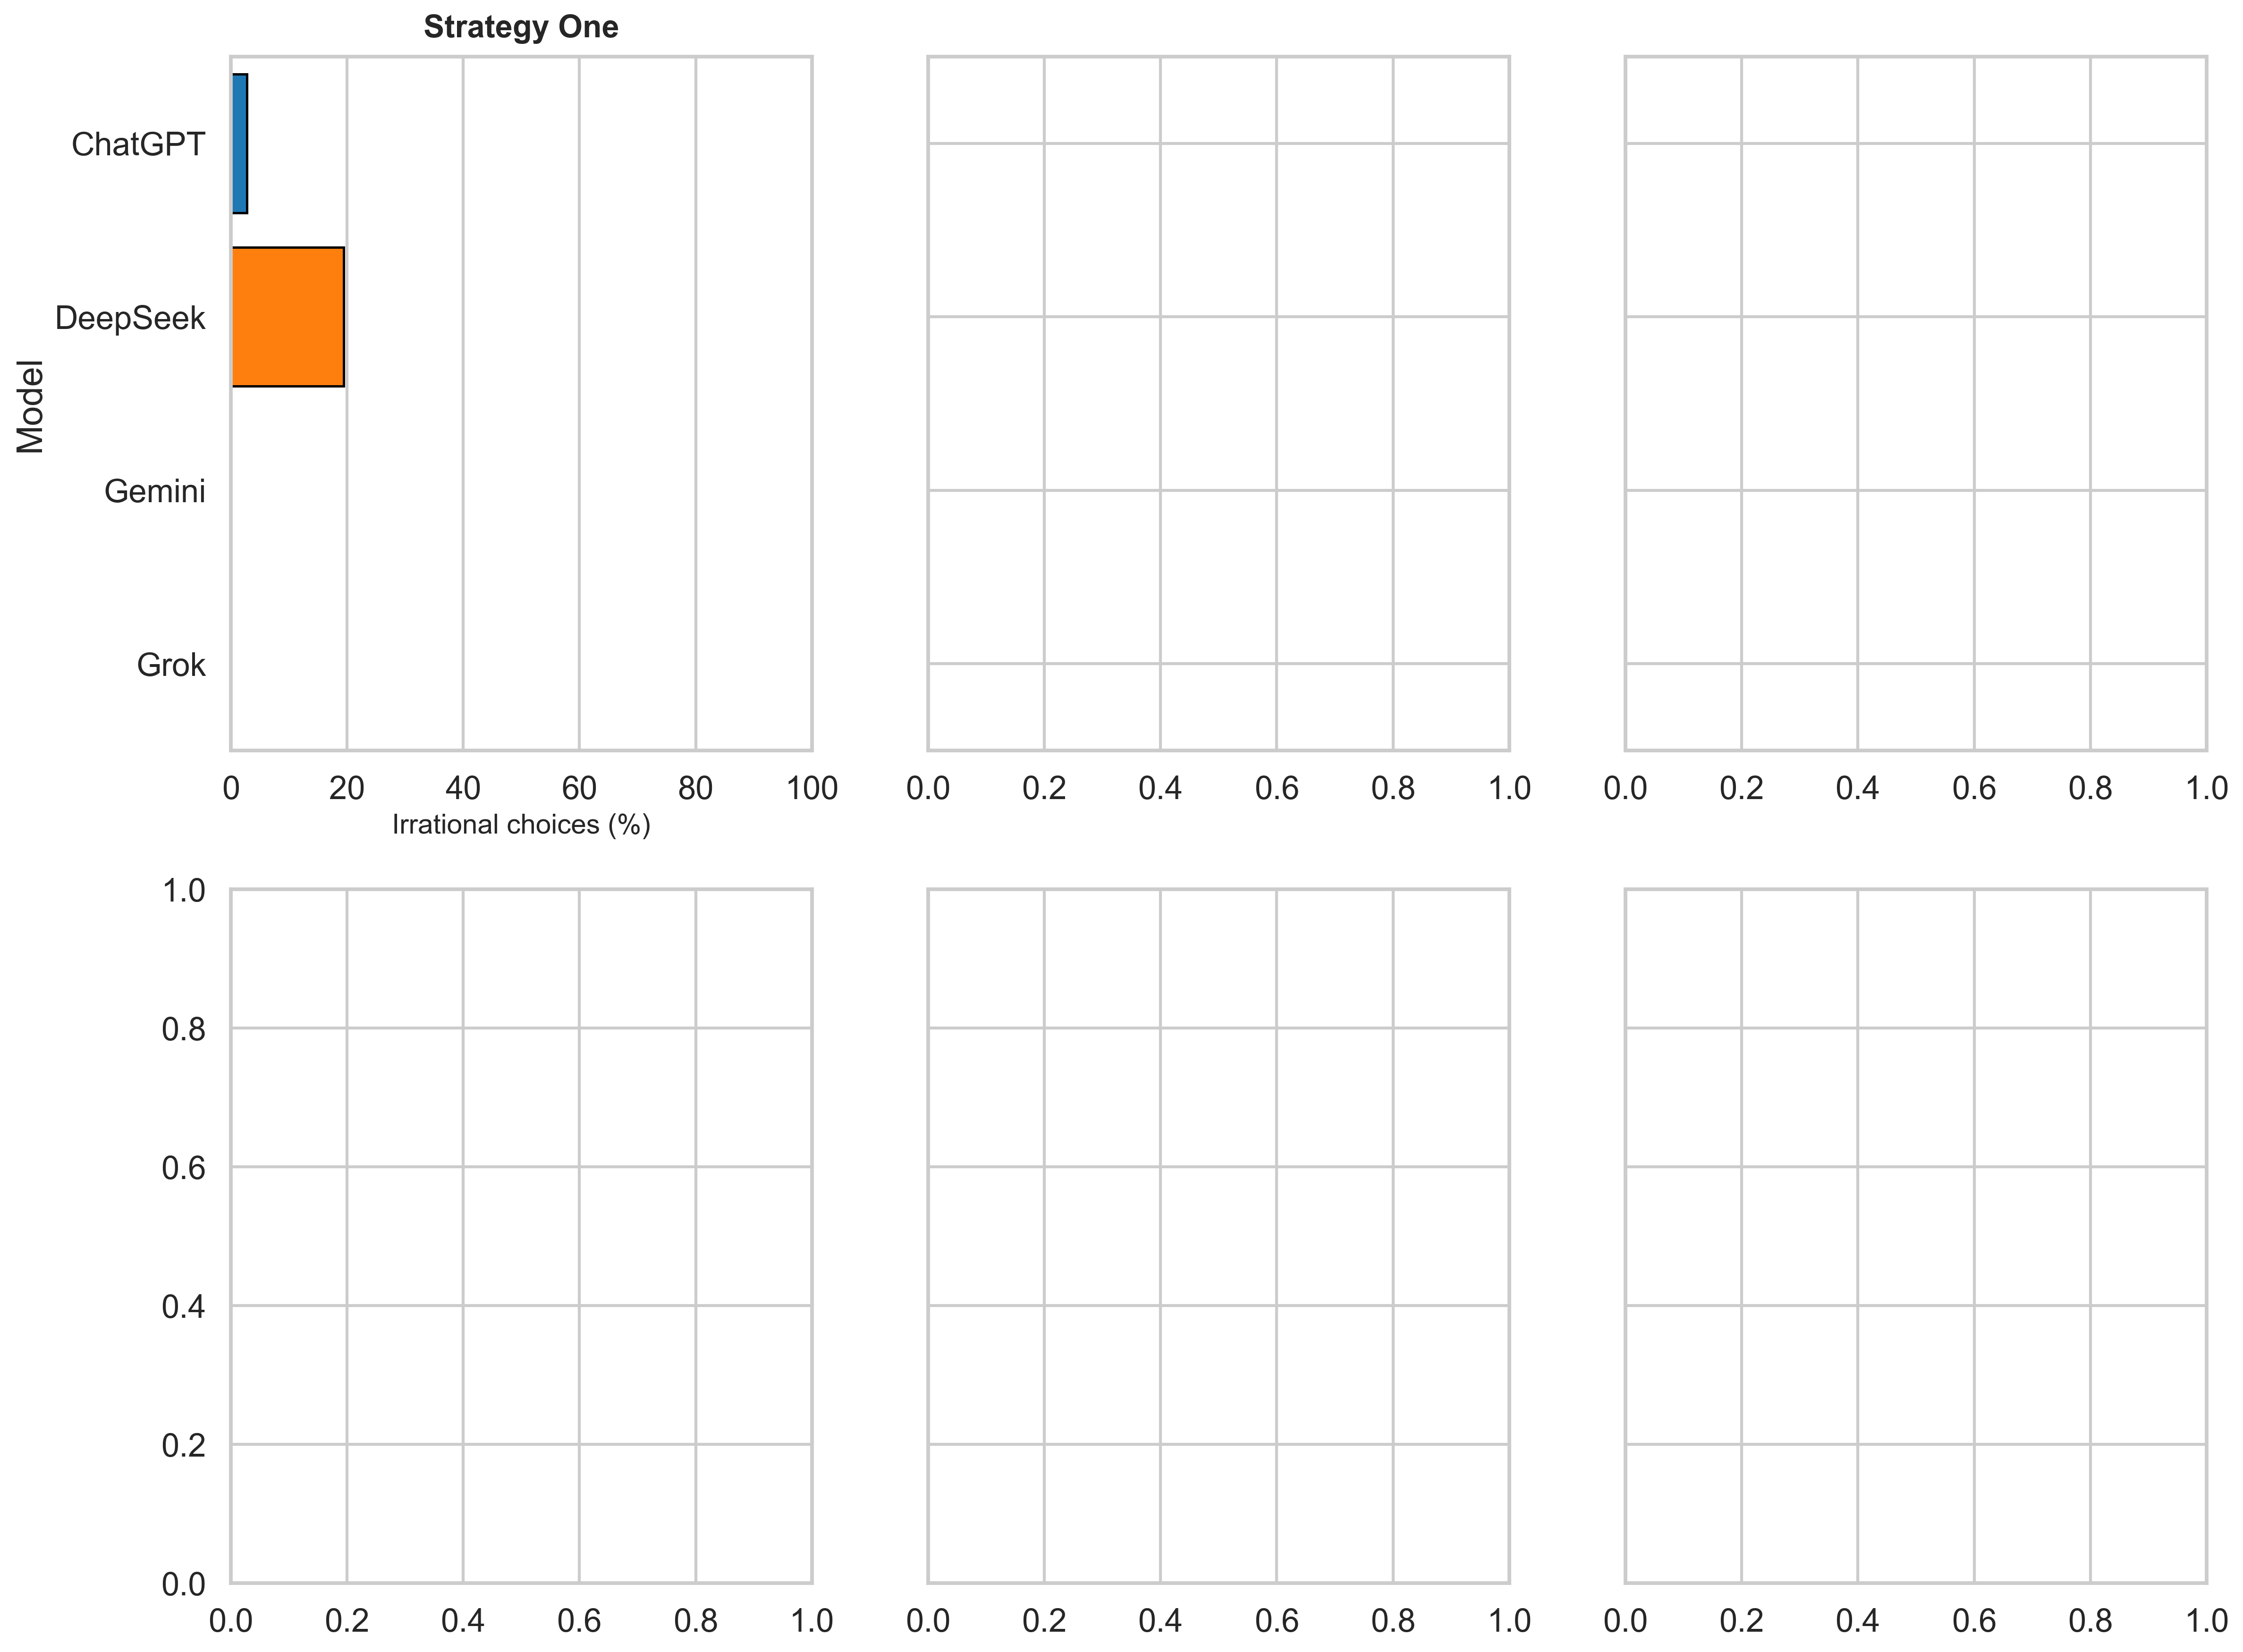

In [ ]:


if (not results_df.empty) and (not reasoning_df.empty):

    sns.set_theme(style="whitegrid", context="talk")

    strategies_order = ["strategy_one", "strategy_two", "strategy_three"]  # omit strategy_four
    strategies_present = [
        s for s in strategies_order
        if s in results_df["strategy"].unique() and s in reasoning_df["strategy"].unique()
    ]

    included_cols = [
        "compares_demand_to_capacity",
        "short_term_economic_reasoning",
        "long_term_economic_reasoning",
        "argues_closures_not_worth_it_given_infections",
    ]
    component_order = [get_column_label(c) for c in included_cols]

    plot_results = results_df.loc[results_df["strategy"].isin(strategies_present)].copy()
    plot_reasoning = reasoning_df.loc[reasoning_df["strategy"].isin(strategies_present)].copy()

    models_sorted = sorted(plot_results["model"].unique())

    # Build a stable palette dict regardless of whether MODEL_COLORS is a dict or list-like
    if isinstance(MODEL_COLORS, dict):
        palette = {m: MODEL_COLORS[m] for m in models_sorted}
    else:
        palette = dict(zip(models_sorted, MODEL_COLORS))

    # Long-form reasoning and pre-aggregate to rates (cleaner + faster plotting)
    df_reasoning = plot_reasoning.melt(
        id_vars=["model", "strategy", "choice_status"],
        value_vars=included_cols,
        var_name="component",
        value_name="present",
    )
    df_reasoning["component_label"] = df_reasoning["component"].map(get_column_label)
    df_reasoning["present"] = df_reasoning["present"].astype(float)

    reason_rates = (
        df_reasoning
        .groupby(["strategy", "model", "component_label"], as_index=False)["present"]
        .mean()
    )
    reason_rates["present_percent"] = 100 * reason_rates["present"]

    fig, axes = plt.subplots(2, 3, figsize=FIG_SIZE_MULTI, sharey="row")

    for j, strategy in enumerate(strategies_present):
        # --- Top: irrationality rate ---
        ax_top = axes[0, j]
        sub_res = plot_results.loc[plot_results["strategy"] == strategy]

        irr_df = (
            sub_res.groupby("model", as_index=False)["irrational_choice"]
            .mean()
            .rename(columns={"irrational_choice": "irr_rate"})
        )
        irr_df["irr_percent"] = 100 * irr_df["irr_rate"]

        sns.barplot(
            data=irr_df,
            x="irr_percent",
            y="model",
            order=models_sorted,
            color="C0",                 # overridden by palette via hue-less mapping below
            palette=None,
            orient="h",
            errorbar=None,
            ax=ax_top,
            edgecolor="black",
            linewidth=1.2,
        )

        # Color bars by model (avoids hue= model + duplicate legends)
        for bar, model in zip(ax_top.patches, irr_df.set_index("model").loc[models_sorted].index):
            bar.set_facecolor(palette[model])

        ax_top.set_title(strategy.replace("_", " ").title(), fontsize=16, pad=10, fontweight="bold")
        ax_top.set_xlabel("Irrational choices (%)", fontsize=14)
        ax_top.set_ylabel("Model" if j == 0 else "")
        ax_top.set_xlim(0, 100)
        ax_top.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
        ax_top.grid(axis="x", alpha=0.25)
        ax_top.tick_params(axis="both", labelsize=12, labelleft=(j == 0))

        # --- Bottom: reasoning components ---
        ax_bot = axes[1, j]
        sub_reason = reason_rates.loc[reason_rates["strategy"] == strategy]

        sns.barplot(
            data=sub_reason,
            x="present_percent",
            y="component_label",
            hue="model",
            order=component_order,
            hue_order=models_sorted,
            palette=palette,
            orient="h",
            errorbar=None,
            ax=ax_bot,
            edgecolor="black",
            linewidth=1.2,
            legend=False,               # ensure no per-axes legends
        )

        ax_bot.set_xlabel("Present in response (%)", fontsize=14)
        ax_bot.set_ylabel("Reasoning component" if j == 0 else "")
        ax_bot.set_xlim(0, 100)
        ax_bot.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
        ax_bot.grid(axis="x", alpha=0.25)
        ax_bot.tick_params(axis="both", labelsize=12, labelleft=(j == 0))

    # Hide unused columns
    for j in range(len(strategies_present), 3):
        axes[0, j].set_visible(False)
        axes[1, j].set_visible(False)

    # Shared figure legend via proxy artists (never empty)
    legend_handles = [
        mpatches.Patch(facecolor=palette[m], edgecolor="black", label=m)
        for m in models_sorted
    ]
    fig.legend(
        handles=legend_handles,
        title="Model",
        loc="center right",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=11,
        title_fontsize=12,
        frameon=True,
    )

    sns.despine()
    plt.tight_layout(rect=[0, 0, 0.88, 1.0])
    plt.show()


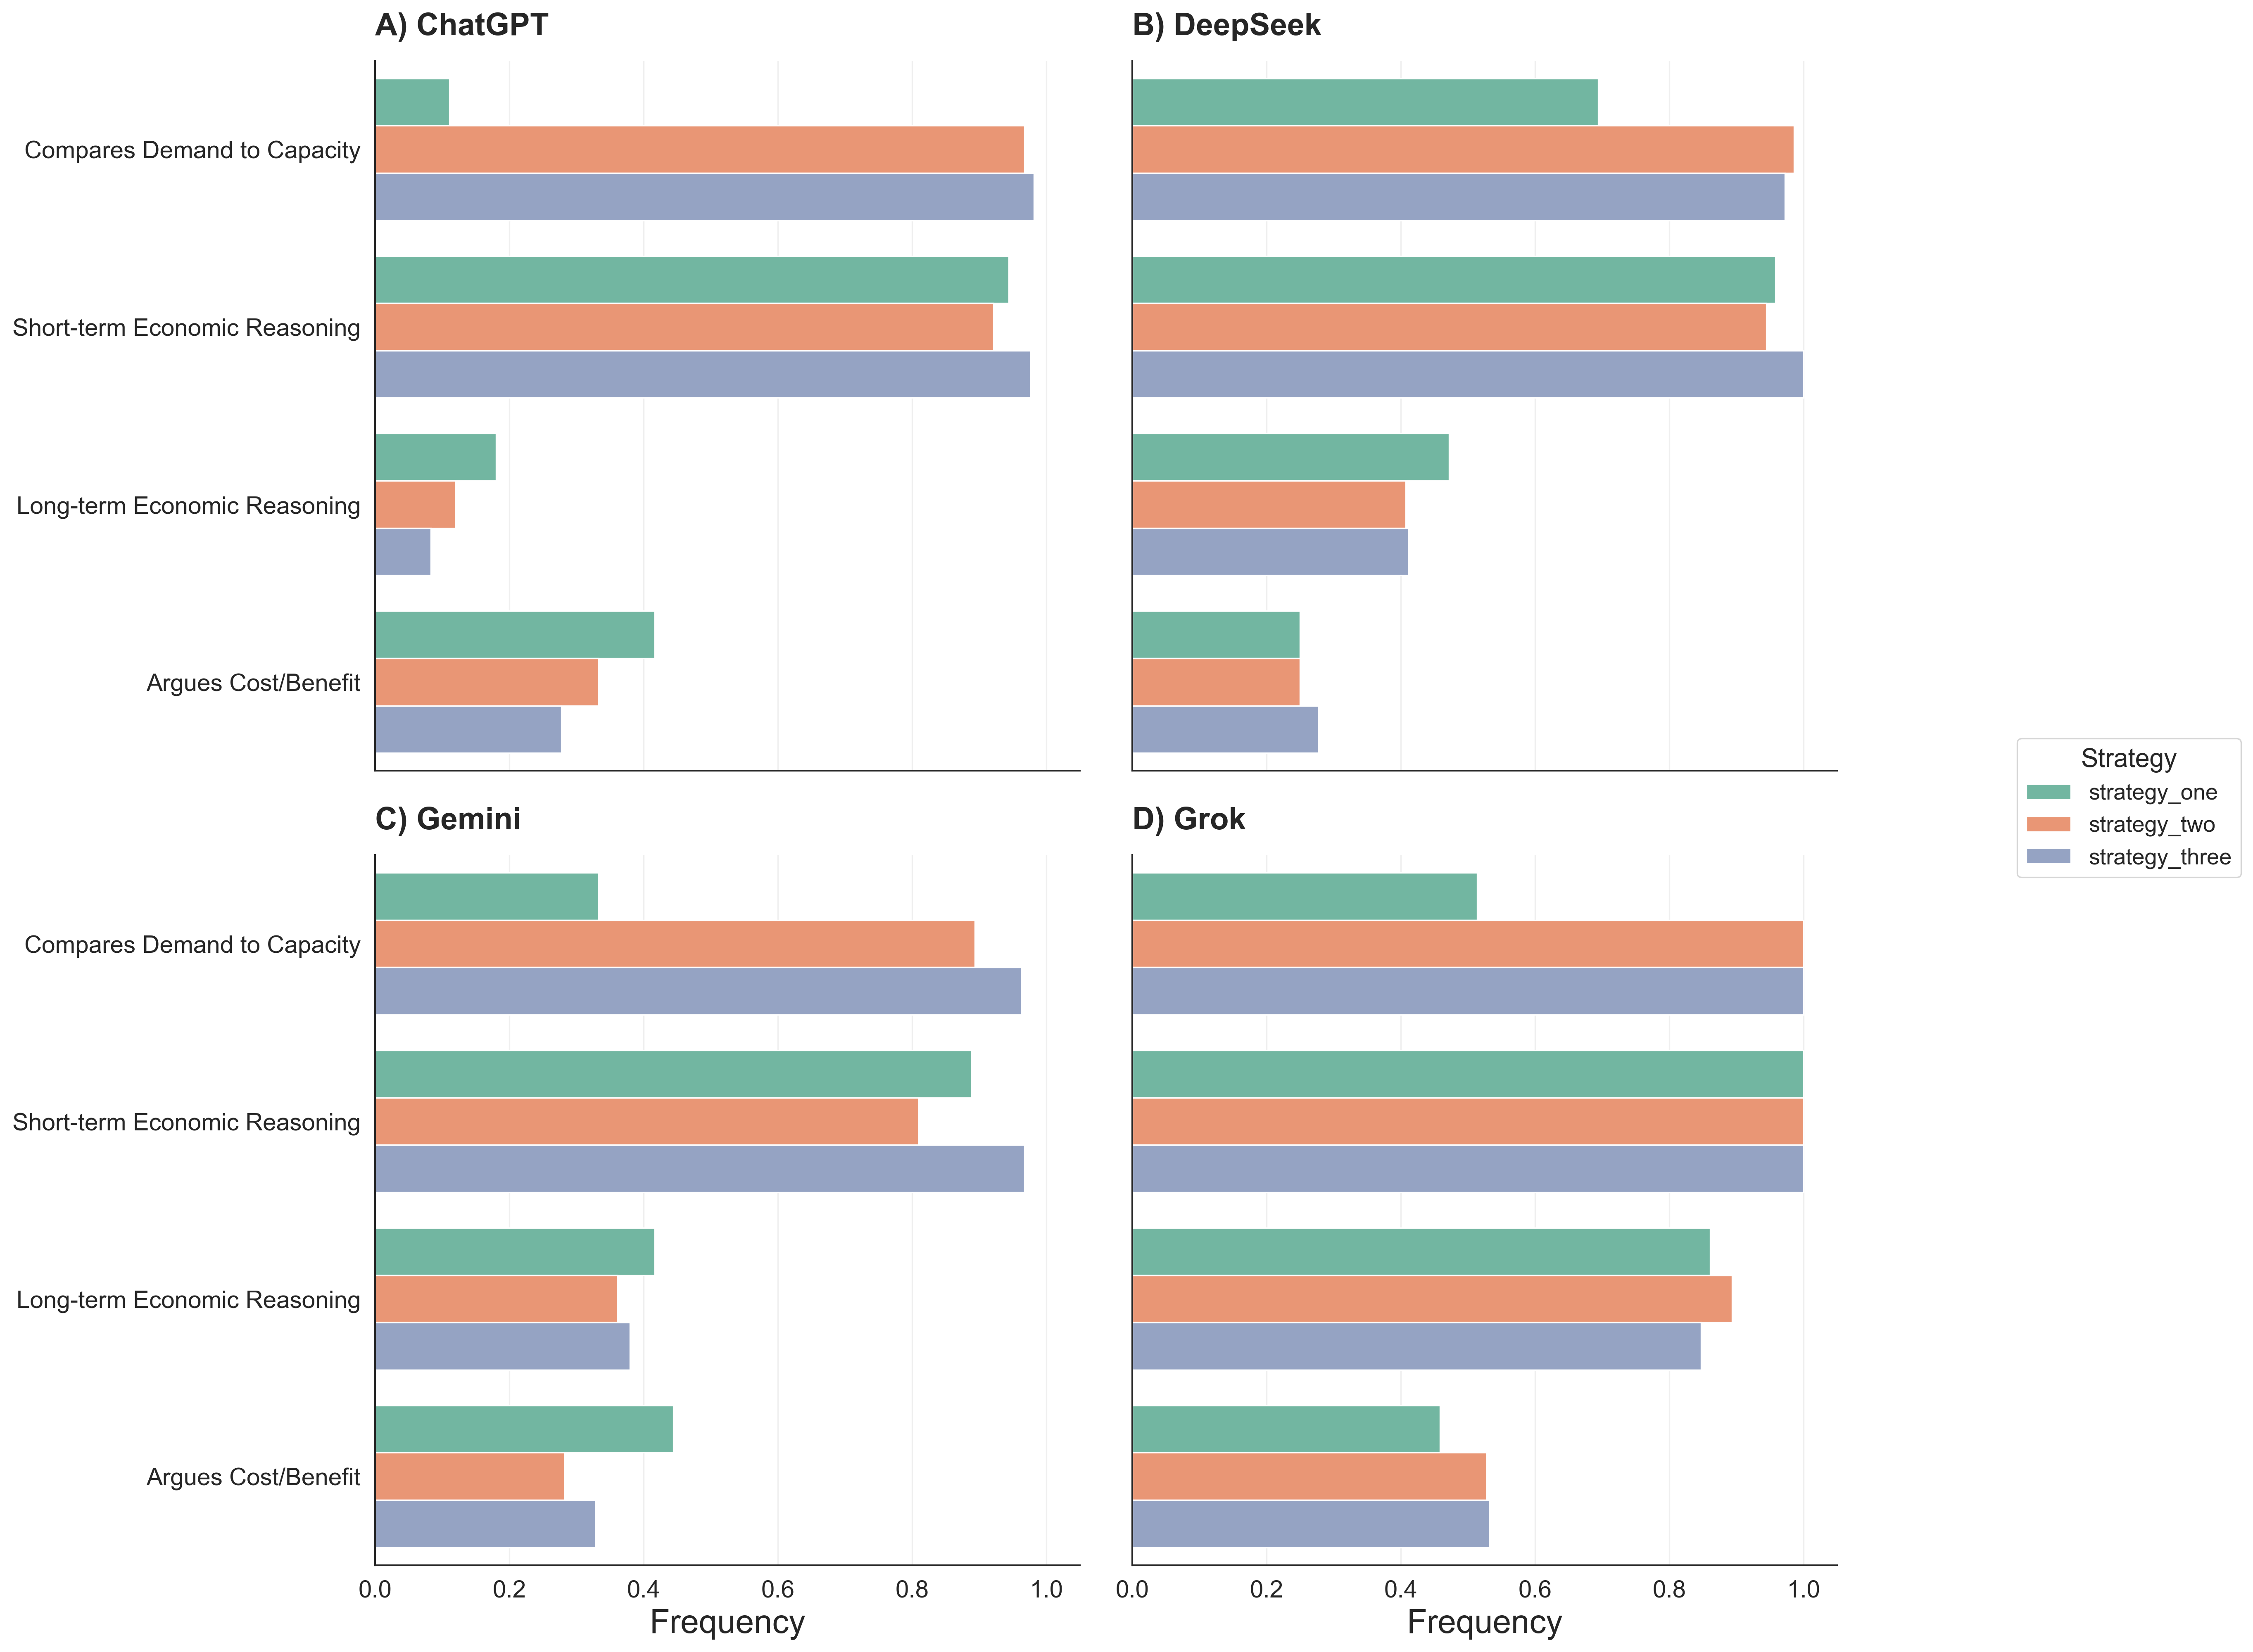

In [28]:
if not reasoning_df.empty:

    # 1) Choose which components to include (controls the y-axis)
    included_cols = [
        'compares_demand_to_capacity',
        'short_term_economic_reasoning',
        'long_term_economic_reasoning',
        'argues_closures_not_worth_it_given_infections',
    ]

    # 2) Strategies -> hue (omit strategy_four)
    strategies_order = ['strategy_one', 'strategy_two', 'strategy_three']
    strategies_present = [s for s in strategies_order if s in reasoning_df['strategy'].unique()]

    # 3) Long-form data (filter to strategies 1-3 first)
    df_reasoning = reasoning_df[reasoning_df['strategy'].isin(strategies_present)].melt(
        id_vars=['model', 'strategy', 'choice_status'],
        value_vars=included_cols,
        var_name='component',
        value_name='present'
    )
    df_reasoning['component_label'] = df_reasoning['component'].apply(get_column_label)

    # Keep y-axis order consistent across panels
    component_order = [get_column_label(c) for c in included_cols]

    # Panels -> models
    models_sorted = sorted(df_reasoning['model'].unique())
    n_models = len(models_sorted)

    # 4) Grid sized to number of models (keeps same 2x2 behavior if there are 4 models)
    n_cols = 2
    n_rows = int(np.ceil(n_models / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=FIG_SIZE_MULTI, sharex=True, sharey=True)
    axes = np.array(axes).reshape(-1)  # robust flatten

    for i, model in enumerate(models_sorted):
        ax = axes[i]
        sub = df_reasoning[df_reasoning['model'] == model].copy()

        sns.barplot(
            data=sub,
            x='present',
            y='component_label',
            hue='strategy',
            hue_order=strategies_present,   # strategy hue order [web:202]
            palette='Set2',                 # or provide your own STRATEGY_COLORS dict
            order=component_order,
            errorbar=None,
            ax=ax,
            orient='h'
        )

        ax.set_title(
            f'{string.ascii_uppercase[i]}) {model}',
            fontsize=18, pad=15, fontweight='bold', loc='left'
        )
        ax.set_xlabel('Frequency')
        ax.set_ylabel('')
        ax.tick_params(axis='y', labelsize=14)
        ax.tick_params(axis='x', labelsize=14)
        ax.grid(axis='x', alpha=0.3)

        # Remove per-axis legends; add one figure legend after loop
        if ax.get_legend():
            ax.get_legend().remove()

    # Hide unused axes
    for j in range(n_models, len(axes)):
        axes[j].set_visible(False)

    # One shared legend (strategy legend)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        title='Strategy',
        loc='center right',
        bbox_to_anchor=(1.02, 0.5),
        fontsize=13,
        title_fontsize=15,
        frameon=True
    )

    sns.despine()
    fig.suptitle('')
    plt.tight_layout(rect=[0, 0, 0.85, 1.0])
    plt.show()


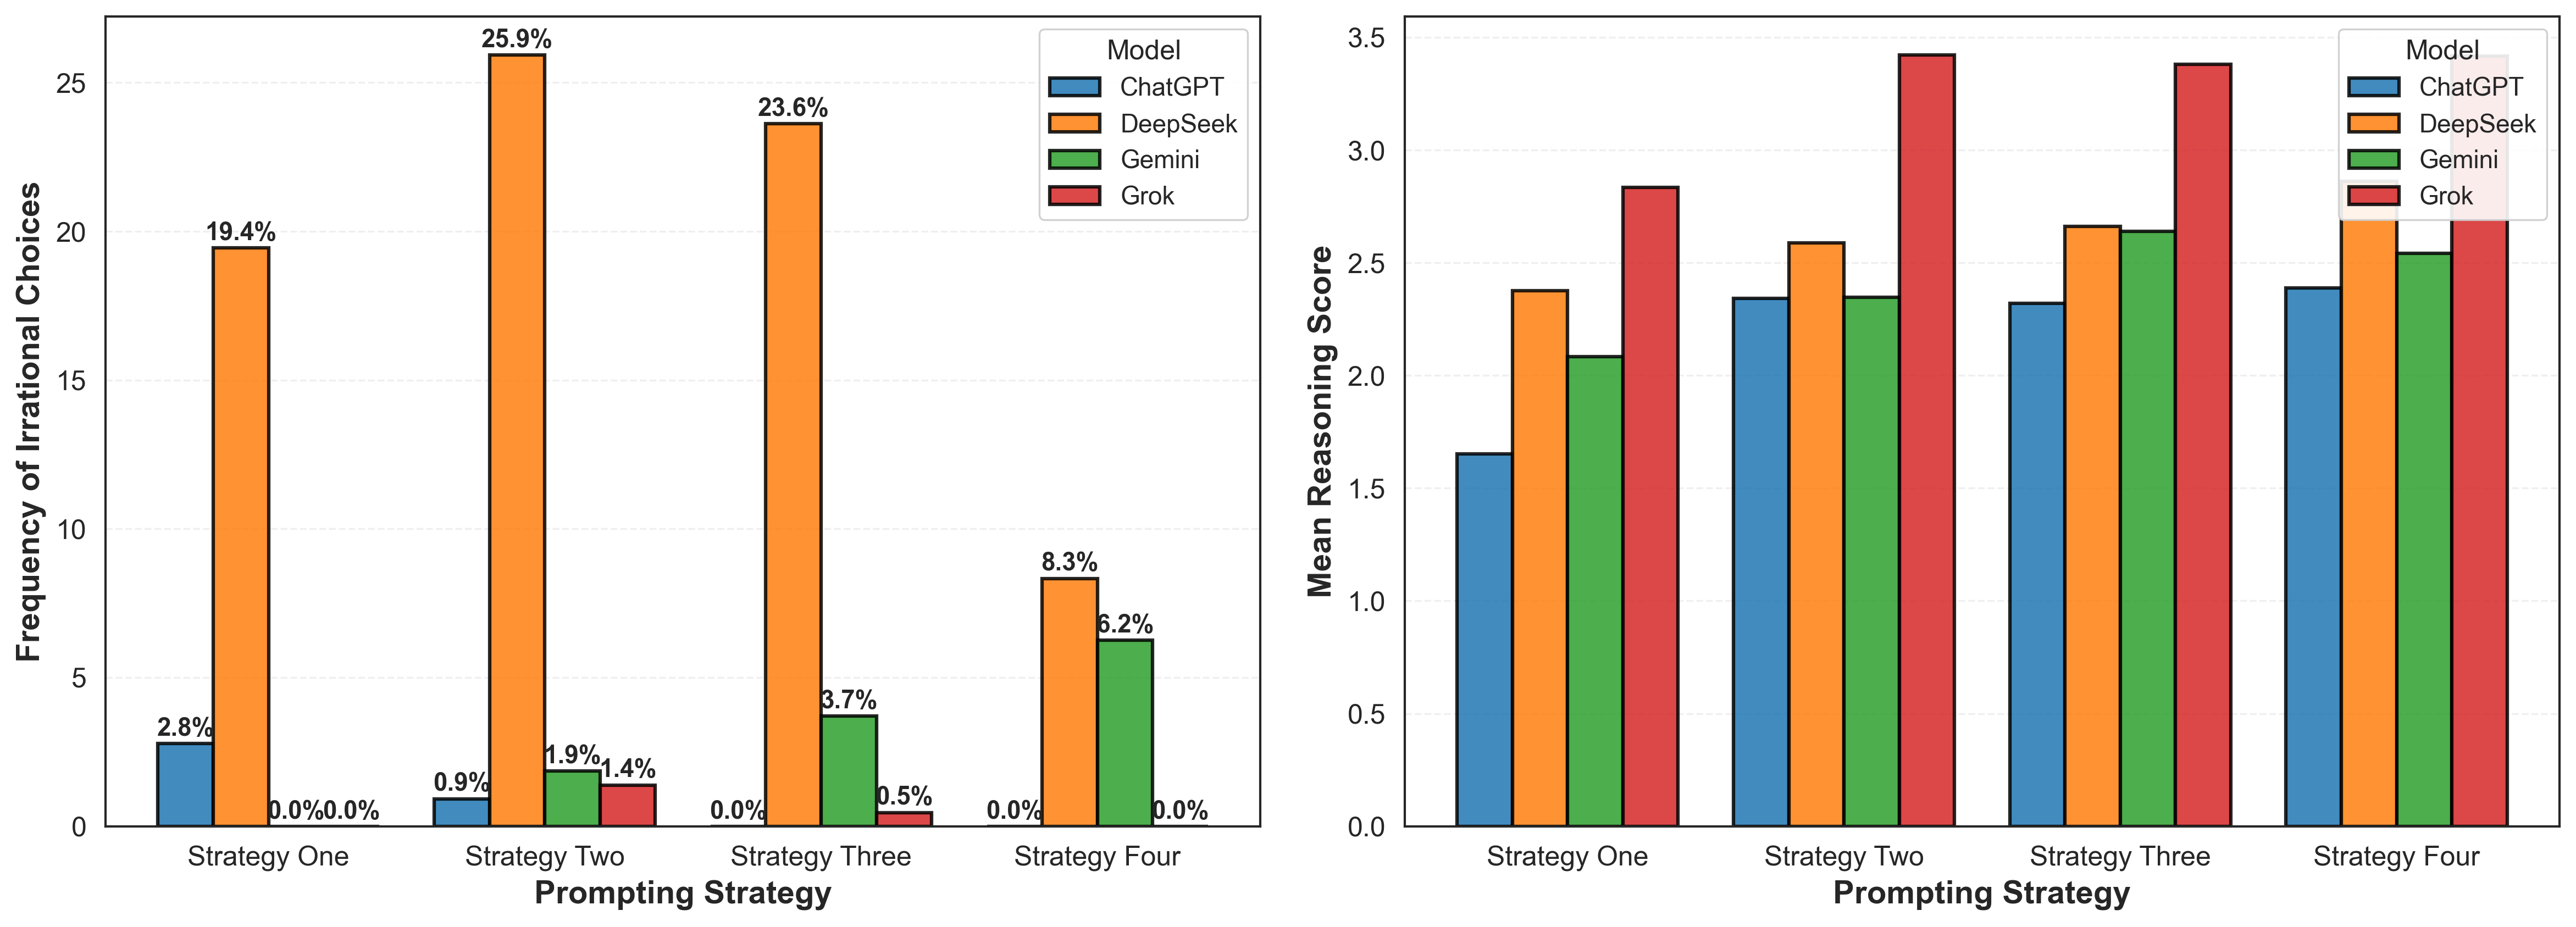

In [29]:
if (not results_df.empty) and (not reasoning_df.empty):

    # -----------------------------
    # Settings: which reasoning cols
    # -----------------------------
    included_cols = [
        'compares_demand_to_capacity',
        'short_term_economic_reasoning',
        'long_term_economic_reasoning',
        'argues_closures_not_worth_it_given_infections',
    ]

    # -----------------------------
    # Panel A data: Irrationality
    # -----------------------------
    freq_data = results_df.groupby(['strategy', 'model'])['irrational_choice'].agg(
        irrational_rate='mean'
    ).reset_index()
    freq_data['irrational_percentage'] = freq_data['irrational_rate'] * 100

    strategies_sorted = sorted(freq_data['strategy'].unique(), key=extract_strategy_number)
    models_sorted = sorted(freq_data['model'].unique())
    n_strategies = len(strategies_sorted)
    n_models = len(models_sorted)

    # -----------------------------
    # Panel B data: Reasoning score
    # -----------------------------
    # Make sure needed columns exist
    missing = [c for c in included_cols if c not in reasoning_df.columns]
    if missing:
        raise ValueError(f"Missing reasoning columns in reasoning_df: {missing}")

    reasoning_tmp = reasoning_df.copy()

    # Convert to 0/1 safely (avoid NaN -> True surprises) [web:187]
    for c in included_cols:
        reasoning_tmp[c] = reasoning_tmp[c].fillna(False).astype(bool).astype(int)

    # Row-wise sum across included columns => reasoning score [web:253]
    reasoning_tmp['reasoning_score'] = reasoning_tmp[included_cols].sum(axis=1)

    reasoning_score_df = (
        reasoning_tmp
        .groupby(['strategy', 'model'])['reasoning_score']
        .mean()
        .reset_index()
    )

    # Keep strategy/model ordering aligned with panel A where possible
    strategies_sorted_B = [s for s in strategies_sorted if s in reasoning_score_df['strategy'].unique()]
    models_sorted_B = [m for m in models_sorted if m in reasoning_score_df['model'].unique()]
    n_strategies_B = len(strategies_sorted_B)
    n_models_B = len(models_sorted_B)

    # -----------------------------
    # Plot: 2 panels
    # -----------------------------
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # ===== Panel A: Irrationality grouped bars =====
    x = np.arange(n_strategies)
    width = 0.8 / n_models

    for idx, model in enumerate(models_sorted):
        model_data = (
            freq_data[freq_data['model'] == model]
            .sort_values('strategy', key=lambda col: col.map({s: i for i, s in enumerate(strategies_sorted)}))
        )

        offset = width * (idx - n_models / 2 + 0.5)

        bars = ax1.bar(
            x + offset,
            model_data['irrational_percentage'],
            width,
            label=model,
            color=MODEL_COLORS.get(model, None),
            edgecolor='black',
            linewidth=1.5,
            alpha=0.85
        )

        for bar in bars:
            height = bar.get_height()
            ax1.text(
                bar.get_x() + bar.get_width() / 2.0,
                height + 0.1,
                f'{height:.1f}%',
                ha='center',
                va='bottom',
                fontsize=11,
                fontweight='bold'
            )

    ax1.set_xlabel('Prompting Strategy', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Frequency of Irrational Choices', fontsize=14, fontweight='bold')
    ax1.set_title('')
    ax1.set_xticks(x)
    ax1.set_xticklabels([s.replace("_", " ").title() for s in strategies_sorted], fontsize=12, rotation=0, ha='center')
    ax1.tick_params(axis='y', labelsize=12)
    ax1.grid(axis='y', alpha=0.3, linestyle='--')
    ax1.legend(title='Model', fontsize=11, title_fontsize=12, loc='upper right', framealpha=0.9)

    # ===== Panel B: Reasoning score grouped bars =====
    xB = np.arange(n_strategies_B)
    widthB = 0.8 / max(1, n_models_B)

    for idx, model in enumerate(models_sorted_B):
        model_data = (
            reasoning_score_df[reasoning_score_df['model'] == model]
            .sort_values('strategy', key=lambda col: col.map({s: i for i, s in enumerate(strategies_sorted_B)}))
        )

        offset = widthB * (idx - n_models_B / 2 + 0.5)

        ax2.bar(
            xB + offset,
            model_data['reasoning_score'],
            widthB,
            label=model,
            color=MODEL_COLORS.get(model, None),
            edgecolor='black',
            linewidth=1.5,
            alpha=0.85
        )

    ax2.set_xlabel('Prompting Strategy', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Mean Reasoning Score', fontsize=14, fontweight='bold')
    ax2.set_title('')
    ax2.set_xticks(xB)
    ax2.set_xticklabels([s.replace("_", " ").title() for s in strategies_sorted_B], fontsize=12, rotation=0, ha='center')
    ax2.tick_params(axis='y', labelsize=12)
    ax2.grid(axis='y', alpha=0.3, linestyle='--')
    ax2.legend(title='Model', fontsize=11, title_fontsize=12, loc='upper right', framealpha=0.9)

    plt.tight_layout()
    plt.show()


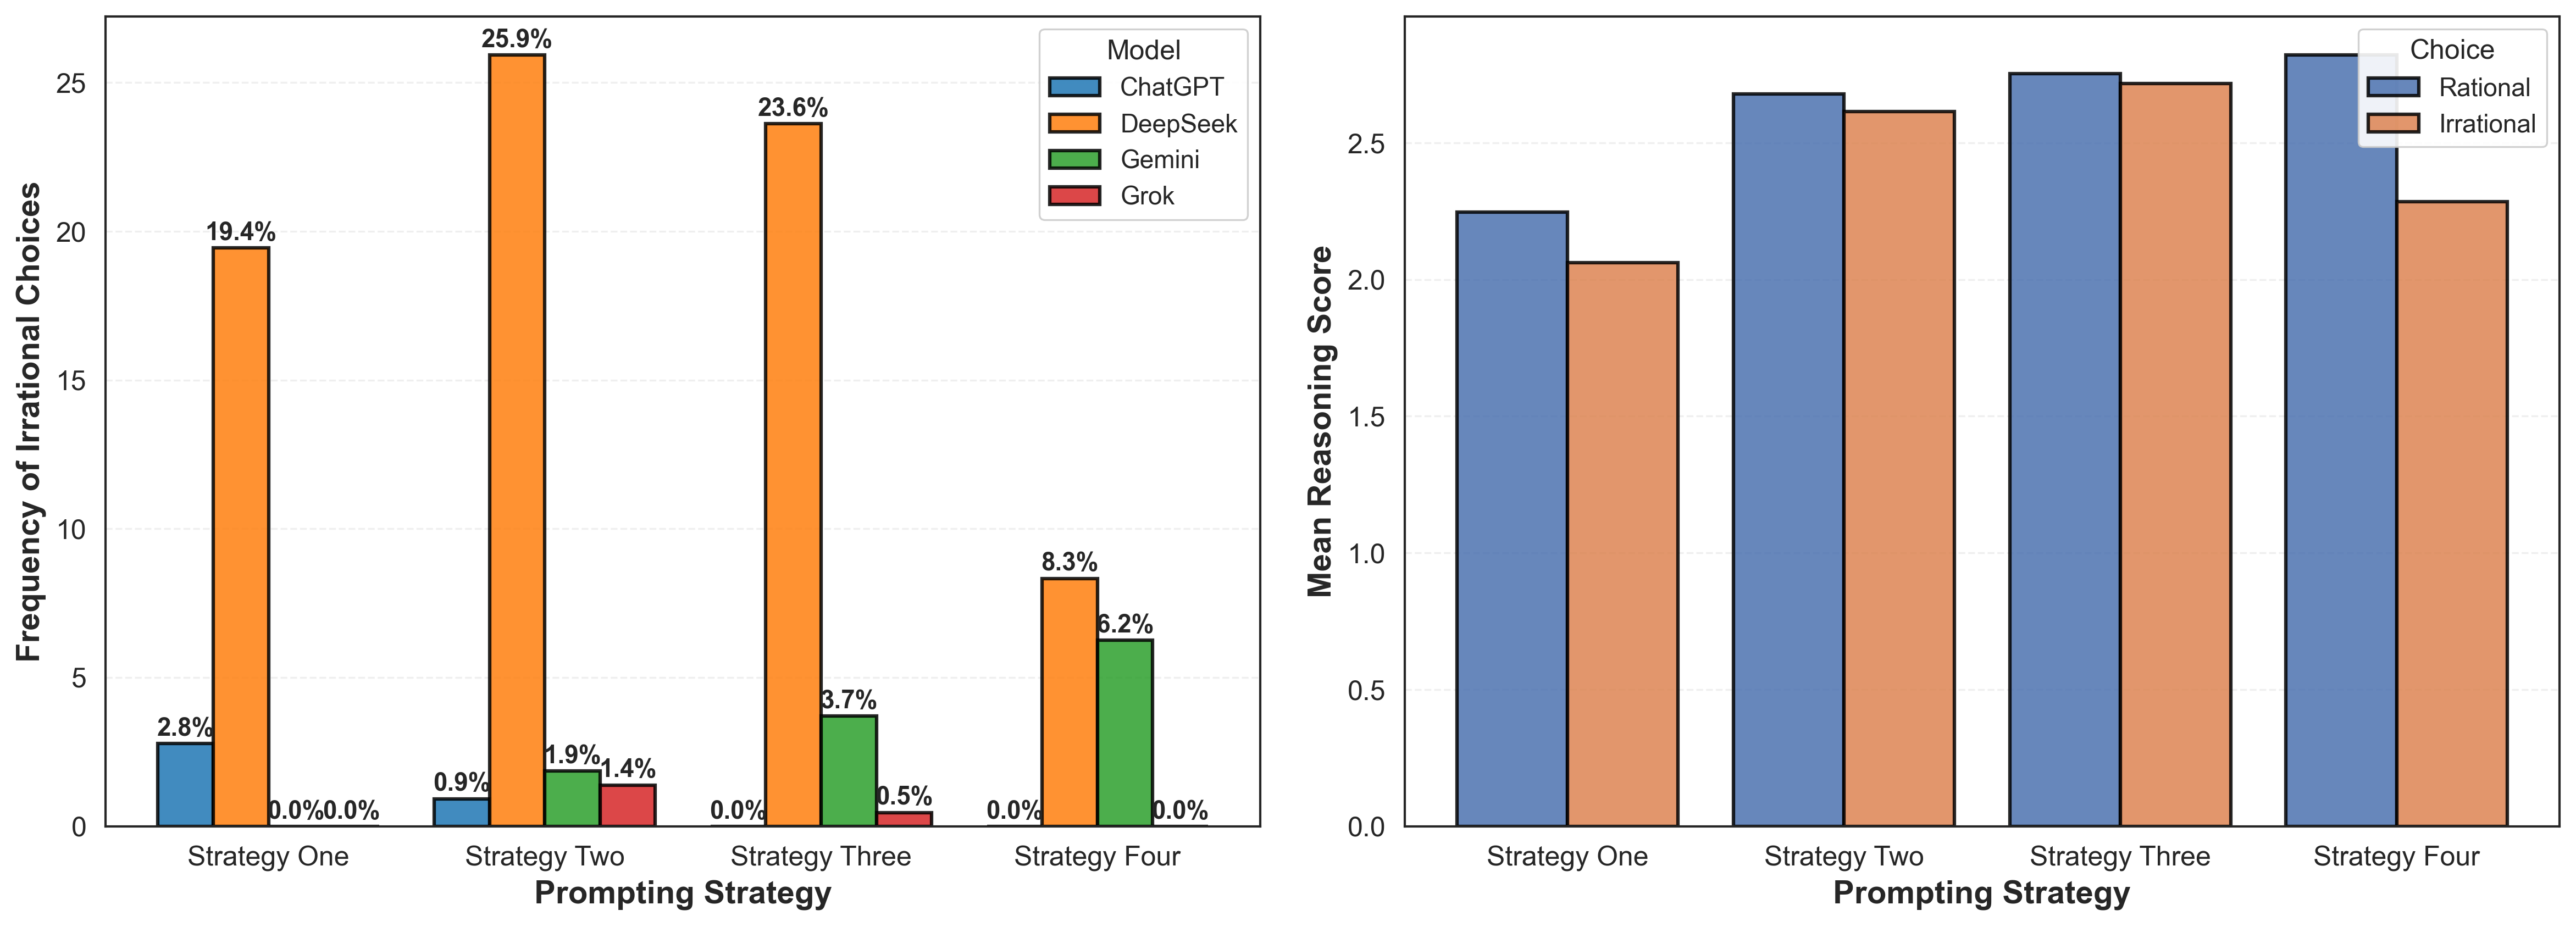

In [30]:
if (not results_df.empty) and (not reasoning_df.empty):

    included_cols = [
        'compares_demand_to_capacity',
        'short_term_economic_reasoning',
        'long_term_economic_reasoning',
        'argues_closures_not_worth_it_given_infections',
    ]

    # -----------------------------
    # Panel A: Irrationality (unchanged)
    # -----------------------------
    freq_data = results_df.groupby(['strategy', 'model'])['irrational_choice'].agg(
        irrational_rate='mean'
    ).reset_index()
    freq_data['irrational_percentage'] = freq_data['irrational_rate'] * 100

    strategies_sorted = sorted(freq_data['strategy'].unique(), key=extract_strategy_number)
    models_sorted = sorted(freq_data['model'].unique())
    n_strategies = len(strategies_sorted)
    n_models = len(models_sorted)

    # -----------------------------
    # Panel B: Reasoning score by strategy × rational/irrational
    # -----------------------------
    missing = [c for c in included_cols if c not in reasoning_df.columns]
    if missing:
        raise ValueError(f"Missing reasoning columns in reasoning_df: {missing}")

    r = reasoning_df.copy()

    # Convert each component to 0/1 safely (NaN -> False) [web:187]
    for c in included_cols:
        r[c] = r[c].fillna(False).astype(bool).astype(int)

    r['reasoning_score'] = r[included_cols].sum(axis=1)

    # Create hue variable: Rational vs Irrational
    r['rationality'] = np.where(r['irrational_choice'].fillna(False), 'Irrational', 'Rational')

    reasoning_score_df = (
        r.groupby(['strategy', 'rationality'])['reasoning_score']
         .mean()
         .reset_index()
    )

    # Keep strategy order aligned with panel A
    strategies_sorted_B = [s for s in strategies_sorted if s in reasoning_score_df['strategy'].unique()]
    xB = np.arange(len(strategies_sorted_B))
    hue_order = ['Rational', 'Irrational']
    n_hues = len(hue_order)
    widthB = 0.8 / n_hues

    # -----------------------------
    # Plot: 2 panels
    # -----------------------------
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # ===== Panel A =====
    x = np.arange(n_strategies)
    width = 0.8 / n_models

    for idx, model in enumerate(models_sorted):
        model_data = (
            freq_data[freq_data['model'] == model]
            .sort_values('strategy', key=lambda col: col.map({s: i for i, s in enumerate(strategies_sorted)}))
        )
        offset = width * (idx - n_models/2 + 0.5)
        bars = ax1.bar(
            x + offset,
            model_data['irrational_percentage'],
            width,
            label=model,
            color=MODEL_COLORS.get(model, None),
            edgecolor='black',
            linewidth=1.5,
            alpha=0.85
        )
        for bar in bars:
            h = bar.get_height()
            ax1.text(bar.get_x() + bar.get_width()/2.0, h + 0.1, f'{h:.1f}%',
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

    ax1.set_xlabel('Prompting Strategy', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Frequency of Irrational Choices', fontsize=14, fontweight='bold')
    ax1.set_title('')
    ax1.set_xticks(x)
    ax1.set_xticklabels([s.replace("_", " ").title() for s in strategies_sorted],
                        fontsize=12, rotation=0, ha='center')
    ax1.tick_params(axis='y', labelsize=12)
    ax1.grid(axis='y', alpha=0.3, linestyle='--')
    ax1.legend(title='Model', fontsize=11, title_fontsize=12, loc='upper right', framealpha=0.9)

    # ===== Panel B =====
    for idx, grp in enumerate(hue_order):
        grp_data = (
            reasoning_score_df[reasoning_score_df['rationality'] == grp]
            .set_index('strategy')
            .reindex(strategies_sorted_B)
            .reset_index()
        )
        offset = widthB * (idx - n_hues/2 + 0.5)
        ax2.bar(
            xB + offset,
            grp_data['reasoning_score'],
            widthB,
            label=grp,
            color=('#4C72B0' if grp == 'Rational' else '#DD8452'),
            edgecolor='black',
            linewidth=1.5,
            alpha=0.85
        )

    ax2.set_xlabel('Prompting Strategy', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Mean Reasoning Score', fontsize=14, fontweight='bold')
    ax2.set_title('')
    ax2.set_xticks(xB)
    ax2.set_xticklabels([s.replace("_", " ").title() for s in strategies_sorted_B],
                        fontsize=12, rotation=0, ha='center')
    ax2.tick_params(axis='y', labelsize=12)
    ax2.grid(axis='y', alpha=0.3, linestyle='--')
    ax2.legend(title='Choice', fontsize=11, title_fontsize=12, loc='upper right', framealpha=0.9)

    plt.tight_layout()
    plt.show()


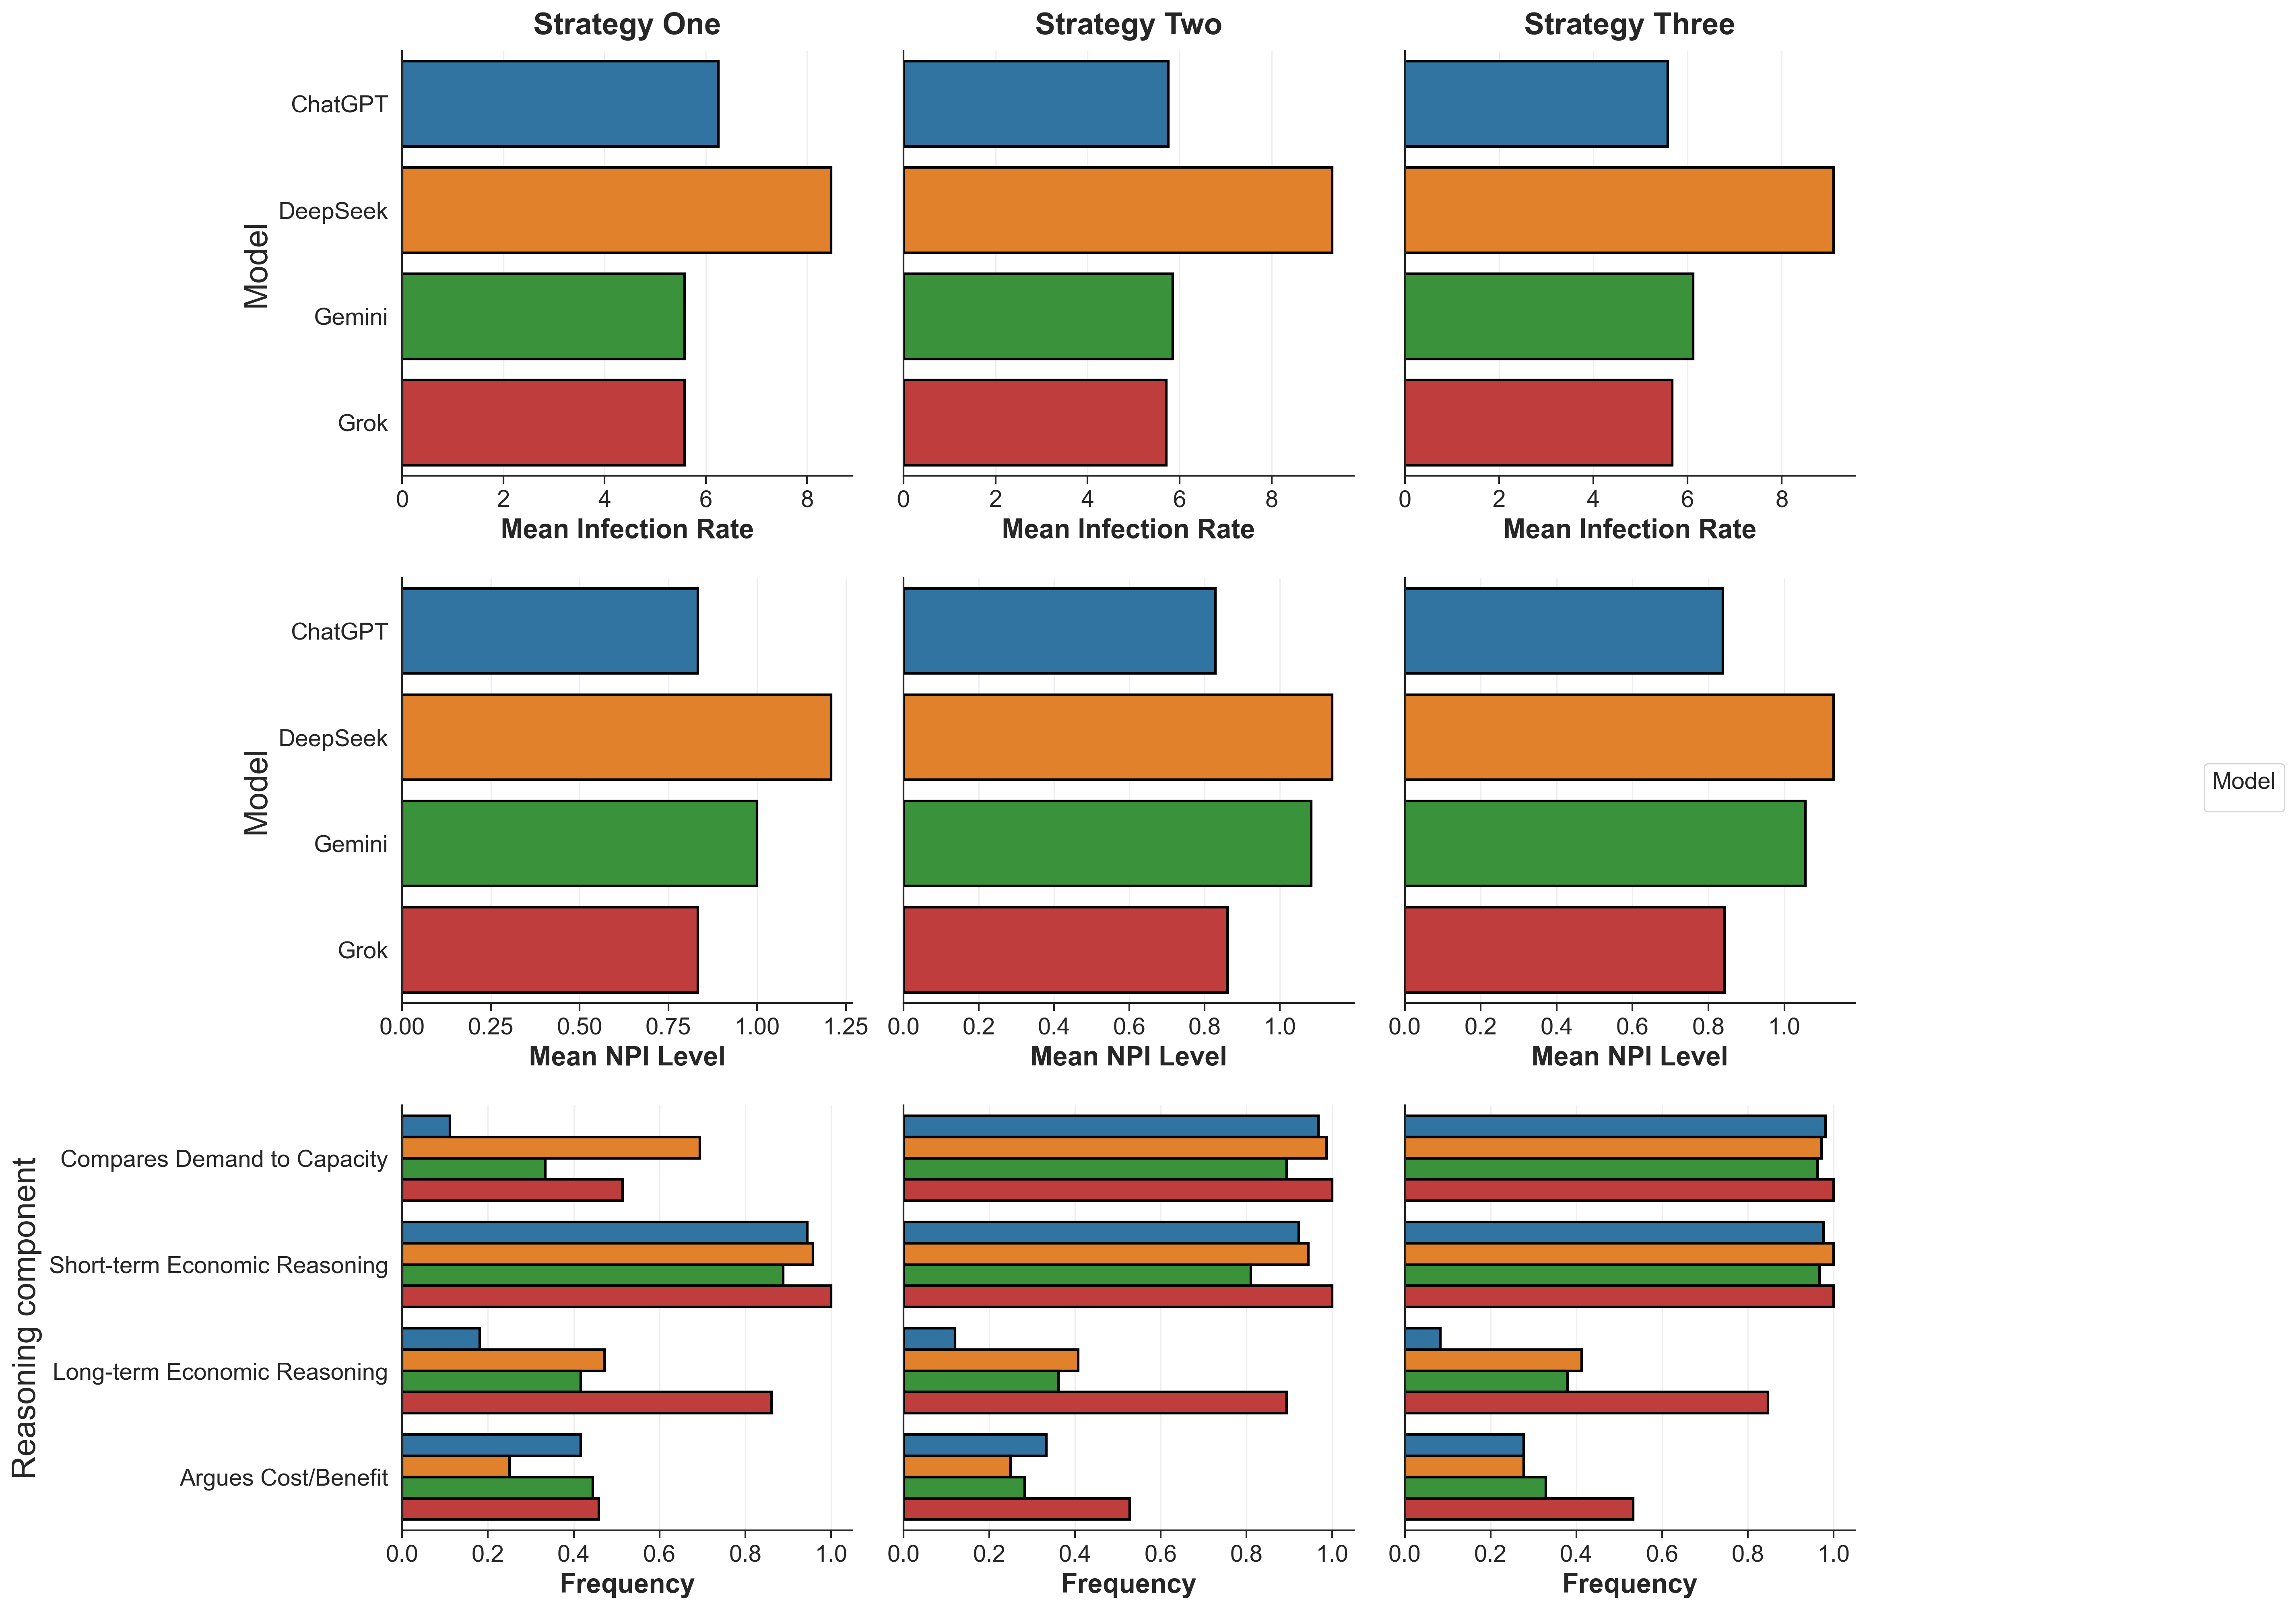

In [26]:
if (not results_df.empty) and (not reasoning_df.empty):

    # -----------------------
    # Settings / inclusion
    # -----------------------
    strategies_sorted = ['strategy_one', 'strategy_two', 'strategy_three']  # omit strategy_four
    included_components = [
        'compares_demand_to_capacity',
        'short_term_economic_reasoning',
        'long_term_economic_reasoning',
        'argues_closures_not_worth_it_given_infections',
    ]
    component_order = [get_column_label(c) for c in included_components]

    # Filter data
    plot_results = results_df[results_df['strategy'].isin(strategies_sorted)].copy()
    plot_reasoning = reasoning_df[reasoning_df['strategy'].isin(strategies_sorted)].copy()

    # Model ordering + colors
    models_sorted = sorted(plot_results['model'].unique())

    # -----------------------
    # Prepare reasoning long df
    # -----------------------
    df_reasoning = plot_reasoning.melt(
        id_vars=['model', 'strategy', 'choice_status'],
        value_vars=included_components,
        var_name='component',
        value_name='present'
    )
    df_reasoning['component_label'] = df_reasoning['component'].apply(get_column_label)

    # -----------------------
    # Figure grid: 3 rows x 3 cols
    # -----------------------
    fig, axes = plt.subplots(
        3, 3,
        figsize=FIG_SIZE_MULTI,
        sharey='row'   # share y within each row
    )

    # ---- Row 1: Infection rate (one column per strategy)
    for j, strat in enumerate(strategies_sorted):
        ax = axes[0, j]
        sub = plot_results[plot_results['strategy'] == strat]

        sns.barplot(
            data=sub,
            x='infection_rate_selected',
            y='model',
            hue='model',
            hue_order=models_sorted,
            order=models_sorted,
            palette=MODEL_COLORS,
            orient='h',
            errorbar=None,
            ax=ax,
            edgecolor='black',
            linewidth=1.5
        )

        ax.set_title(
            f'{strat.replace("_", " ").title()}',
            fontsize=18, fontweight='bold', loc='center', pad=10
        )
        ax.grid(axis='x', alpha=0.3)
        ax.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
        ax.tick_params(axis='y', labelsize=14, labelleft=(j == 0))
        ax.set_xlabel('Mean Infection Rate', fontsize=16, fontweight='bold')
        ax.set_ylabel('Model' if j == 0 else '')

        if ax.get_legend():
            ax.get_legend().remove()

    # ---- Row 2: NPI level
    for j, strat in enumerate(strategies_sorted):
        ax = axes[1, j]
        sub = plot_results[plot_results['strategy'] == strat]

        sns.barplot(
            data=sub,
            x='npi_level_selected',
            y='model',
            hue='model',
            hue_order=models_sorted,
            order=models_sorted,
            palette=MODEL_COLORS,
            orient='h',
            errorbar=None,
            ax=ax,
            edgecolor='black',
            linewidth=1.5
        )

        ax.grid(axis='x', alpha=0.3)
        ax.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
        ax.tick_params(axis='y', labelsize=14, labelleft=(j == 0))
        ax.set_xlabel('Mean NPI Level', fontsize=16, fontweight='bold')
        ax.set_ylabel('Model' if j == 0 else '')

        if ax.get_legend():
            ax.get_legend().remove()

    # ---- Row 3: Reasoning components (y = component, hue=model)
    for j, strat in enumerate(strategies_sorted):
        ax = axes[2, j]
        sub = df_reasoning[df_reasoning['strategy'] == strat]

        sns.barplot(
            data=sub,
            x='present',
            y='component_label',
            hue='model',
            hue_order=models_sorted,
            order=component_order,
            palette=MODEL_COLORS,
            orient='h',
            errorbar=None,
            ax=ax,
            edgecolor='black',
            linewidth=1.5
        )

        ax.grid(axis='x', alpha=0.3)
        ax.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
        ax.tick_params(axis='y', labelsize=14, labelleft=(j == 0))
        ax.set_xlabel('Frequency', fontsize=16, fontweight='bold')
        ax.set_ylabel('Reasoning component' if j == 0 else '')

        if ax.get_legend():
            ax.get_legend().remove()

    # ---- One shared legend for the whole figure
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        title='Model',
        bbox_to_anchor=(1.02, 0.5),
        loc='center left',
        fontsize=12,
        title_fontsize=14,
        frameon=True
    )

    fig.suptitle('')  # remove main title

    sns.despine()
    plt.tight_layout(rect=[0, 0, 0.88, 1.0])
    plt.show()


/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/1775256198.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axA.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/1775256198.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axB.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/1775256198.py:93: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axC.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/1775256198.py:123: User

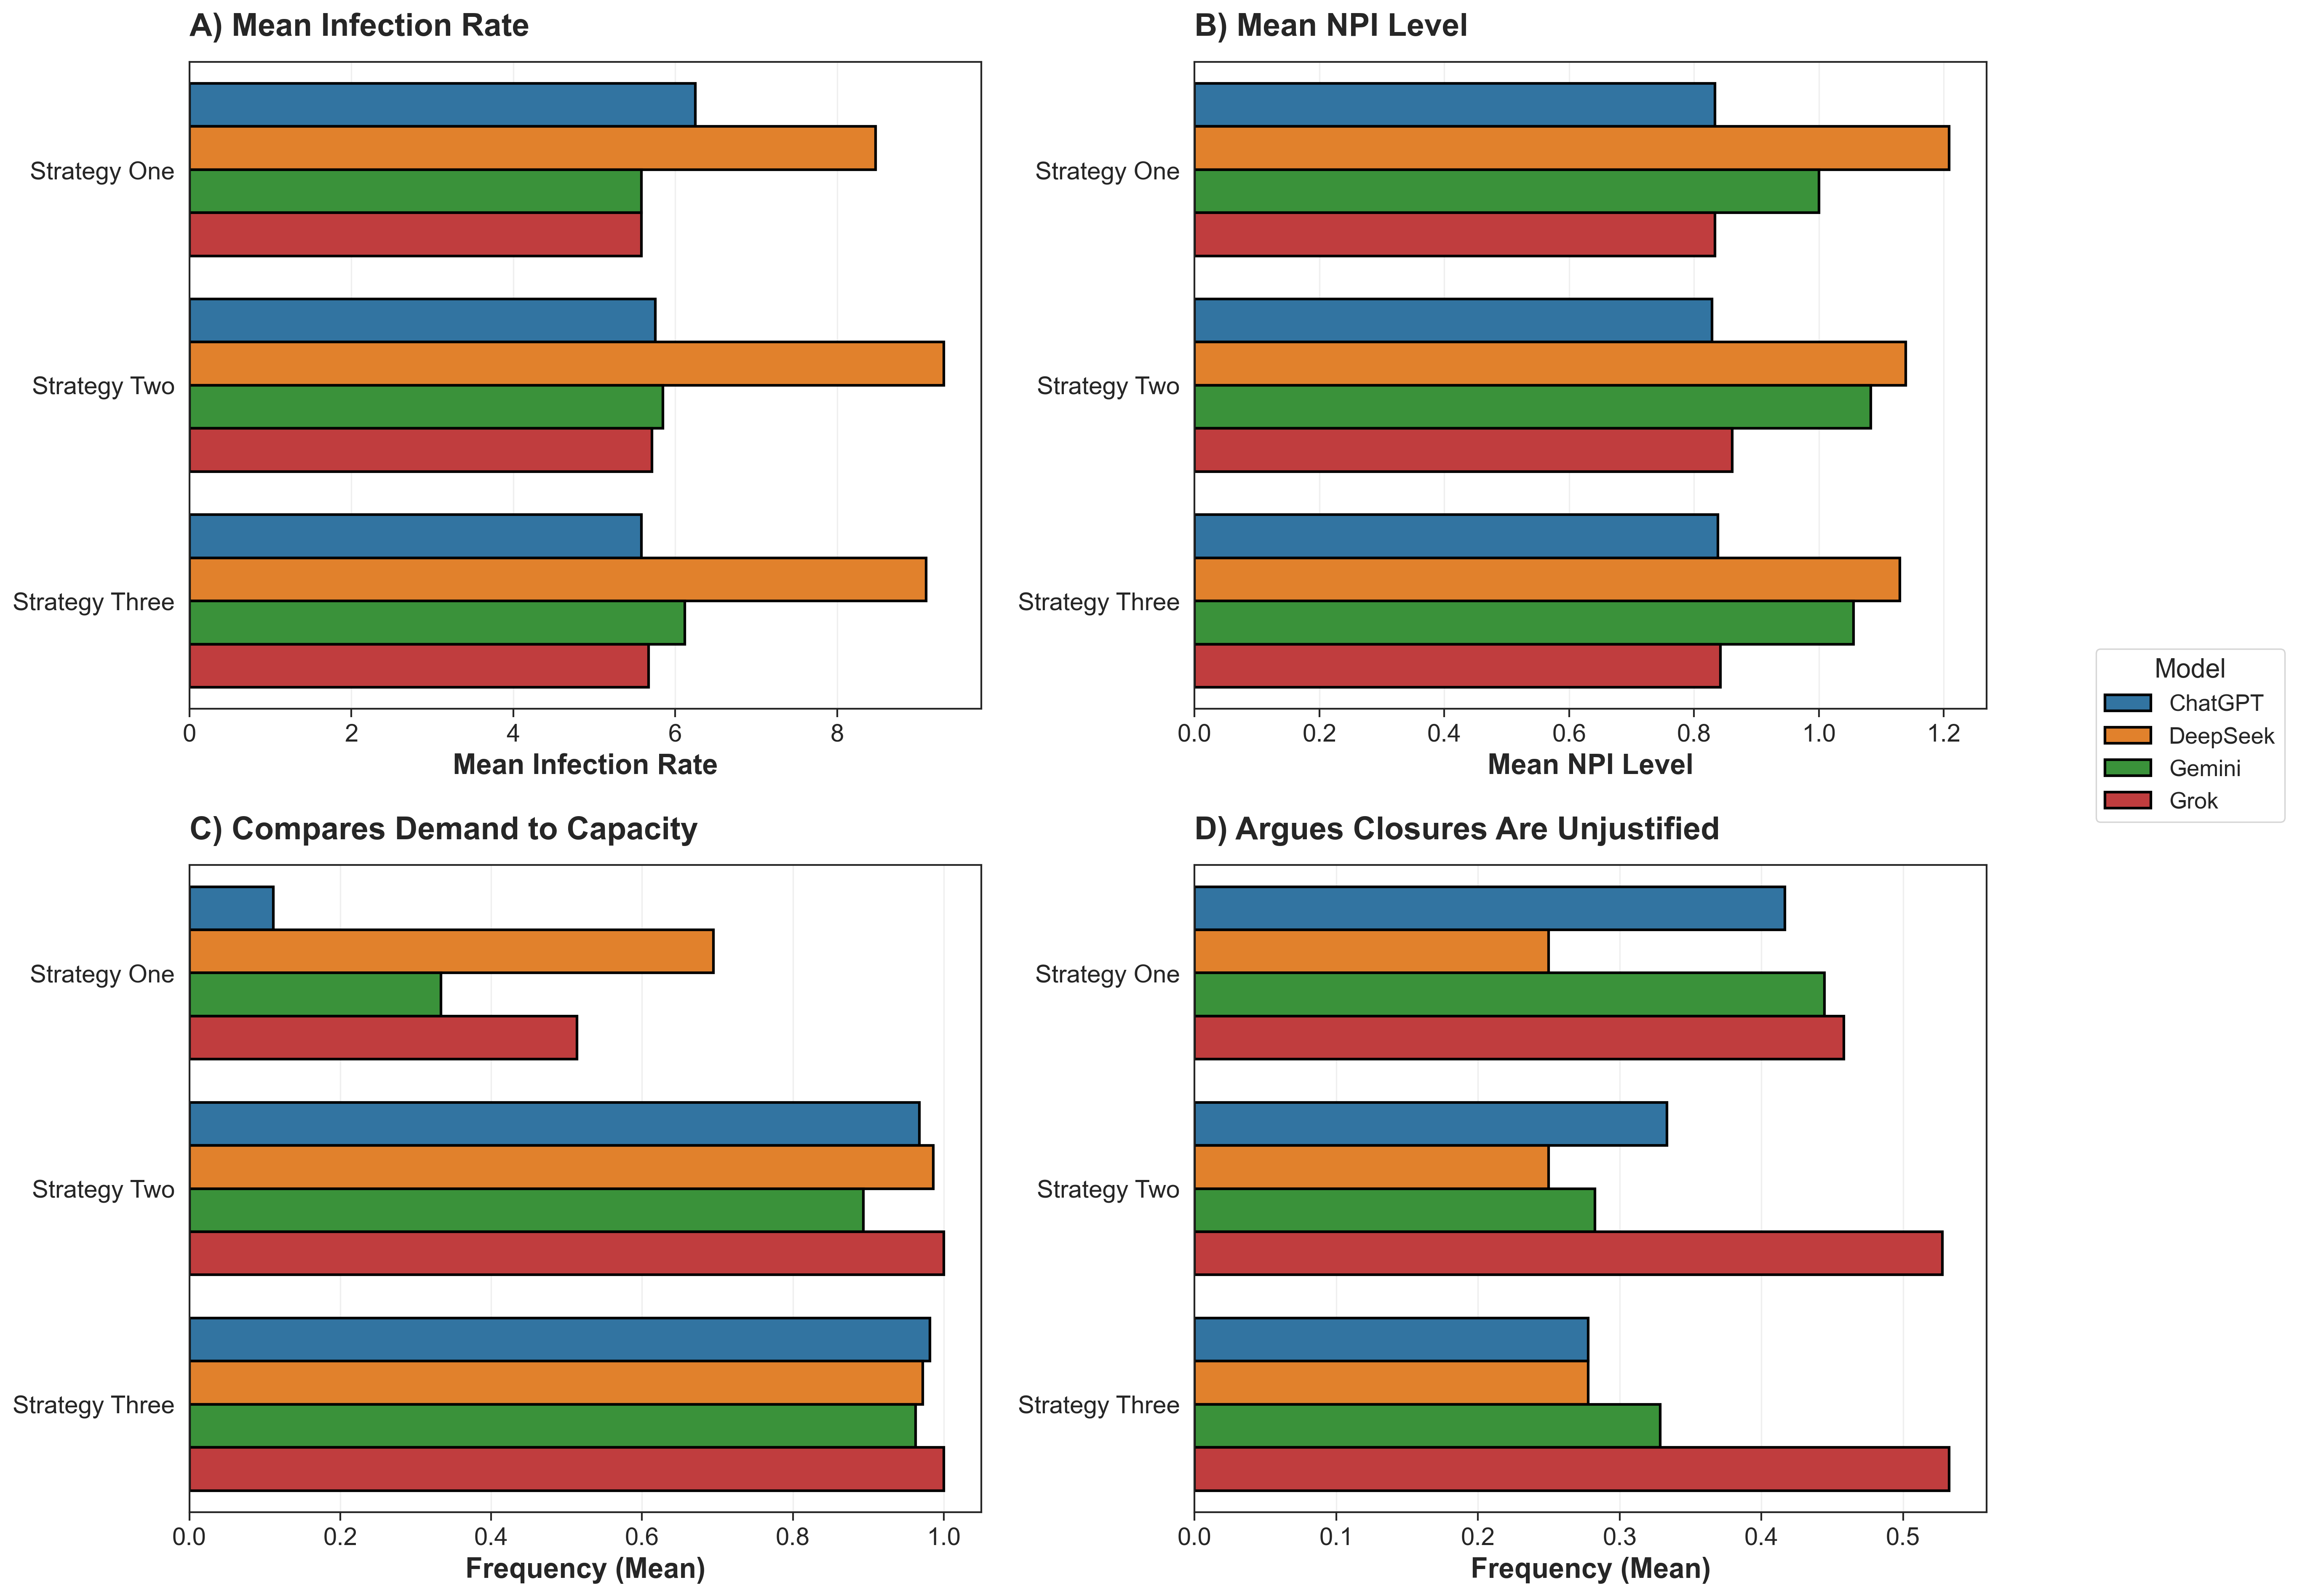

In [21]:
# ---- 4-panel figure for strategies 1–4 (all bar plots; A/B/C/D hue=model) ----
if (not results_df.empty) and (not reasoning_df.empty):

    keep_strategies = ['strategy_one', 'strategy_two', 'strategy_three']
    plot_results = results_df[results_df['strategy'].isin(keep_strategies)].copy()
    plot_reasoning = reasoning_df[reasoning_df['strategy'].isin(keep_strategies)].copy()

    strategies_sorted = [s for s in keep_strategies if s in plot_results['strategy'].unique()]

    # Ensure consistent model order
    models_sorted = sorted(plot_results['model'].unique())

    fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE_MULTI)
    axes = axes.flatten()

    # ----------------
    # Panel A: Mean infection rate by strategy, hue=model
    # ----------------
    axA = axes[0]
    sns.barplot(
        data=plot_results,
        x='infection_rate_selected',
        y='strategy',
        hue='model',
        order=strategies_sorted,
        hue_order=models_sorted,
        palette=MODEL_COLORS,
        orient='h',
        errorbar=None,
        ax=axA,
        edgecolor='black',
        linewidth=1.5
    )
    axA.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
    axA.grid(axis='x', alpha=0.3)
    axA.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
    axA.tick_params(axis='y', labelsize=14, labelleft=True)
    axA.set_xlabel('Mean Infection Rate', fontsize=16, fontweight='bold')
    axA.set_ylabel('')
    axA.set_title('A) Mean Infection Rate', fontsize=18, fontweight='bold', loc='left', pad=15)

    # Remove axis legend; we will add a single figure legend
    if axA.get_legend():
        axA.get_legend().remove()

    # ----------------
    # Panel B: Mean NPI level by strategy, hue=model
    # ----------------
    axB = axes[1]
    sns.barplot(
        data=plot_results,
        x='npi_level_selected',
        y='strategy',
        hue='model',
        order=strategies_sorted,
        hue_order=models_sorted,
        palette=MODEL_COLORS,
        orient='h',
        errorbar=None,
        ax=axB,
        edgecolor='black',
        linewidth=1.5
    )
    axB.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
    axB.grid(axis='x', alpha=0.3)
    axB.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
    axB.tick_params(axis='y', labelsize=14, labelleft=True)
    axB.set_xlabel('Mean NPI Level', fontsize=16, fontweight='bold')
    axB.set_ylabel('')
    axB.set_title('B) Mean NPI Level', fontsize=18, fontweight='bold', loc='left', pad=15)

    if axB.get_legend():
        axB.get_legend().remove()

    # ----------------
    # Panel C: compares_demand_to_capacity by strategy, hue=model
    # ----------------
    axC = axes[2]
    sns.barplot(
        data=plot_reasoning,
        x='compares_demand_to_capacity',
        y='strategy',
        hue='model',
        order=strategies_sorted,
        hue_order=models_sorted,
        palette=MODEL_COLORS,
        orient='h',
        errorbar=None,
        ax=axC,
        edgecolor='black',
        linewidth=1.5
    )
    axC.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
    axC.grid(axis='x', alpha=0.3)
    axC.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
    axC.tick_params(axis='y', labelsize=14, labelleft=True)
    axC.set_xlabel('Frequency (Mean)', fontsize=16, fontweight='bold')
    axC.set_ylabel('')
    axC.set_title('C) Compares Demand to Capacity', fontsize=18, fontweight='bold', loc='left', pad=15)

    if axC.get_legend():
        axC.get_legend().remove()

    # ----------------
    # Panel D: short_term_economic_reasoning by strategy, hue=model
    # ----------------
    col = 'argues_closures_not_worth_it_given_infections'
    axD = axes[3]
    sns.barplot(
        data=plot_reasoning,
        x=col,
        y='strategy',
        hue='model',
        order=strategies_sorted,
        hue_order=models_sorted,
        palette=MODEL_COLORS,
        orient='h',
        errorbar=None,
        ax=axD,
        edgecolor='black',
        linewidth=1.5
    )
    axD.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
    axD.grid(axis='x', alpha=0.3)
    axD.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
    axD.tick_params(axis='y', labelsize=14, labelleft=True)
    axD.set_xlabel('Frequency (Mean)', fontsize=16, fontweight='bold')
    axD.set_ylabel('')
    axD.set_title('D) Argues Closures Are Unjustified', fontsize=18, fontweight='bold', loc='left', pad=15)

    if axD.get_legend():
        axD.get_legend().remove()

    # ---- shared model legend (use handles from one of the seaborn plots) ----
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        title='Model',
        loc='center right',
        bbox_to_anchor=(1.02, 0.5),
        fontsize=13,
        title_fontsize=15,
        frameon=True
    )

    fig.suptitle('')
    plt.tight_layout(rect=[0, 0, 0.90, 0.95])
    plt.show()

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/1229476677.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axA.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/1229476677.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axB.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/1229476677.py:93: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axC.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_17482/1229476677.py:123: User

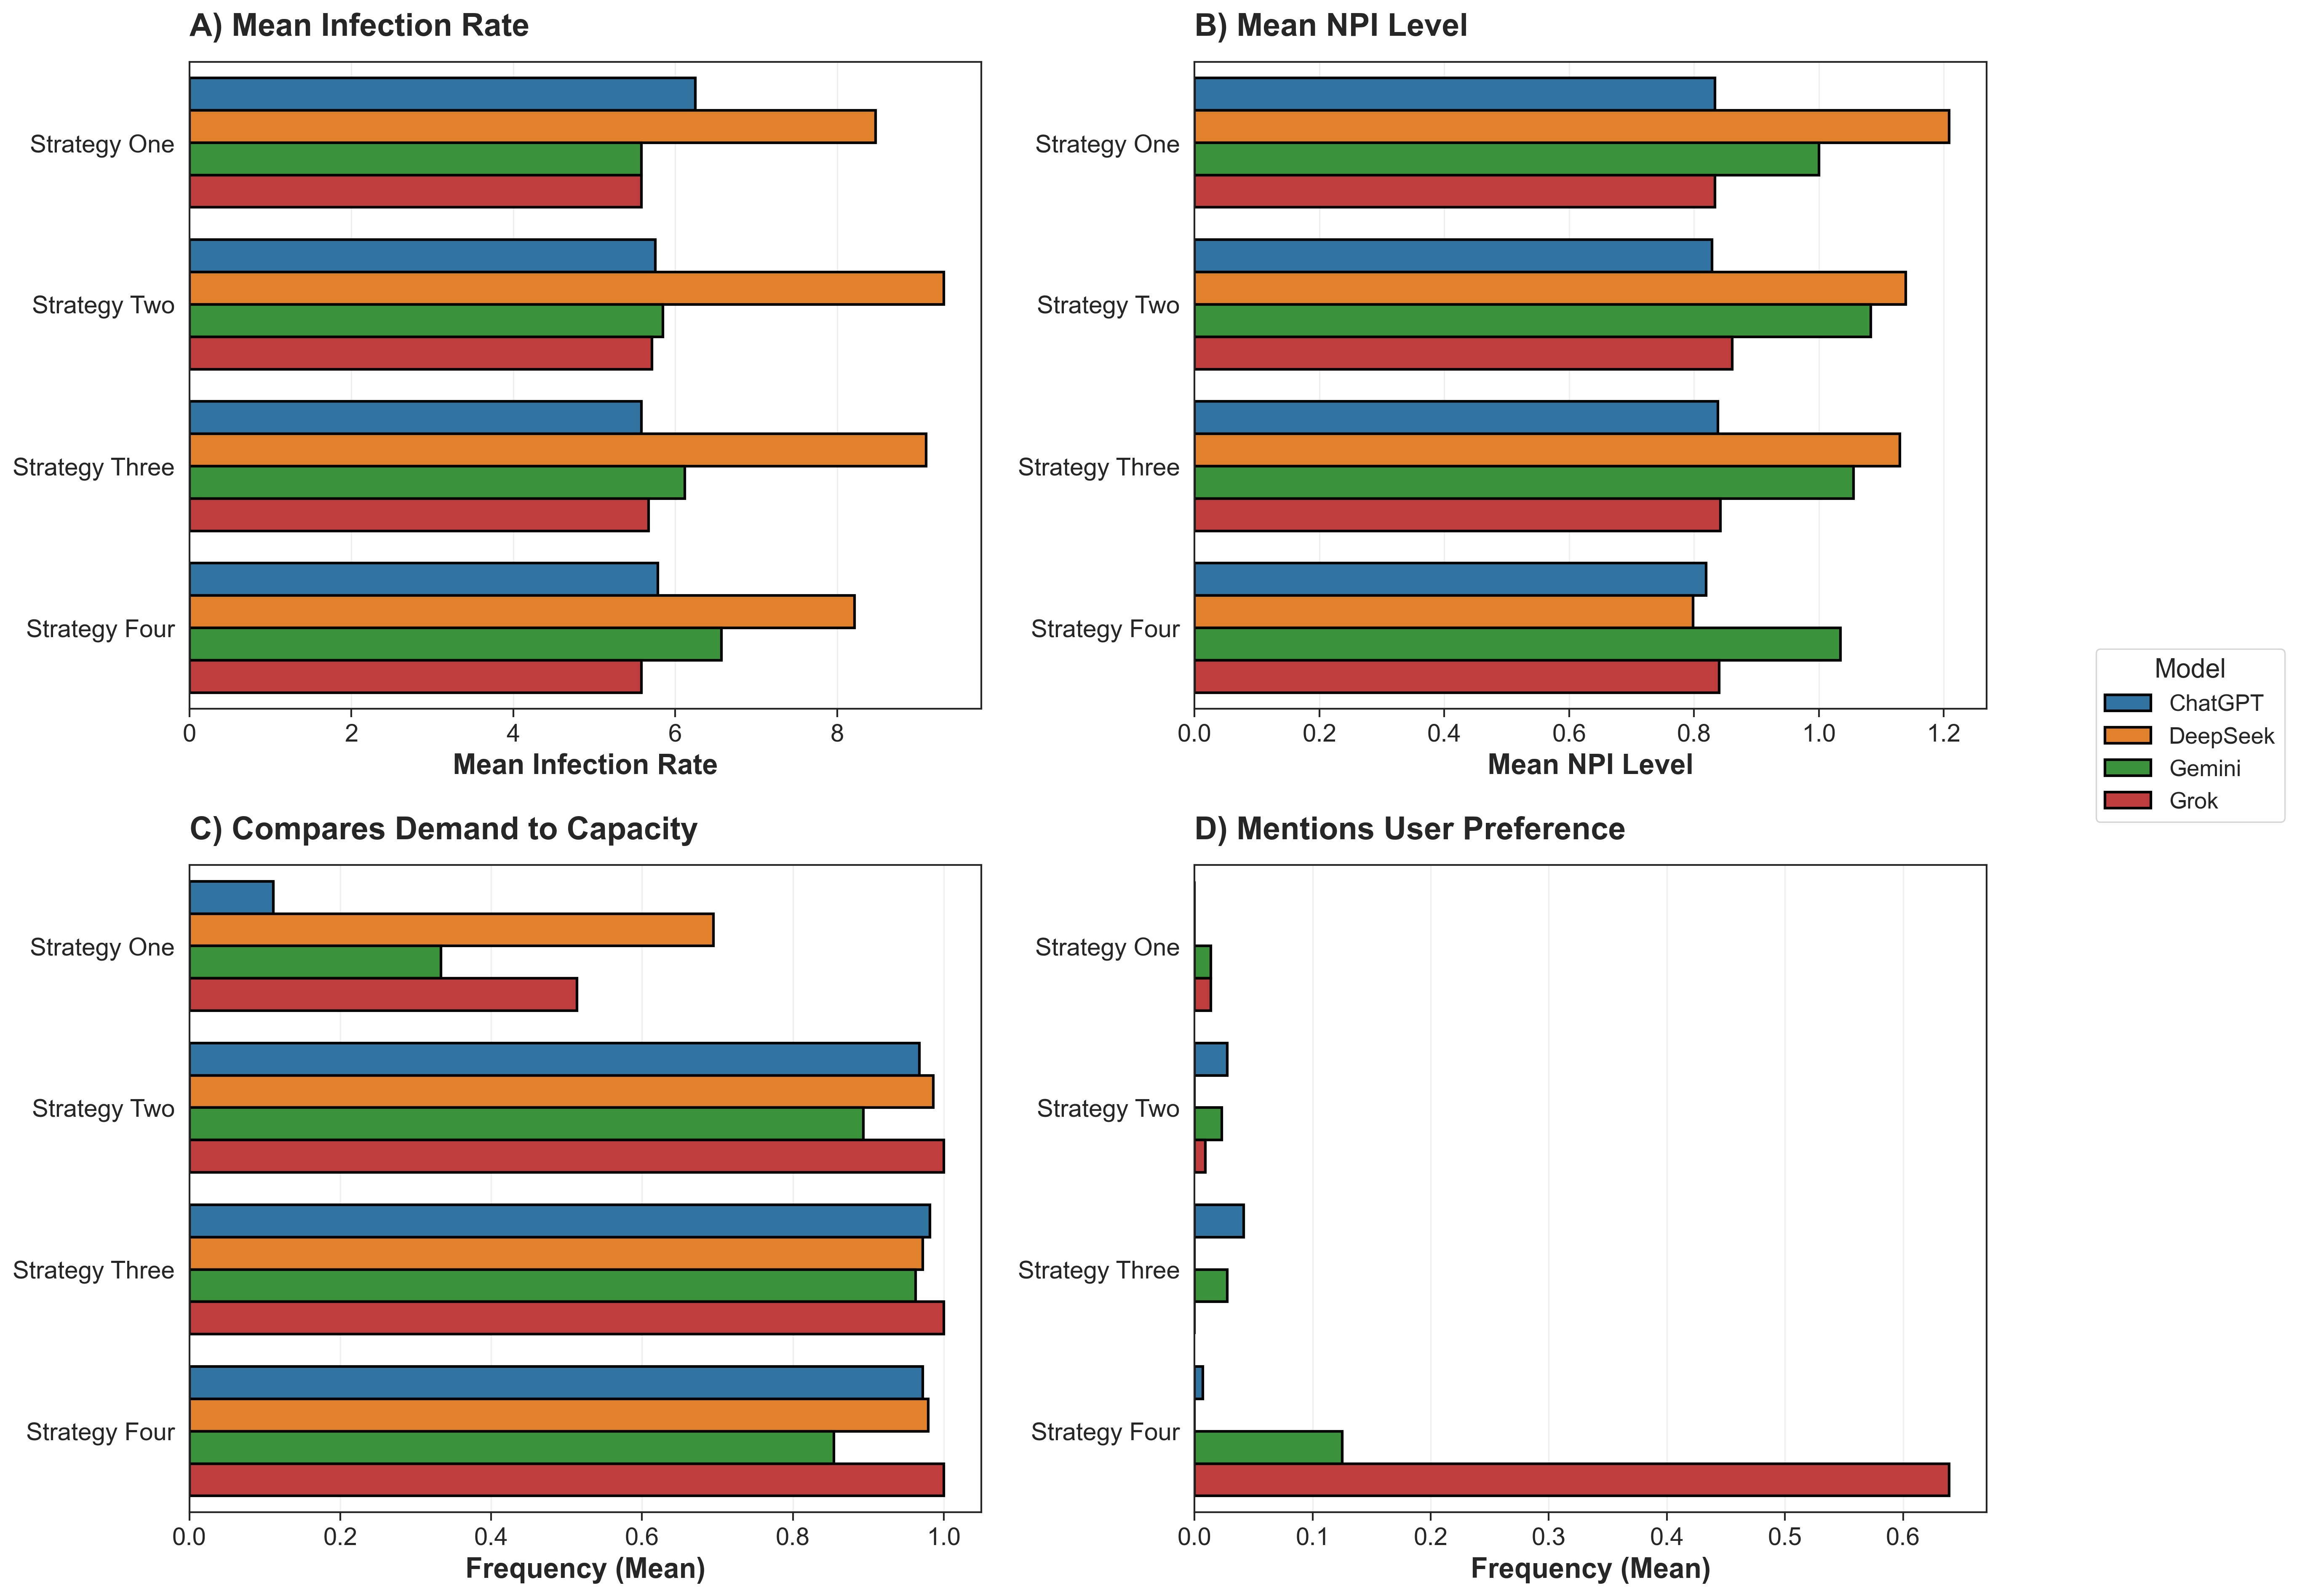

In [22]:
# ---- 4-panel figure for strategies 1–4 (all bar plots; A/B/C/D hue=model) ----
if (not results_df.empty) and (not reasoning_df.empty):

    keep_strategies = ['strategy_one', 'strategy_two', 'strategy_three', 'strategy_four']
    plot_results = results_df[results_df['strategy'].isin(keep_strategies)].copy()
    plot_reasoning = reasoning_df[reasoning_df['strategy'].isin(keep_strategies)].copy()

    strategies_sorted = [s for s in keep_strategies if s in plot_results['strategy'].unique()]

    # Ensure consistent model order
    models_sorted = sorted(plot_results['model'].unique())

    fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE_MULTI)
    axes = axes.flatten()

    # ----------------
    # Panel A: Mean infection rate by strategy, hue=model
    # ----------------
    axA = axes[0]
    sns.barplot(
        data=plot_results,
        x='infection_rate_selected',
        y='strategy',
        hue='model',
        order=strategies_sorted,
        hue_order=models_sorted,
        palette=MODEL_COLORS,
        orient='h',
        errorbar=None,
        ax=axA,
        edgecolor='black',
        linewidth=1.5
    )
    axA.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
    axA.grid(axis='x', alpha=0.3)
    axA.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
    axA.tick_params(axis='y', labelsize=14, labelleft=True)
    axA.set_xlabel('Mean Infection Rate', fontsize=16, fontweight='bold')
    axA.set_ylabel('')
    axA.set_title('A) Mean Infection Rate', fontsize=18, fontweight='bold', loc='left', pad=15)

    # Remove axis legend; we will add a single figure legend
    if axA.get_legend():
        axA.get_legend().remove()

    # ----------------
    # Panel B: Mean NPI level by strategy, hue=model
    # ----------------
    axB = axes[1]
    sns.barplot(
        data=plot_results,
        x='npi_level_selected',
        y='strategy',
        hue='model',
        order=strategies_sorted,
        hue_order=models_sorted,
        palette=MODEL_COLORS,
        orient='h',
        errorbar=None,
        ax=axB,
        edgecolor='black',
        linewidth=1.5
    )
    axB.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
    axB.grid(axis='x', alpha=0.3)
    axB.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
    axB.tick_params(axis='y', labelsize=14, labelleft=True)
    axB.set_xlabel('Mean NPI Level', fontsize=16, fontweight='bold')
    axB.set_ylabel('')
    axB.set_title('B) Mean NPI Level', fontsize=18, fontweight='bold', loc='left', pad=15)

    if axB.get_legend():
        axB.get_legend().remove()

    # ----------------
    # Panel C: compares_demand_to_capacity by strategy, hue=model
    # ----------------
    axC = axes[2]
    sns.barplot(
        data=plot_reasoning,
        x='compares_demand_to_capacity',
        y='strategy',
        hue='model',
        order=strategies_sorted,
        hue_order=models_sorted,
        palette=MODEL_COLORS,
        orient='h',
        errorbar=None,
        ax=axC,
        edgecolor='black',
        linewidth=1.5
    )
    axC.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
    axC.grid(axis='x', alpha=0.3)
    axC.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
    axC.tick_params(axis='y', labelsize=14, labelleft=True)
    axC.set_xlabel('Frequency (Mean)', fontsize=16, fontweight='bold')
    axC.set_ylabel('')
    axC.set_title('C) Compares Demand to Capacity', fontsize=18, fontweight='bold', loc='left', pad=15)

    if axC.get_legend():
        axC.get_legend().remove()

    # ----------------
    # Panel D: short_term_economic_reasoning by strategy, hue=model
    # ----------------
    col = 'mentions_user_preference'
    axD = axes[3]
    sns.barplot(
        data=plot_reasoning,
        x=col,
        y='strategy',
        hue='model',
        order=strategies_sorted,
        hue_order=models_sorted,
        palette=MODEL_COLORS,
        orient='h',
        errorbar=None,
        ax=axD,
        edgecolor='black',
        linewidth=1.5
    )
    axD.set_yticklabels([s.replace('_', ' ').title() for s in strategies_sorted], fontsize=16)
    axD.grid(axis='x', alpha=0.3)
    axD.tick_params(axis='x', labelsize=14, bottom=True, labelbottom=True)
    axD.tick_params(axis='y', labelsize=14, labelleft=True)
    axD.set_xlabel('Frequency (Mean)', fontsize=16, fontweight='bold')
    axD.set_ylabel('')
    axD.set_title('D) Mentions User Preference', fontsize=18, fontweight='bold', loc='left', pad=15)

    if axD.get_legend():
        axD.get_legend().remove()

    # ---- shared model legend (use handles from one of the seaborn plots) ----
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        title='Model',
        loc='center right',
        bbox_to_anchor=(1.02, 0.5),
        fontsize=13,
        title_fontsize=15,
        frameon=True
    )

    fig.suptitle('')
    plt.tight_layout(rect=[0, 0, 0.90, 0.95])
    plt.show()